# 🏈 What Wins in the NFL?
## A hands-on introduction to linear and logistic regression

In this notebook you will use real NFL data to answer three questions:

1. **Which stats explain how many points a team scores and allows?** (linear regression)
2. **Which stats explain how many games a team wins?** (linear regression)
3. **What is a team's chance of winning at any moment of a game, and which plays change it the most?** (logistic regression)

### Learning goals
By the end you should be able to:
* fit and interpret a **simple** and a **multiple linear regression**
* turn coefficients into a prediction **by hand**
* explain why we test a model on data it has **never seen**
* explain why a yes/no outcome needs **logistic regression**, and compute a probability from its coefficients
* explain why adding an **interaction** lets one input's effect depend on another
* explain what a **win-probability swing (WPA)** is and calculate one

### How to use this notebook
Run the cells **in order, from top to bottom** (Runtime → Run all works too). Look for these boxes:

| Icon | Meaning |
|---|---|
| 💡 | **Key idea**: the concept to remember |
| 🔍 | **Check your understanding**: answer in your head, then click to reveal |
| ✏️ | **Try it**: change a value in the cell and run it again |

### Roadmap
| Part | Topic | Method |
|---|---|---|
| 0 | Setup | |
| 1 | Building the dataset | data cleaning |
| 2 | Exploring the data | scatter plots, correlation |
| 3 | One stat, one line | simple linear regression |
| 4 | Many stats at once | multiple linear regression |
| 5 | From points to wins | regression on win % |
| 6 | Win probability, built from scratch | counting → **logistic regression** |
| 7 | The most important plays | win-probability swings from our model |
| 8 | The 2026 season so far | applying the models |
| 9 | Limitations and exercises | |

## Part 0 · Setup

This installs the data package ([nflverse](https://github.com/nflverse)) and loads the Python libraries we use. It takes about 30 seconds the first time.

In [1]:
!pip -q install nflreadpy pyarrow statsmodels

import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

FIRST_SEASON   = 2010
CURRENT_SEASON = 2026        # partial season, used only at the end
TEST_SEASONS   = [2024, 2025]  # held out to check out-of-sample accuracy
SEASONS = list(range(FIRST_SEASON, CURRENT_SEASON + 1))

### Team colors and logos
These helper functions put team logos and colors on our charts. You don't need to understand this code. Logos are transparent PNGs with a thin white outline, like TV graphics. If a logo can't load, the chart shows a team-colored circle instead.

In [2]:
import io, urllib.request
from PIL import Image, ImageFilter
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from IPython.display import display, HTML

TEAM = nfl.load_teams().to_pandas().drop_duplicates("team_abbr").set_index("team_abbr")
COLOR  = TEAM.team_color.to_dict()     # primary color, e.g. COLOR["KC"] -> "#E31837"
COLOR2 = TEAM.team_color2.to_dict()    # secondary color
LOGO_URL = TEAM.team_logo_espn.to_dict()   # transparent PNG logos
LOGO_PX = 240                              # load logos at high resolution so they stay crisp
_logos = {}

def _white_outline(img, width=6):
    """Add a thin white outline around a transparent logo, like TV broadcast graphics."""
    pad = width * 2
    canvas = Image.new("RGBA", (img.width + 2 * pad, img.height + 2 * pad), (0, 0, 0, 0))
    canvas.paste(img, (pad, pad), img)
    grown = canvas.split()[3].filter(ImageFilter.MaxFilter(2 * width + 1))       # alpha mask, made fatter
    outline = Image.new("RGBA", canvas.size, (255, 255, 255, 255))
    outline.putalpha(grown.point(lambda a: 255 if a > 40 else 0))
    outline.alpha_composite(canvas)                                              # logo on top of the outline
    return outline

def get_logo(team):
    """Download a team logo once, cache it, and return it as a PIL image (or None)."""
    if team not in _logos:
        _logos[team] = None
        backup = (TEAM.at[team, "team_logo_squared"]
                  .replace("https://github.com/", "https://raw.githubusercontent.com/").replace("/raw/", "/"))
        for url in [TEAM.at[team, "team_logo_espn"], backup]:
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                img = Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=10).read())).convert("RGBA")
                img.thumbnail((LOGO_PX, LOGO_PX), Image.LANCZOS)
                _logos[team] = _white_outline(img)
                break
            except Exception:
                pass
    return _logos[team]

def add_logo(ax, team, x, y, zoom=0.28):
    """Place a team logo on a matplotlib chart at data coordinates (x, y)."""
    img = get_logo(team)
    if img is None:   # fallback: team-colored dot with the abbreviation
        ax.scatter(x, y, s=420, color=COLOR.get(team, "gray"), edgecolor="white", zorder=3)
        ax.annotate(team, (x, y), ha="center", va="center", color="white", fontsize=7, weight="bold", zorder=4)
    else:
        size_fix = 120 / LOGO_PX   # keeps logos the same size on screen, just sharper
        ax.add_artist(AnnotationBbox(OffsetImage(img, zoom=zoom * size_fix), (x, y), frameon=False, zorder=3))

def logo_html(team, width=30):
    return (f'<img src="{LOGO_URL.get(team, "")}" width="{width}" '
            f'style="vertical-align:middle;filter:drop-shadow(0 0 1px white) drop-shadow(0 1px 2px rgba(0,0,0,.35))">')

print("Loaded colors/logos for", len(TEAM), "team codes")

Loaded colors/logos for 36 team codes


## Part 1 · Building the dataset

Every row of our final dataset will be one **team-season**, for example *the 2023 Ravens*. Why seasons and not single games? One game is noisy: a tipped interception can swing 14 points. Over a full season that luck mostly averages out, so the numbers describe what a team **is**.

### Step 1: Load game-by-game stats and final scores

In [3]:
games = nfl.load_team_stats(seasons=SEASONS, summary_level="week").to_pandas()
games = games[games["season_type"] == "REG"].copy()

sched = nfl.load_schedules(seasons=SEASONS).to_pandas()
sched = sched[(sched["game_type"] == "REG") & sched["home_score"].notna()].copy()

print("Team-game rows:", len(games))
print("Completed games:", len(sched))
print("Latest 2026 week with results:", int(sched.loc[sched.season == CURRENT_SEASON, "week"].max()))

Team-game rows: 8652
Completed games: 4326
Latest 2026 week with results: 11


### Step 2: Get each team's **defensive** stats
A team's defense stats are just its **opponent's offense** stats in the same game. So we match every row with the opposing team's row and add the prefix `opp_`.

Example: if the 49ers' opponent threw for 180 yards, then `opp_passing_yards = 180` on the 49ers' row means *the 49ers' defense allowed 180 passing yards*.

In [4]:
raw_cols = [
    "attempts", "completions", "passing_yards", "sack_yards_lost", "sacks_suffered",
    "passing_interceptions", "carries", "rushing_yards",
    "sack_fumbles_lost", "rushing_fumbles_lost", "receiving_fumbles_lost",
    "passing_first_downs", "rushing_first_downs", "penalty_yards",
]

opp = games[["game_id", "team"] + raw_cols].rename(
    columns={"team": "opponent_team", **{c: f"opp_{c}" for c in raw_cols}}
)

games = games.merge(opp, on=["game_id", "opponent_team"], how="inner")
games[["team", "opponent_team", "week", "passing_yards", "opp_passing_yards"]].head()

,team,opponent_team,week,passing_yards,opp_passing_yards
0,ARI,LA,1,297,253
1,ATL,PIT,1,252,236
2,BAL,NYJ,1,248,74
3,BUF,MIA,1,139,182
4,CAR,NYG,1,182,263


### Step 3: Add points scored and allowed
A small cleanup is hidden in here: older seasons use old codes for teams that moved (OAK → LV, SD → LAC, STL → LA). Without fixing them, those teams would silently disappear.

In [5]:
relocated = {"OAK": "LV", "SD": "LAC", "STL": "LA"}
sched["home_team"] = sched["home_team"].replace(relocated)
sched["away_team"] = sched["away_team"].replace(relocated)

home = sched[["game_id", "home_team", "home_score", "away_score"]].rename(
    columns={"home_team": "team", "home_score": "pts_for", "away_score": "pts_against"})
away = sched[["game_id", "away_team", "away_score", "home_score"]].rename(
    columns={"away_team": "team", "away_score": "pts_for", "home_score": "pts_against"})
scores = pd.concat([home, away], ignore_index=True)

scores["win"] = np.select(
    [scores.pts_for > scores.pts_against, scores.pts_for == scores.pts_against],
    [1.0, 0.5], default=0.0)  # ties count as half a win

games = games.merge(scores, on=["game_id", "team"], how="inner")
print(games.shape)
assert games.groupby("season").team.nunique().eq(32).all(), "a team is missing from some season"

(8652, 155)


### Step 4: Add up each season and compute the stats we'll use

| Offense stat | What it means | Defense version |
|---|---|---|
| `off_ny_a` | **Net yards per pass attempt** = (pass yards − sack yards) ÷ (attempts + sacks) | `def_ny_a`: allowed |
| `off_ypc` | **Yards per carry** (rushing) | `def_ypc`: allowed |
| `off_to_pg` | **Giveaways per game**: interceptions + fumbles lost | `def_to_pg`: **takeaways** per game |
| `off_sack_rate` | Share of dropbacks that end in a **sack** | `def_sack_rate`: sacks **made** |
| `off_fd_pg` | **First downs** per game | `def_fd_pg`: allowed |
| `off_pen_ypg` | **Penalty yards** per game | |

The things we want to explain (**outcomes**): `ppg` (points scored per game), `papg` (points allowed per game), `diff_pg` (point differential per game) and `win_pct`.

💡 **Key idea:** we leave out touchdowns and field goals on purpose. They *are* points, so "predicting" points with them would be circular. We want the stats that **lead to** points.

In [6]:
sum_cols = raw_cols + [f"opp_{c}" for c in raw_cols] + ["pts_for", "pts_against", "win"]

season = (games.groupby(["season", "team"])
               .agg(games=("game_id", "nunique"), **{c: (c, "sum") for c in sum_cols})
               .reset_index())

g = season["games"]

# ---------- Offense ----------
season["off_ny_a"]      = (season.passing_yards + season.sack_yards_lost) / (season.attempts + season.sacks_suffered)
season["off_ypc"]       = season.rushing_yards / season.carries
season["off_to_pg"]     = (season.passing_interceptions + season.sack_fumbles_lost
                           + season.rushing_fumbles_lost + season.receiving_fumbles_lost) / g
season["off_sack_rate"] = season.sacks_suffered / (season.attempts + season.sacks_suffered)
season["off_fd_pg"]     = (season.passing_first_downs + season.rushing_first_downs) / g
season["off_pen_ypg"]   = season.penalty_yards / g

# ---------- Defense (what opponents did against this team) ----------
season["def_ny_a"]      = (season.opp_passing_yards + season.opp_sack_yards_lost) / (season.opp_attempts + season.opp_sacks_suffered)
season["def_ypc"]       = season.opp_rushing_yards / season.opp_carries
season["def_to_pg"]     = (season.opp_passing_interceptions + season.opp_sack_fumbles_lost
                           + season.opp_rushing_fumbles_lost + season.opp_receiving_fumbles_lost) / g
season["def_sack_rate"] = season.opp_sacks_suffered / (season.opp_attempts + season.opp_sacks_suffered)
season["def_fd_pg"]     = (season.opp_passing_first_downs + season.opp_rushing_first_downs) / g

# ---------- Outcomes ----------
season["ppg"]      = season.pts_for / g        # points scored per game
season["papg"]     = season.pts_against / g    # points allowed per game
season["diff_pg"]  = season.ppg - season.papg  # point differential per game
season["win_pct"]  = season.win / g

OFF = ["off_ny_a", "off_ypc", "off_to_pg", "off_sack_rate", "off_fd_pg", "off_pen_ypg"]
DEF = ["def_ny_a", "def_ypc", "def_to_pg", "def_sack_rate", "def_fd_pg"]

full    = season[season.season <  CURRENT_SEASON].copy()   # complete seasons
current = season[season.season == CURRENT_SEASON].copy()   # 2026 so far

print(f"Complete team-seasons: {len(full)}  ({full.season.min()}–{full.season.max()})")
full[["season", "team", "games"] + OFF + ["ppg"]].sort_values("ppg", ascending=False).head(10)

Complete team-seasons: 512  (2010–2025)


,season,team,games,off_ny_a,off_ypc,off_to_pg,off_sack_rate,off_fd_pg,off_pen_ypg,ppg
105,2013,DEN,16,7.833,4.063,1.312,0.029,25.000,62.500,37.875
271,2018,KC,16,8.136,4.793,1.125,0.043,21.688,72.000,35.312
43,2011,GB,16,8.306,3.944,0.688,0.069,19.938,36.938,35.000
85,2012,NE,16,6.979,4.176,0.938,0.040,25.438,52.500,34.812
54,2011,NO,16,7.846,4.952,1.188,0.035,24.938,53.188,34.188
193,2016,ATL,16,8.232,4.580,0.688,0.064,21.688,52.938,33.750
290,2019,BAL,16,6.891,5.530,0.875,0.060,22.438,54.188,33.188
458,2024,DET,17,7.661,4.659,0.882,0.057,22.706,57.235,33.176
272,2018,LA,16,7.499,4.861,1.125,0.055,23.125,54.875,32.938
21,2010,NE,16,7.231,4.346,0.562,0.047,19.688,47.875,32.375


> 🔍 **Check your understanding:** Why do we add up yards and attempts over the whole season first, and only *then* divide, instead of averaging each game's yards per attempt?

<details><summary><b>Click to reveal the answer</b></summary>

Averaging game rates gives a 10-attempt game the same weight as a 50-attempt game. Dividing season totals weights every attempt equally.

</details>

### Step 5: Check the data
Good analysts check their data before modeling. This should print **0**, **[32]**, **[16, 17]** and **True**.

In [7]:
official = nfl.load_team_stats(seasons=list(range(FIRST_SEASON, CURRENT_SEASON)), summary_level="reg").to_pandas()
check_cols = ["attempts", "passing_yards", "sack_yards_lost", "sacks_suffered", "passing_interceptions",
              "carries", "rushing_yards", "passing_first_downs", "rushing_first_downs", "penalty_yards"]
diff = (full.set_index(["season", "team"])[check_cols]
        - official.set_index(["season", "team"])[check_cols]).abs().max()
print("Largest difference vs. official season totals:", int(diff.max()))
print("Teams per season:", full.groupby("season").team.nunique().unique())
print("Games per team-season:", sorted(full.games.unique()))
print("Points scored == points allowed league-wide:",
      bool((full.groupby("season").pts_for.sum() == full.groupby("season").pts_against.sum()).all()))

Largest difference vs. official season totals: 0
Teams per season: [32]
Games per team-season: [np.int64(16), np.int64(17)]
Points scored == points allowed league-wide: True


## Part 2 · Exploring the data

Before fitting any model, **look at the data**. Each dot below is one team-season. The number in each title is the **correlation** *r*: how tightly the dots follow a straight line, from −1 (perfect downhill) through 0 (no pattern) to +1 (perfect uphill).

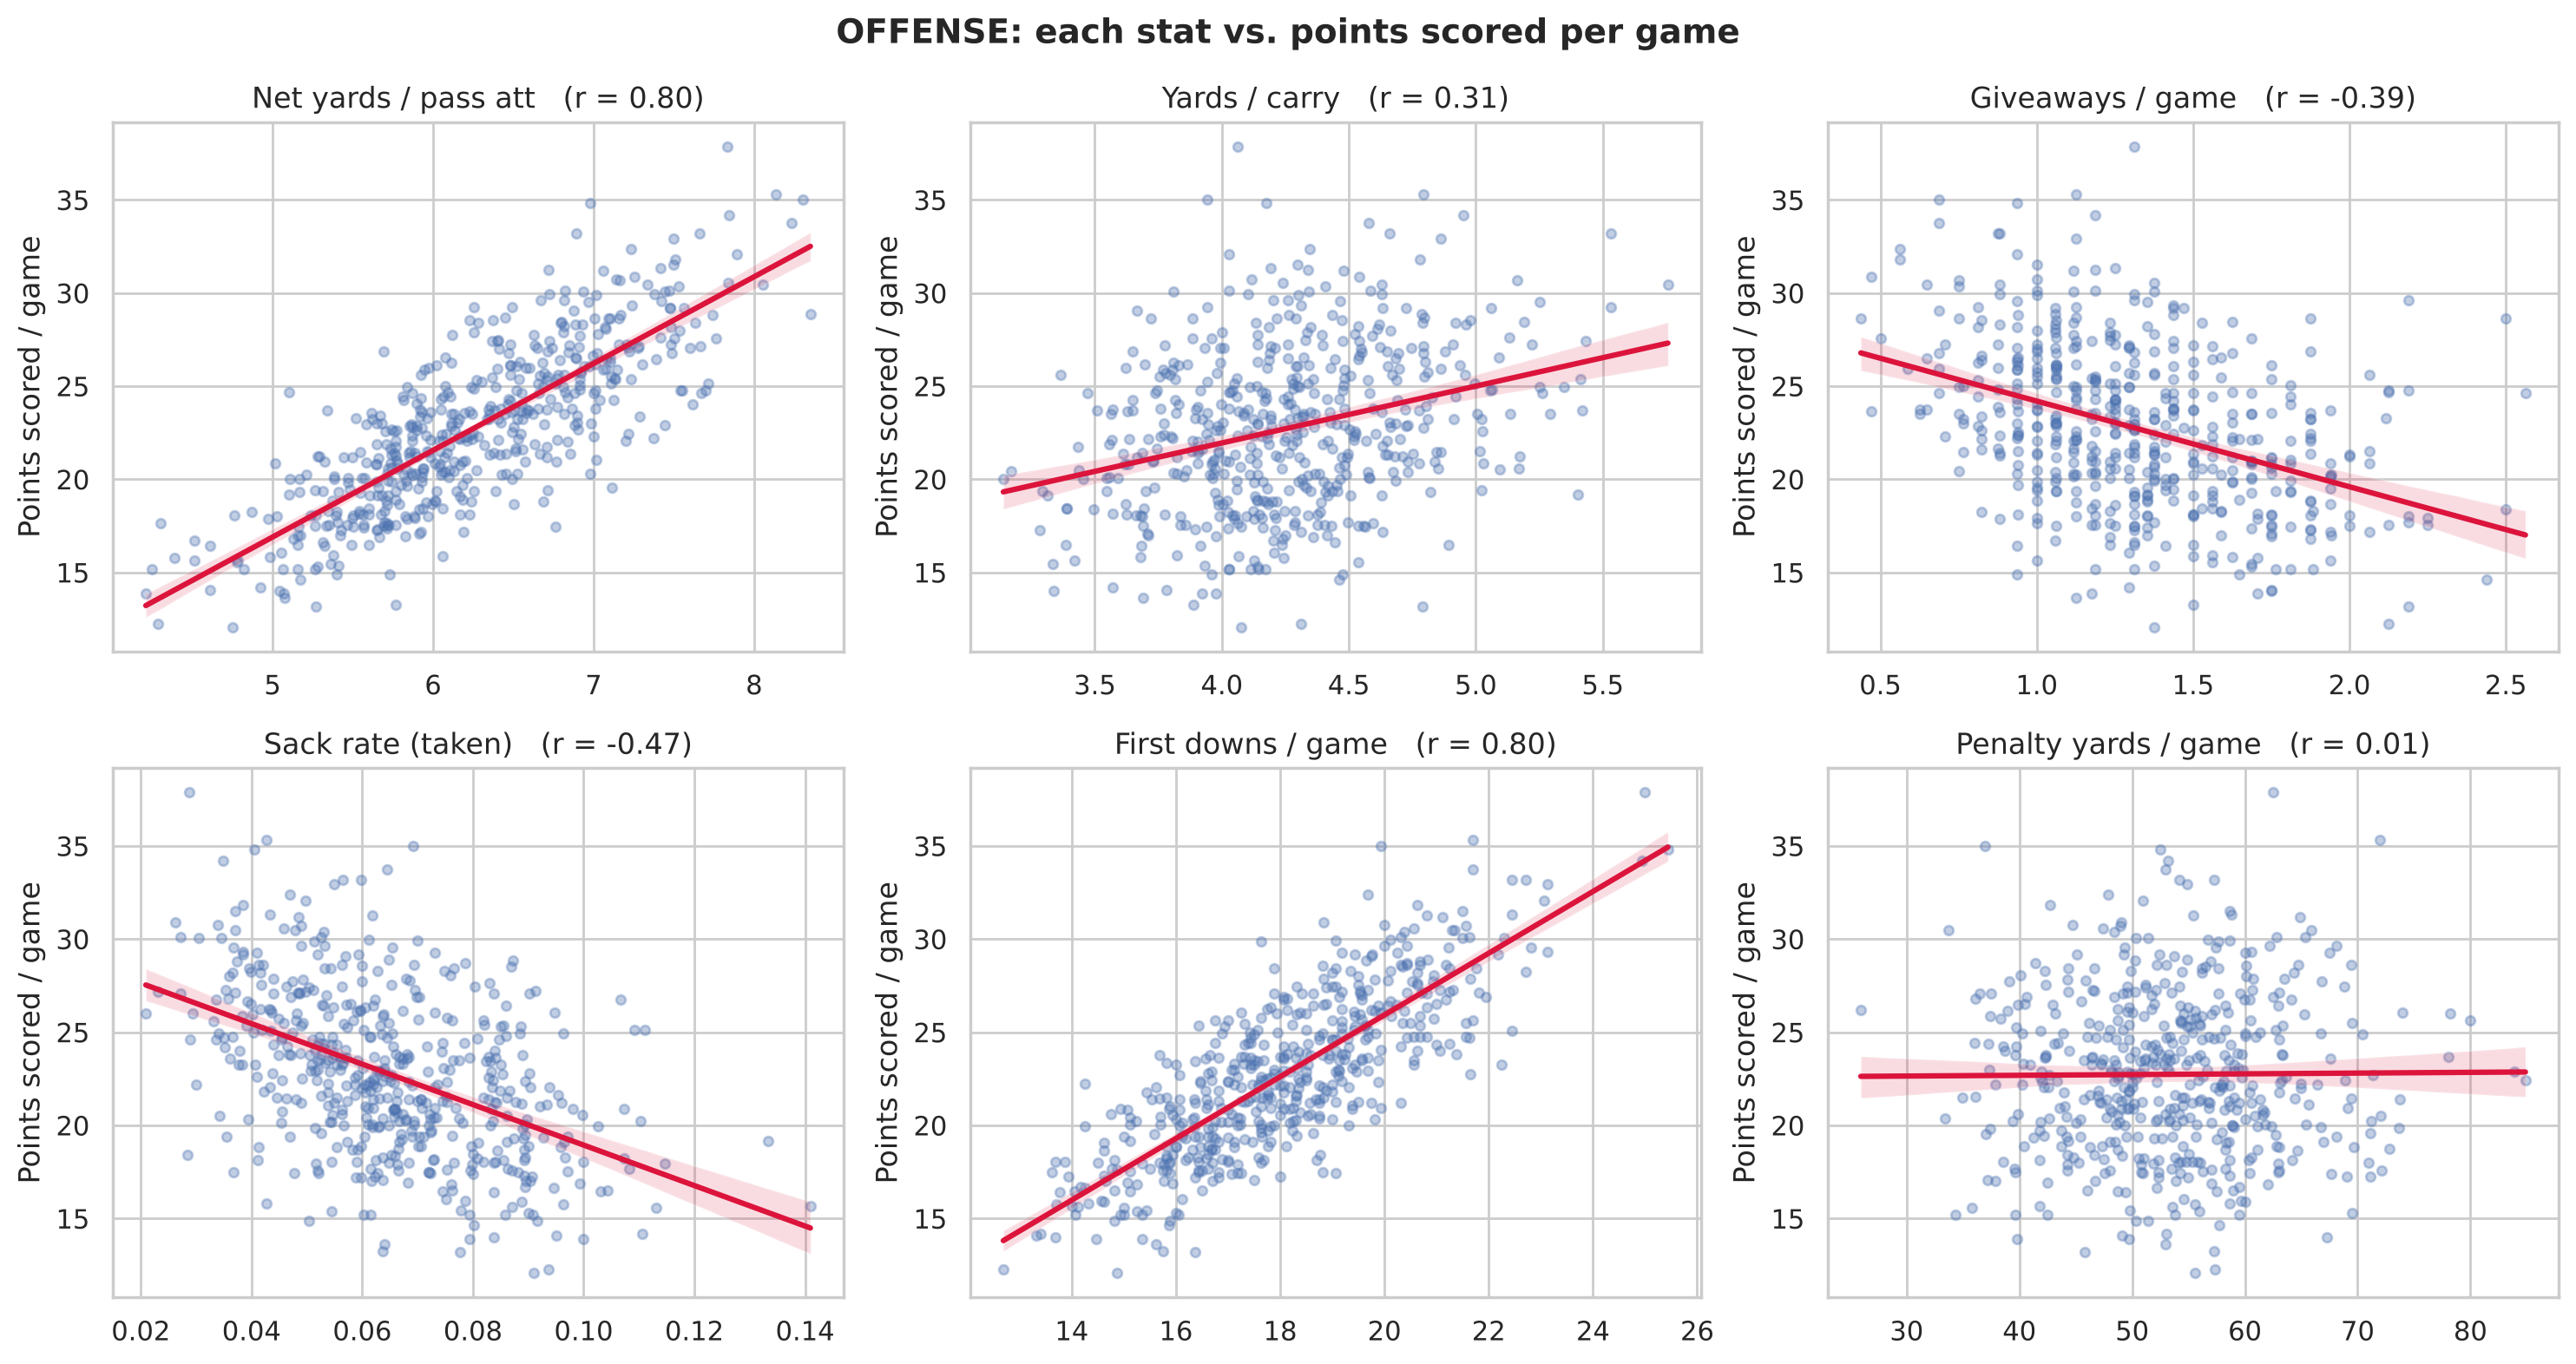

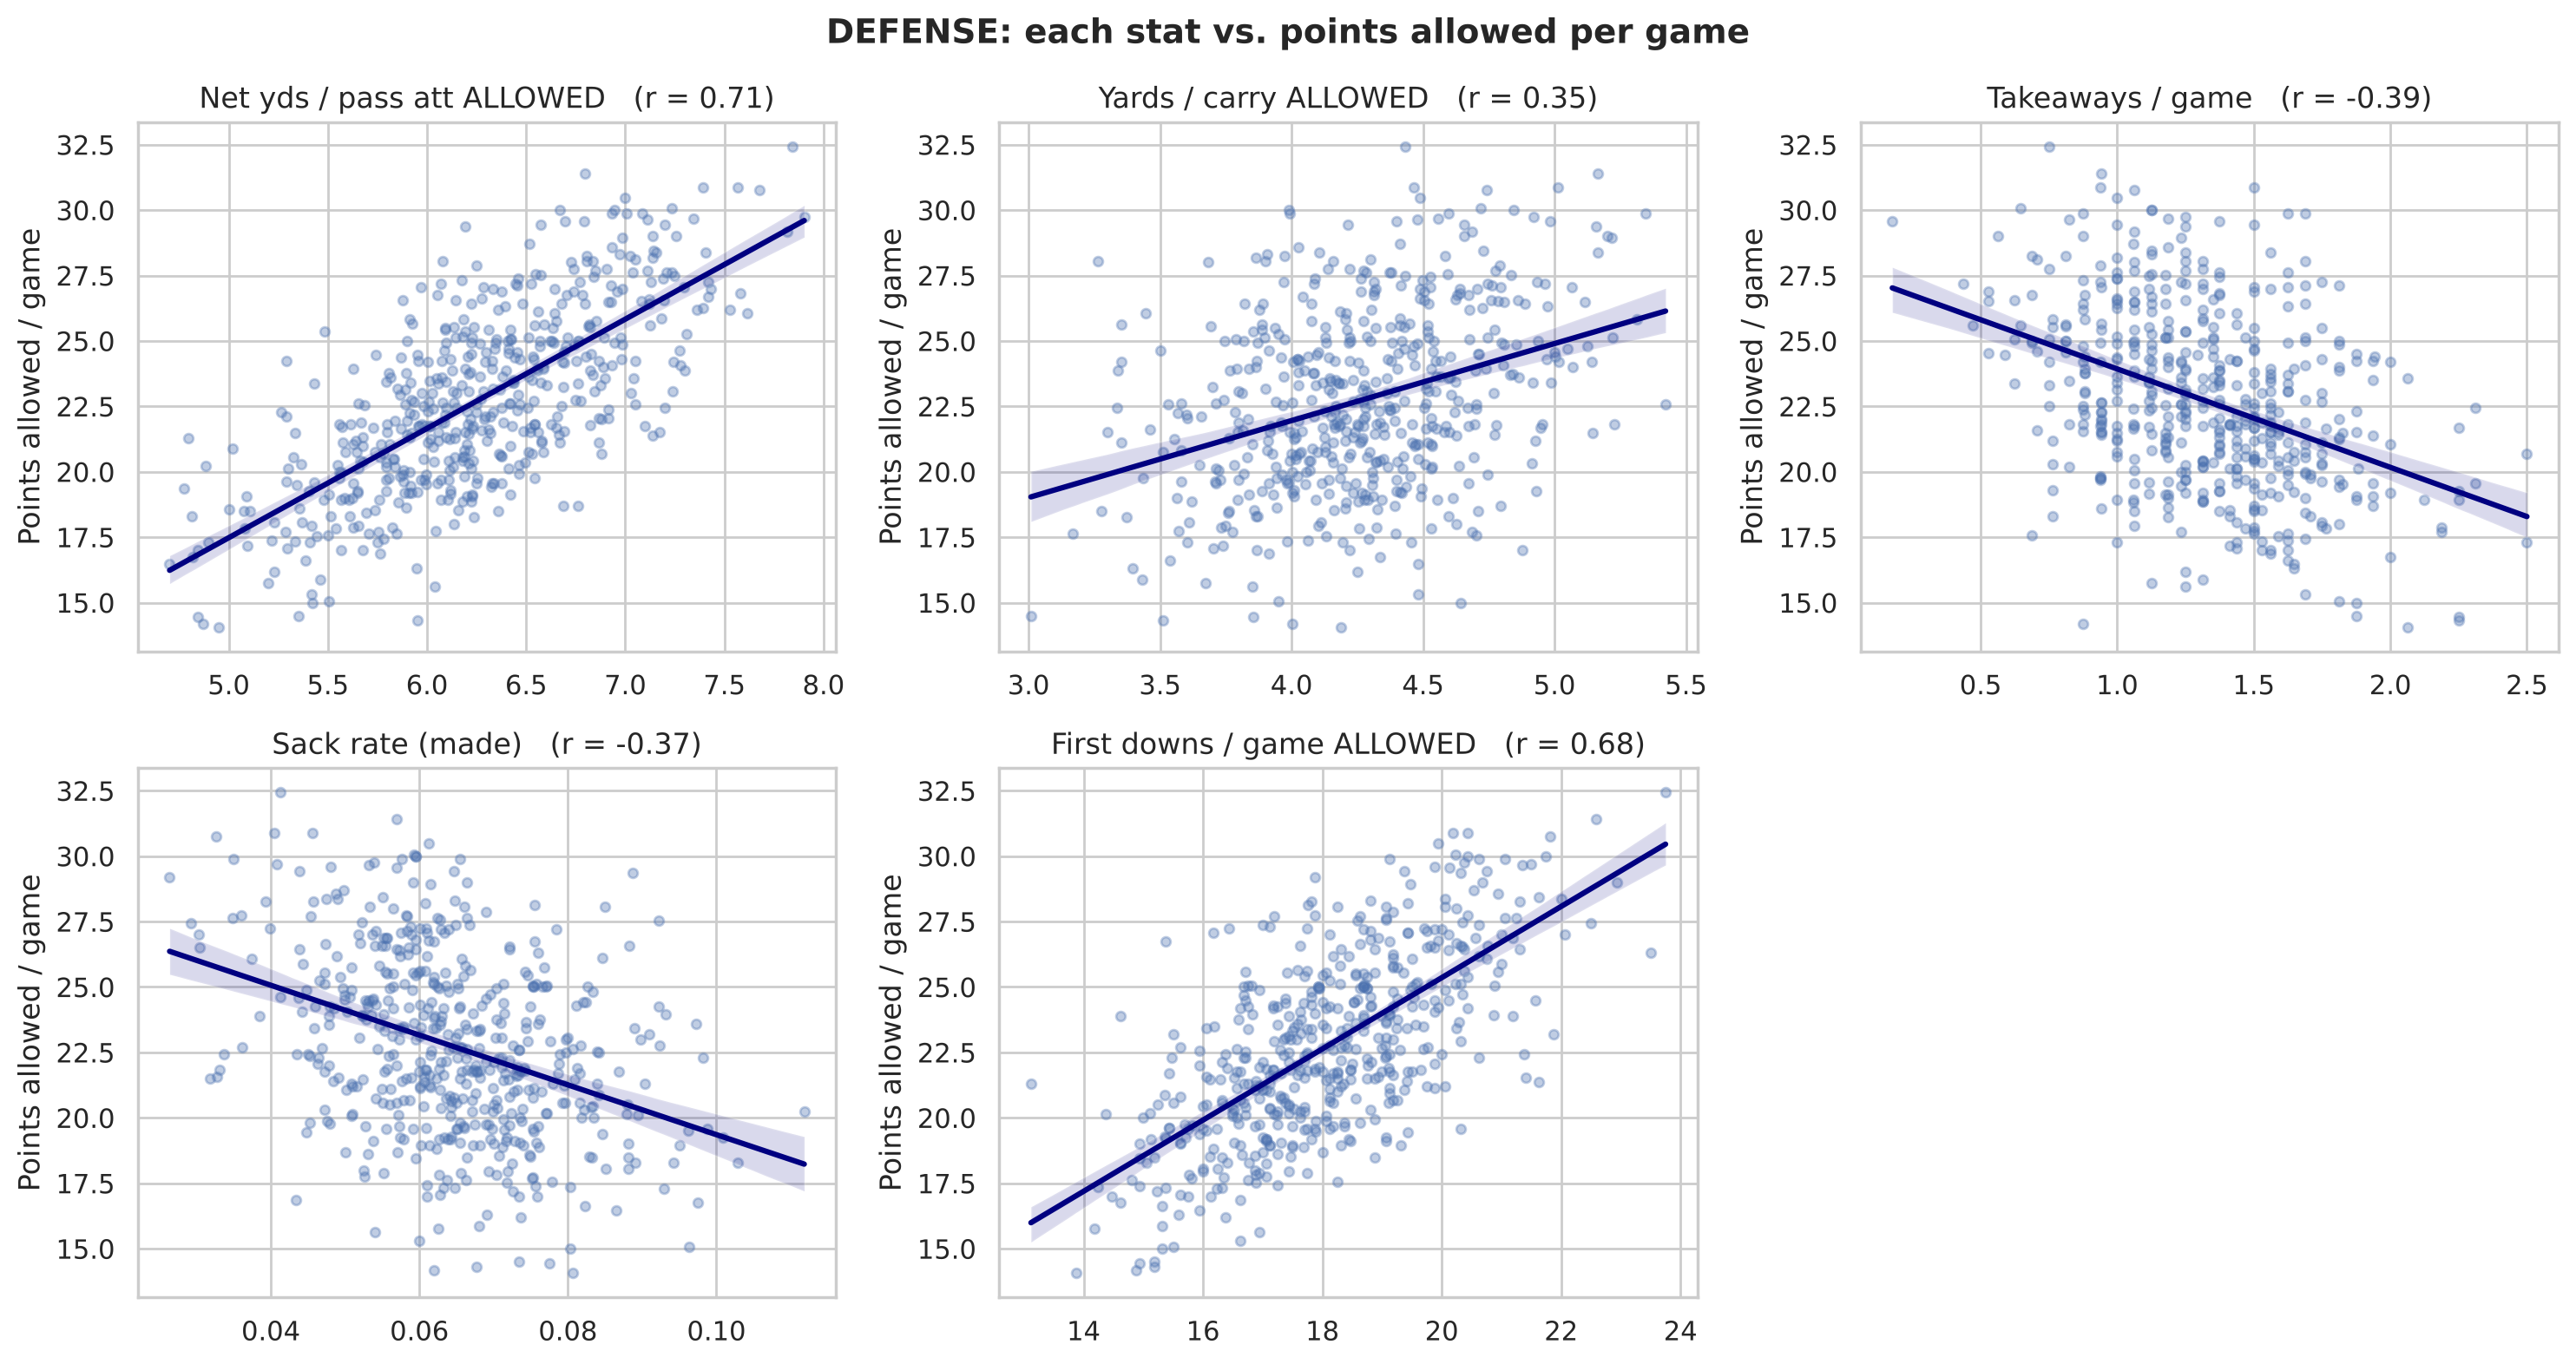

In [8]:
labels = {
    "off_ny_a": "Net yards / pass att", "off_ypc": "Yards / carry",
    "off_to_pg": "Giveaways / game", "off_sack_rate": "Sack rate (taken)",
    "off_fd_pg": "First downs / game", "off_pen_ypg": "Penalty yards / game",
    "def_ny_a": "Net yds / pass att ALLOWED", "def_ypc": "Yards / carry ALLOWED",
    "def_to_pg": "Takeaways / game", "def_sack_rate": "Sack rate (made)",
    "def_fd_pg": "First downs / game ALLOWED",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, OFF):
    sns.regplot(data=full, x=col, y="ppg", ax=ax, scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "crimson"})
    r = full[[col, "ppg"]].corr().iloc[0, 1]
    ax.set(title=f"{labels[col]}   (r = {r:.2f})", xlabel="", ylabel="Points scored / game")
fig.suptitle("OFFENSE: each stat vs. points scored per game", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, DEF):
    sns.regplot(data=full, x=col, y="papg", ax=ax, scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "navy"})
    r = full[[col, "papg"]].corr().iloc[0, 1]
    ax.set(title=f"{labels[col]}   (r = {r:.2f})", xlabel="", ylabel="Points allowed / game")
axes.flat[-1].axis("off")
fig.suptitle("DEFENSE: each stat vs. points allowed per game", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Which offensive stat has the strongest relationship with points scored? Which one slopes *downward*, and why does that make sense?

<details><summary><b>Click to reveal the answer</b></summary>

Net yards per pass attempt has the strongest relationship (r ≈ 0.80). Giveaways per game slopes downward: turnovers end drives, so more of them means fewer points.

</details>

### League map: passing offense vs. passing defense
The same idea for one season, with logos. Teams in the **top-right** pass well **and** stop the pass well.

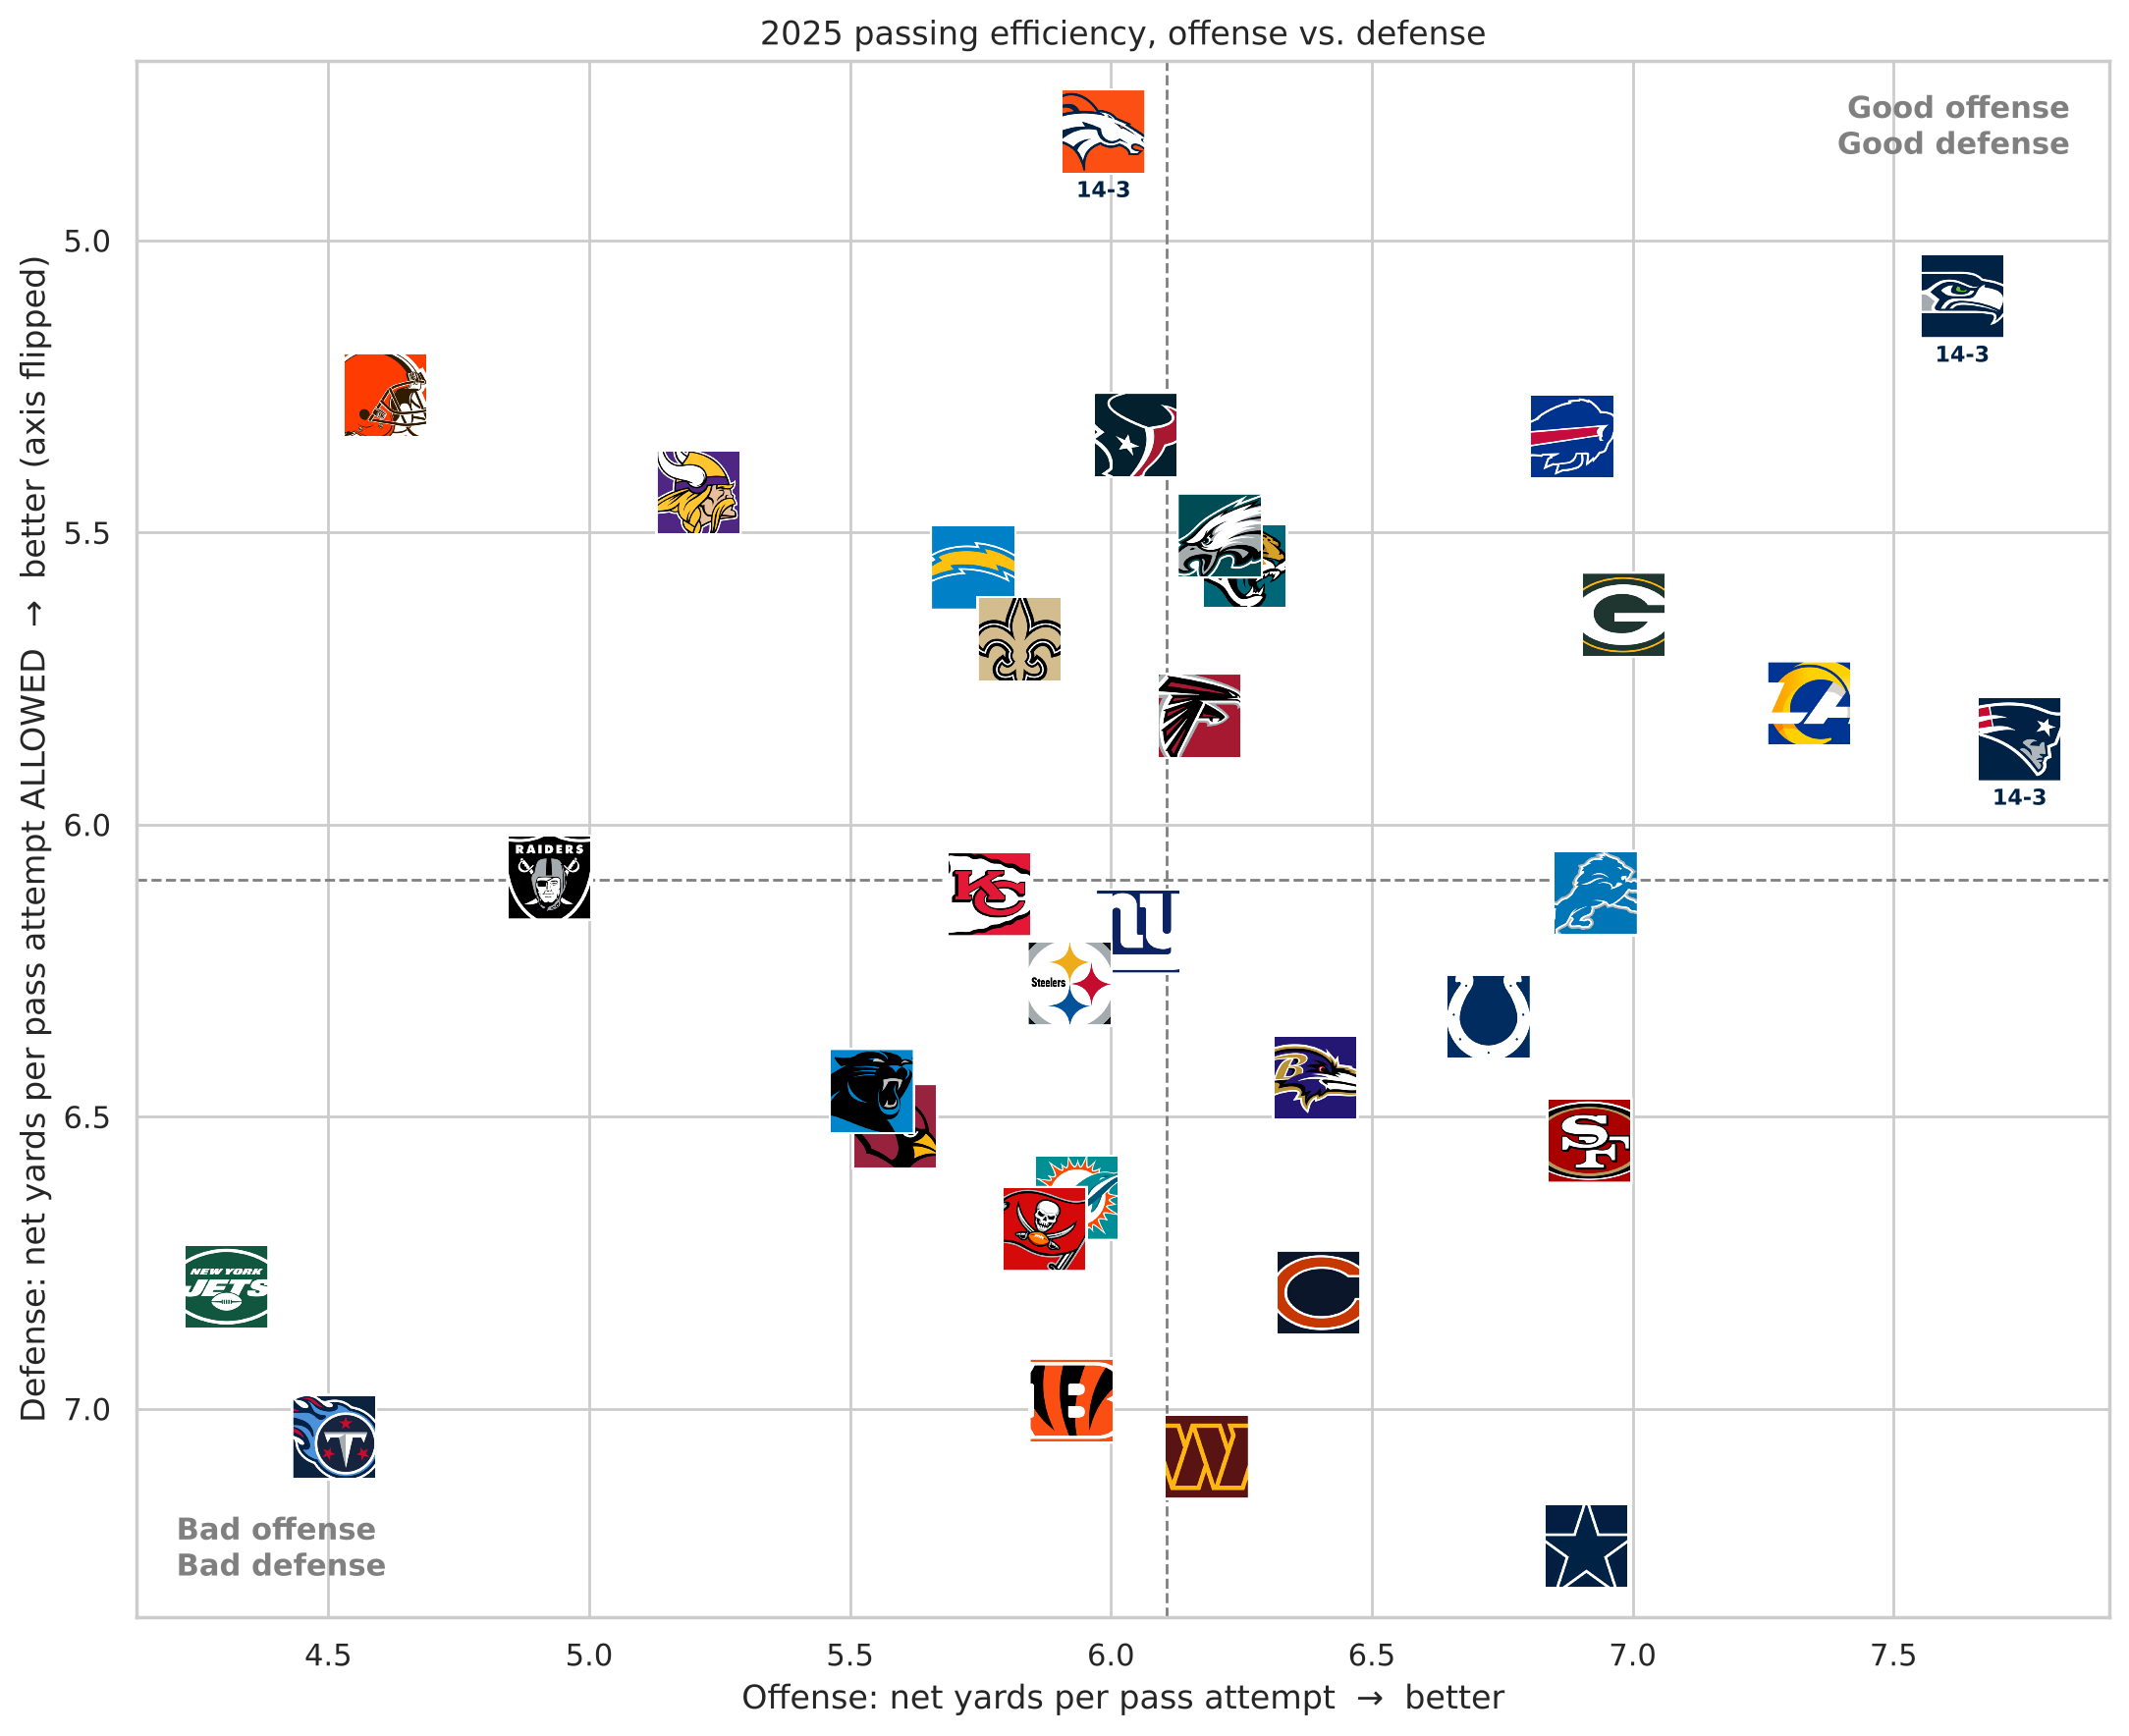

In [9]:
def record(season, team):
    """W-L (or W-L-T) record from game results."""
    w = games.loc[(games.season == season) & (games.team == team), "win"]
    W, L, T = (w == 1).sum(), (w == 0).sum(), (w == 0.5).sum()
    return f"{W}-{L}" + (f"-{T}" if T else "")

LAST_FULL = CURRENT_SEASON - 1
lm = full[full.season == LAST_FULL]

fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(lm.off_ny_a, lm.def_ny_a, alpha=0)            # sets the axis limits
for _, r in lm.iterrows():
    add_logo(ax, r.team, r.off_ny_a, r.def_ny_a, zoom=0.30)
ax.axvline(lm.off_ny_a.mean(), color="gray", ls="--", lw=1)
ax.axhline(lm.def_ny_a.mean(), color="gray", ls="--", lw=1)
ax.invert_yaxis()                                         # fewer yards allowed = higher on the chart
pad = dict(fontsize=11, color="gray", weight="bold")
ax.text(.98, .98, "Good offense\nGood defense", transform=ax.transAxes, ha="right", va="top", **pad)
ax.text(.02, .02, "Bad offense\nBad defense", transform=ax.transAxes, ha="left", va="bottom", **pad)
ax.set(xlabel="Offense: net yards per pass attempt  →  better",
       ylabel="Defense: net yards per pass attempt ALLOWED  →  better (axis flipped)",
       title=f"{LAST_FULL} passing efficiency, offense vs. defense")
for r in lm.nlargest(3, "win_pct").itertuples():
    ax.annotate(record(LAST_FULL, r.team), (r.off_ny_a, r.def_ny_a), xytext=(0, -24),
                textcoords="offset points", ha="center", fontsize=8, color=COLOR.get(r.team, "black"), weight="bold")
plt.tight_layout(); plt.show()

### Do the stats overlap?
If two stats measure nearly the same thing, a regression has trouble separating their effects (this is called **multicollinearity**). Look for big numbers *between* predictors, such as first downs and passing efficiency.

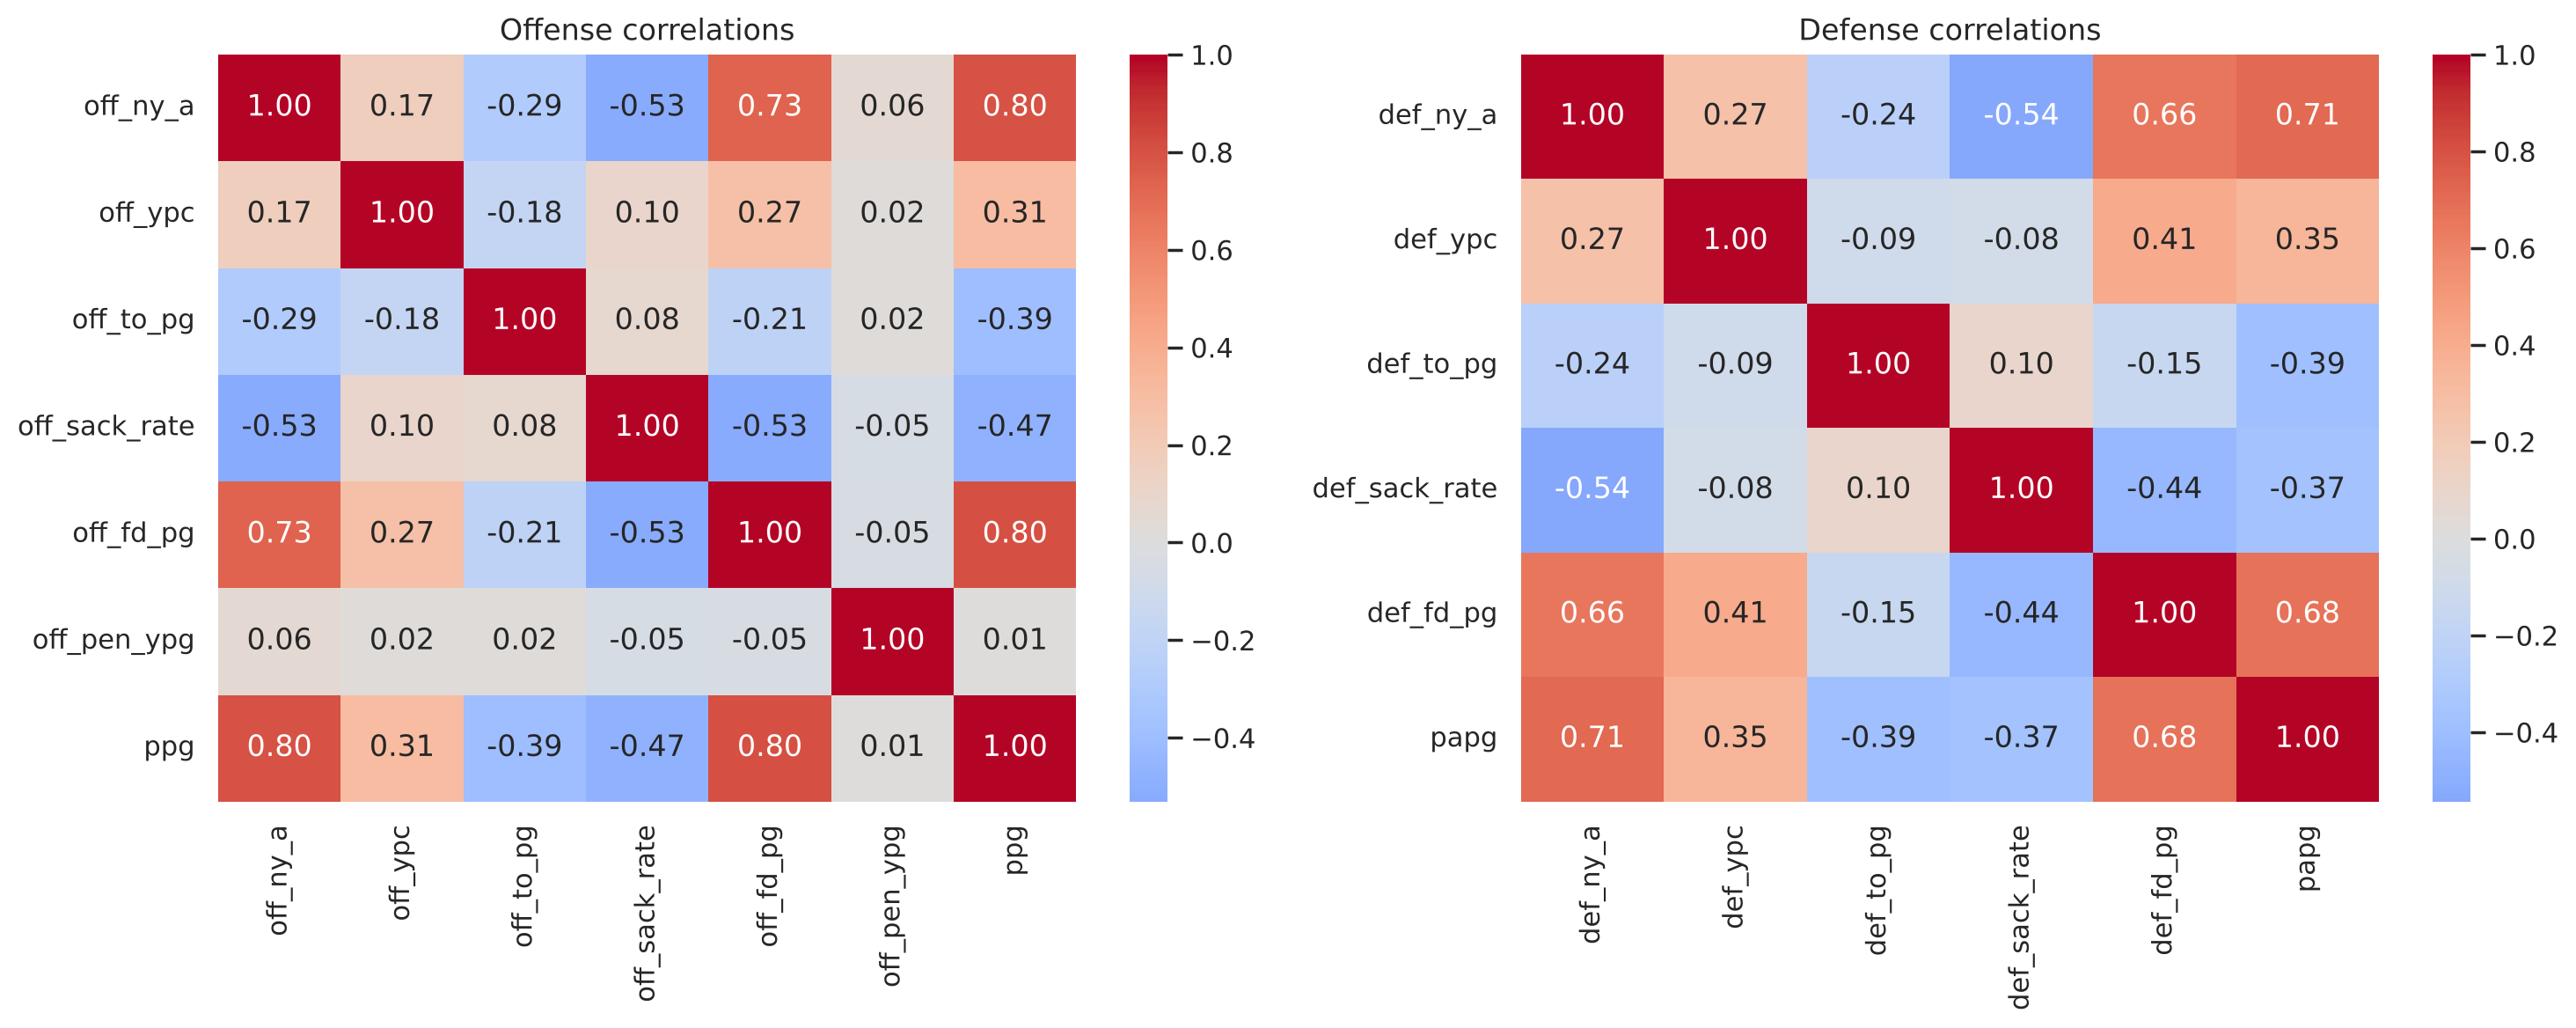

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(full[OFF + ["ppg"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Offense correlations")
sns.heatmap(full[DEF + ["papg"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Defense correlations")
plt.tight_layout(); plt.show()

## Part 3 · Simple linear regression: one stat, one line

Let's start with the single best stat. **Simple linear regression** draws the straight line that best fits the dots:

$$\text{points per game} = b_0 + b_1 \times \text{net yards per pass attempt}$$

* $b_0$ is the **intercept**: where the line crosses zero (often not meaningful on its own)
* $b_1$ is the **slope**: how many more points per game come with **one more** net yard per attempt

"Best fit" means the line that makes the **squared vertical distances** from the dots to the line (the **residuals**) as small as possible. This is called **ordinary least squares (OLS)**.

Fitted line:  points per game = -6.39 + 4.66 × (net yards per pass attempt)
R² = 0.64  →  passing efficiency alone explains 64% of the differences in scoring


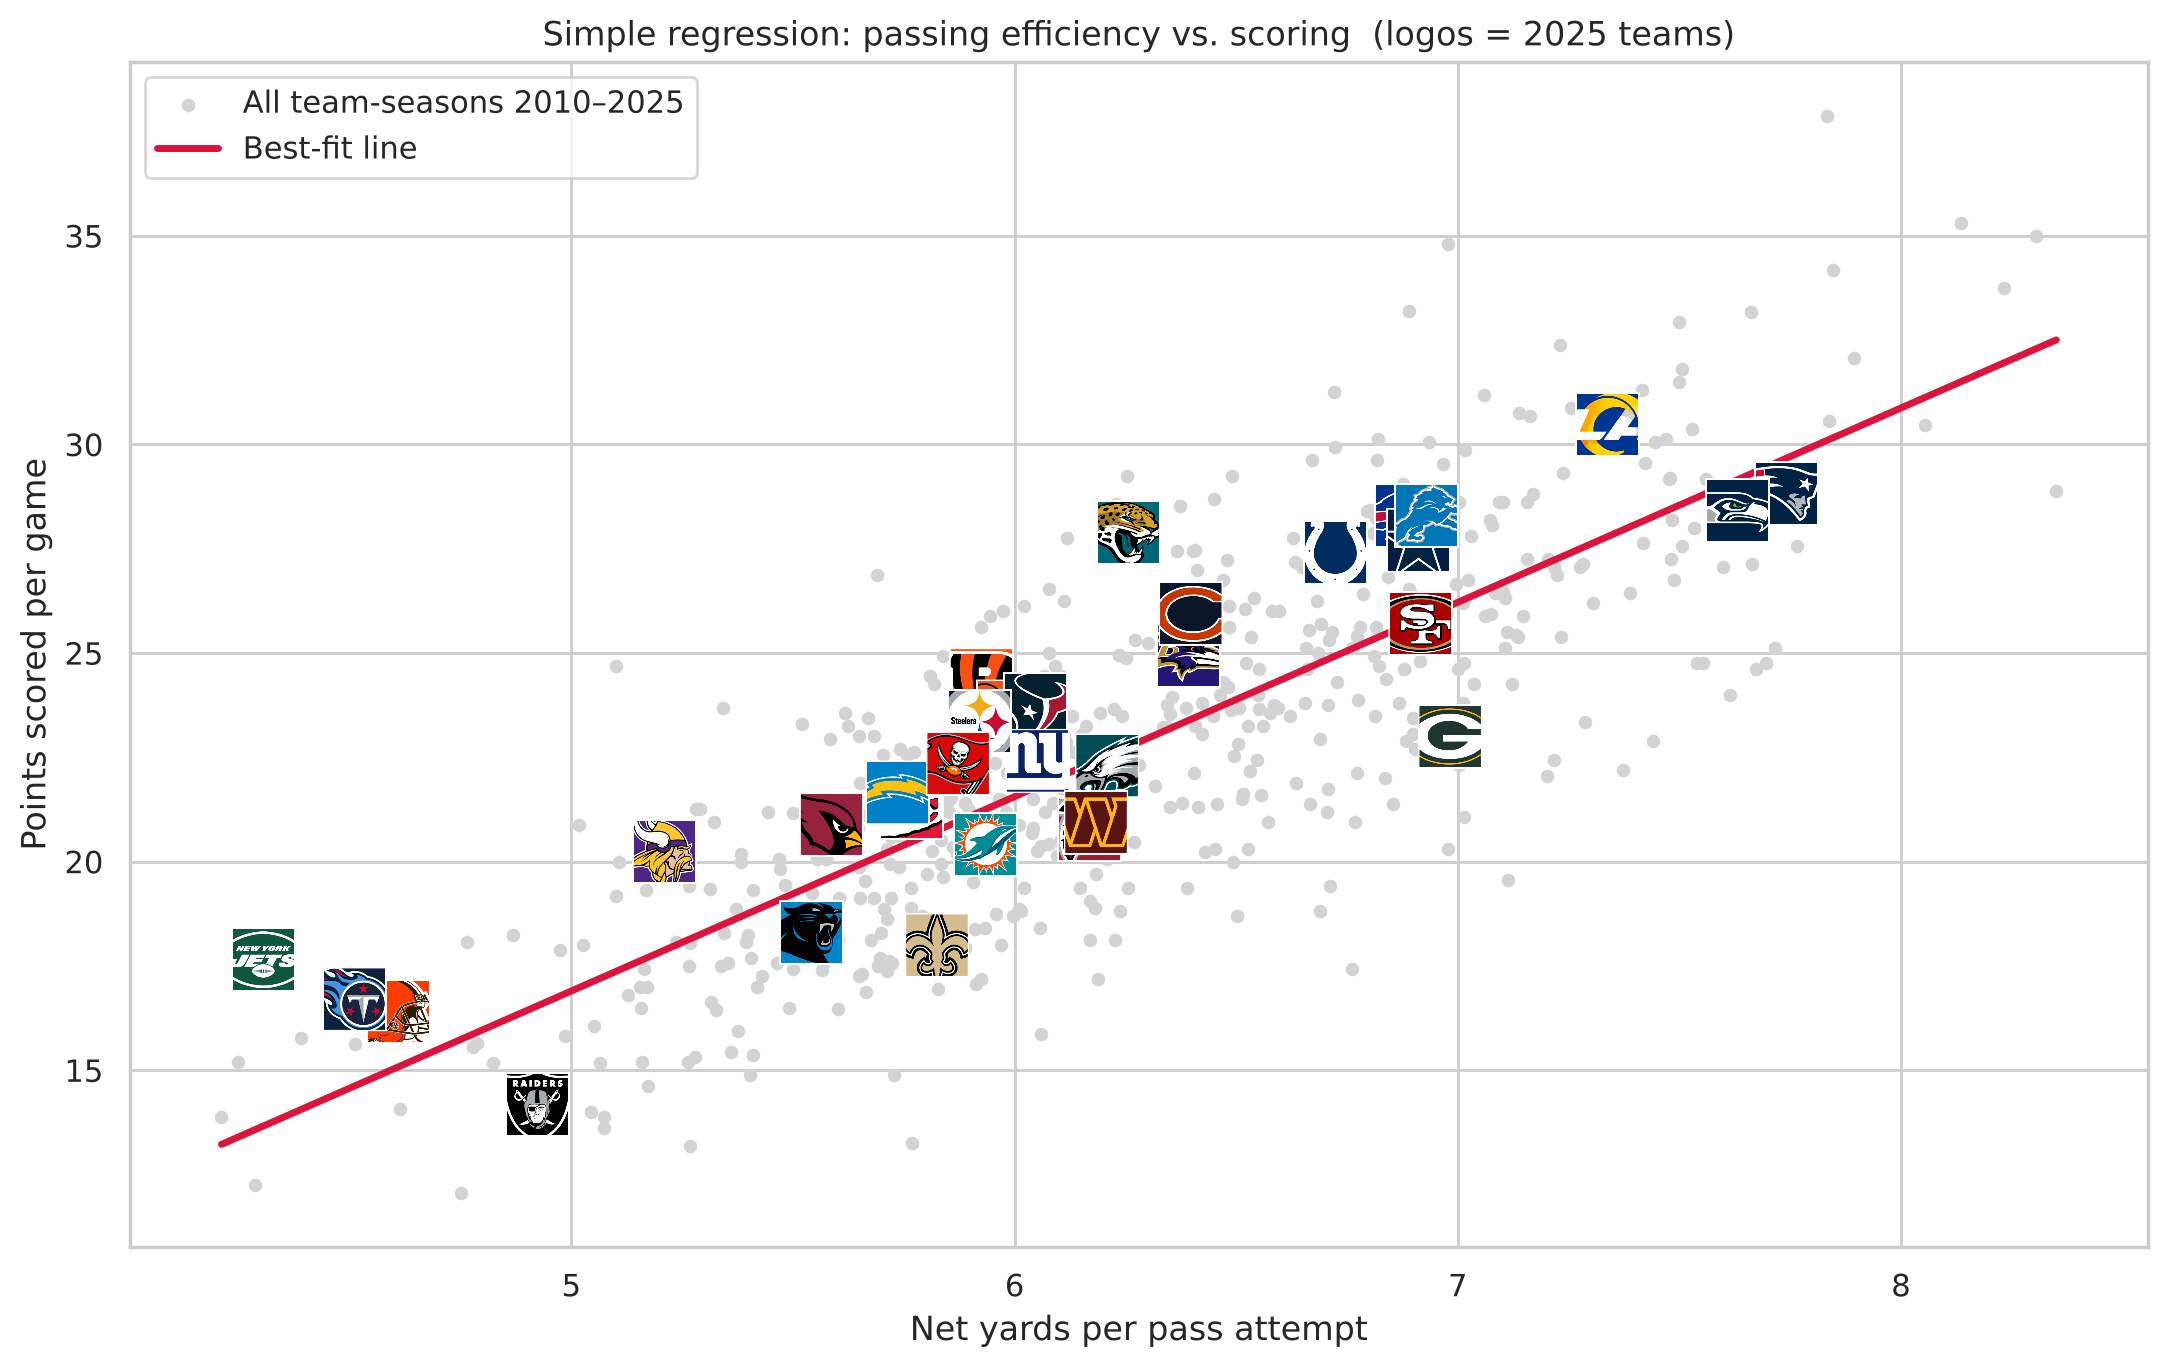

In [11]:
simple = smf.ols("ppg ~ off_ny_a", data=full).fit()
b0, b1 = simple.params["Intercept"], simple.params["off_ny_a"]
print(f"Fitted line:  points per game = {b0:.2f} + {b1:.2f} × (net yards per pass attempt)")
print(f"R² = {simple.rsquared:.2f}  →  passing efficiency alone explains {simple.rsquared:.0%} of the differences in scoring")

LAST_FULL = CURRENT_SEASON - 1
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(full.off_ny_a, full.ppg, color="lightgray", s=15, label="All team-seasons 2010–2025")
xs = np.linspace(full.off_ny_a.min(), full.off_ny_a.max(), 50)
ax.plot(xs, b0 + b1 * xs, color="crimson", lw=2.5, label="Best-fit line")
for _, r in full[full.season == LAST_FULL].iterrows():
    add_logo(ax, r.team, r.off_ny_a, r.ppg, zoom=0.22)
ax.set(xlabel="Net yards per pass attempt", ylabel="Points scored per game",
       title=f"Simple regression: passing efficiency vs. scoring  (logos = {LAST_FULL} teams)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### ✏️ Try it: predict a team's scoring by hand
Pick a team, plug its stat into the line, and compare with what really happened. The difference between actual and predicted is the **residual**.

In [12]:
MY_TEAM = "DET"     # ✏️ change to any team code, e.g. "KC", "SF", "BUF"
SEASON  = LAST_FULL # ✏️ or any season from 2010 to 2025

row = full[(full.season == SEASON) & (full.team == MY_TEAM)].iloc[0]
pred = b0 + b1 * row.off_ny_a
print(f"{SEASON} {MY_TEAM}: {row.off_ny_a:.2f} net yards per pass attempt")
print(f"Prediction = {b0:.2f} + {b1:.2f} × {row.off_ny_a:.2f} = {pred:.1f} points per game")
print(f"Actual     = {row.ppg:.1f} points per game")
print(f"Residual   = actual − predicted = {row.ppg - pred:+.1f}")

2025 DET: 6.93 net yards per pass attempt
Prediction = -6.39 + 4.66 × 6.93 = 25.9 points per game
Actual     = 28.3 points per game
Residual   = actual − predicted = +2.4


> 🔍 **Check your understanding:** In words, what does the slope b₁ mean?

<details><summary><b>Click to reveal the answer</b></summary>

Teams that gain one more net yard per pass attempt score about b₁ (roughly 5) more points per game, on average. It describes an association across teams, not a guarantee for any single team.

</details>

## Part 4 · Multiple linear regression: many stats at once

Passing isn't everything. **Multiple regression** uses several stats together:

$$\text{ppg} = b_0 + b_1(\text{pass eff.}) + b_2(\text{rush eff.}) + b_3(\text{giveaways}) + b_4(\text{sack rate}) + b_5(\text{penalty yds})$$

💡 **Key idea:** each coefficient now means *the effect of that stat **holding the others constant***. That is different from the simple slope, which mixed in everything that comes along with good passing.

### Train and test
We **train** (fit) the models on 2010–2023 and keep 2024–2025 hidden as a **test set**. Later we check how well the model predicts seasons it has never seen. That is the honest way to judge a model.

We fit two offense models: **Model A** (efficiency stats) and **Model B** (adds first downs). The table below is `statsmodels`' full summary. Focus on the `coef` and `P>|z|` columns.

In [13]:
train = full[~full.season.isin(TEST_SEASONS)].reset_index(drop=True)
test  = full[ full.season.isin(TEST_SEASONS)].reset_index(drop=True)

# The same franchise shows up every season, so its rows aren't independent.
# Clustering standard errors by team gives more honest p-values / CIs (coefficients are unchanged).
def fit(formula, data=train):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["team"]})

off_A = fit("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg")
off_B = fit("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg + off_fd_pg")

print(off_A.summary())

                            OLS Regression Results                            
Dep. Variable:                    ppg   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.694
Method:                 Least Squares   F-statistic:                     219.0
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           3.26e-23
Time:                        14:33:24   Log-Likelihood:                -1027.1
No. Observations:                 448   AIC:                             2066.
Df Residuals:                     442   BIC:                             2091.
Df Model:                           5                                         
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -3.1752      1.921     -1.653

### Reading the coefficients
Here are Model A's coefficients in friendlier units, with 95% **confidence intervals** (the plausible range for each effect) and **p-values** (below 0.05 usually means we can't blame the effect on chance).

* `off_ny_a`: **+1 net yard per pass attempt** ≈ **+3.8 points per game**
* `off_to_pg`: **+1 giveaway per game** ≈ **−1.8 points per game**
* `off_sack_rate`: shown per **+1 percentage point** of sack rate

In [14]:
def coef_table(model, scale=None):
    """Coefficient table with 95% CIs. `scale` lets us express effects per a sensible unit."""
    t = pd.DataFrame({"coef": model.params, "ci_low": model.conf_int()[0],
                      "ci_high": model.conf_int()[1], "p_value": model.pvalues}).drop("Intercept")
    if scale:
        for var, (factor, unit) in scale.items():
            if var in t.index:
                t.loc[var, ["coef", "ci_low", "ci_high"]] *= factor
                t.loc[var, "unit"] = unit
    t["variable"] = t.index.map(labels)
    return t[["variable", "unit", "coef", "ci_low", "ci_high", "p_value"]]

OFF_UNITS = {"off_ny_a": (1, "+1 yd/att"), "off_ypc": (1, "+1 yd/carry"),
             "off_to_pg": (1, "+1 giveaway/gm"), "off_sack_rate": (0.01, "+1 pct-pt"),
             "off_pen_ypg": (10, "+10 pen yds/gm"), "off_fd_pg": (1, "+1 first down/gm")}

print("Model A — points per game change per unit:")
display(coef_table(off_A, OFF_UNITS))

print(f"\nModel A R²: {off_A.rsquared:.3f}    Model B R²: {off_B.rsquared:.3f}")
print(f"Passing coefficient — A: {off_A.params['off_ny_a']:.2f}   B: {off_B.params['off_ny_a']:.2f}")

Model A — points per game change per unit:


,variable,unit,coef,ci_low,ci_high,p_value
off_ny_a,Net yards / pass att,+1 yd/att,3.818,3.358,4.278,0.000
off_ypc,Yards / carry,+1 yd/carry,1.848,1.373,2.324,0.000
off_to_pg,Giveaways / game,+1 giveaway/gm,-1.844,-2.572,-1.117,0.000
off_sack_rate,Sack rate (taken),+1 pct-pt,-0.352,-0.519,-0.185,0.000
off_pen_ypg,Penalty yards / game,+10 pen yds/gm,-0.210,-0.440,0.019,0.072



Model A R²: 0.698    Model B R²: 0.770
Passing coefficient — A: 3.82   B: 2.38


> 🔍 **Check your understanding:** The passing coefficient is about 5 in the simple regression (Part 3) but about 3.8 here. Why did it shrink?

<details><summary><b>Click to reveal the answer</b></summary>

Good passing teams also tend to run well and turn the ball over less. The simple slope gave passing credit for all of that. With those stats in the model, the passing coefficient only measures passing itself.

</details>

### ✏️ Try it: a multiple-regression prediction by hand
A prediction is just **each coefficient × the team's value, all added up**.

In [15]:
MY_TEAM, SEASON = "DET", LAST_FULL   # ✏️ change these

row = full[(full.season == SEASON) & (full.team == MY_TEAM)].iloc[0]
parts = pd.DataFrame({"coefficient": off_A.params})
parts["team value"] = [1.0 if v == "Intercept" else row[v] for v in parts.index]
parts["coef × value"] = parts["coefficient"] * parts["team value"]
parts.index = ["Intercept"] + [labels[v] for v in parts.index[1:]]
display(parts.round(3))
print(f"Sum = predicted points per game = {parts['coef × value'].sum():.1f}")
print(f"Actual points per game          = {row.ppg:.1f}")

,coefficient,team value,coef × value
Intercept,-3.175,1.000,-3.175
Net yards / pass att,3.818,6.929,26.454
Yards / carry,1.848,4.618,8.535
Giveaways / game,-1.844,0.882,-1.627
Sack rate (taken),-35.181,0.063,-2.209
Penalty yards / game,-0.021,42.235,-0.889


Sum = predicted points per game = 27.1
Actual points per game          = 28.3


> **Why does the passing coefficient drop again in Model B?** Good passing *creates* first downs, which create points. Once first downs are in the model, passing only gets credit for what it does *beyond* first downs. If you want the **total** value of passing, don't control for something passing causes.

### The defense model
Same idea, but the outcome is **points allowed**, so **negative coefficients are good** for a defense.

In [16]:
def_A = fit("papg ~ def_ny_a + def_ypc + def_to_pg + def_sack_rate")
print(def_A.summary())

DEF_UNITS = {"def_ny_a": (1, "+1 yd/att allowed"), "def_ypc": (1, "+1 yd/carry allowed"),
             "def_to_pg": (1, "+1 takeaway/gm"), "def_sack_rate": (0.01, "+1 pct-pt"),
             "def_fd_pg": (1, "+1 first down/gm allowed")}
display(coef_table(def_A, DEF_UNITS))

                            OLS Regression Results                            
Dep. Variable:                   papg   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     203.7
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           8.81e-22
Time:                        14:33:24   Log-Likelihood:                -999.63
No. Observations:                 448   AIC:                             2009.
Df Residuals:                     443   BIC:                             2030.
Df Model:                           4                                         
Covariance Type:              cluster                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -2.6169      2.371     -1.104

,variable,unit,coef,ci_low,ci_high,p_value
def_ny_a,Net yds / pass att ALLOWED,+1 yd/att allowed,3.619,3.158,4.079,0.000
def_ypc,Yards / carry ALLOWED,+1 yd/carry allowed,1.291,0.578,2.004,0.000
def_to_pg,Takeaways / game,+1 takeaway/gm,-2.134,-2.768,-1.501,0.000
def_sack_rate,Sack rate (made),+1 pct-pt,0.001,-0.162,0.164,0.994


### Offense vs. defense, on the same scale
Raw coefficients can't be compared directly (a yard per attempt isn't the same as a percentage point of sacks). So we **standardize**: what is a **one-standard-deviation** improvement in each stat worth in points per game? Positive bars always mean "helps the team".

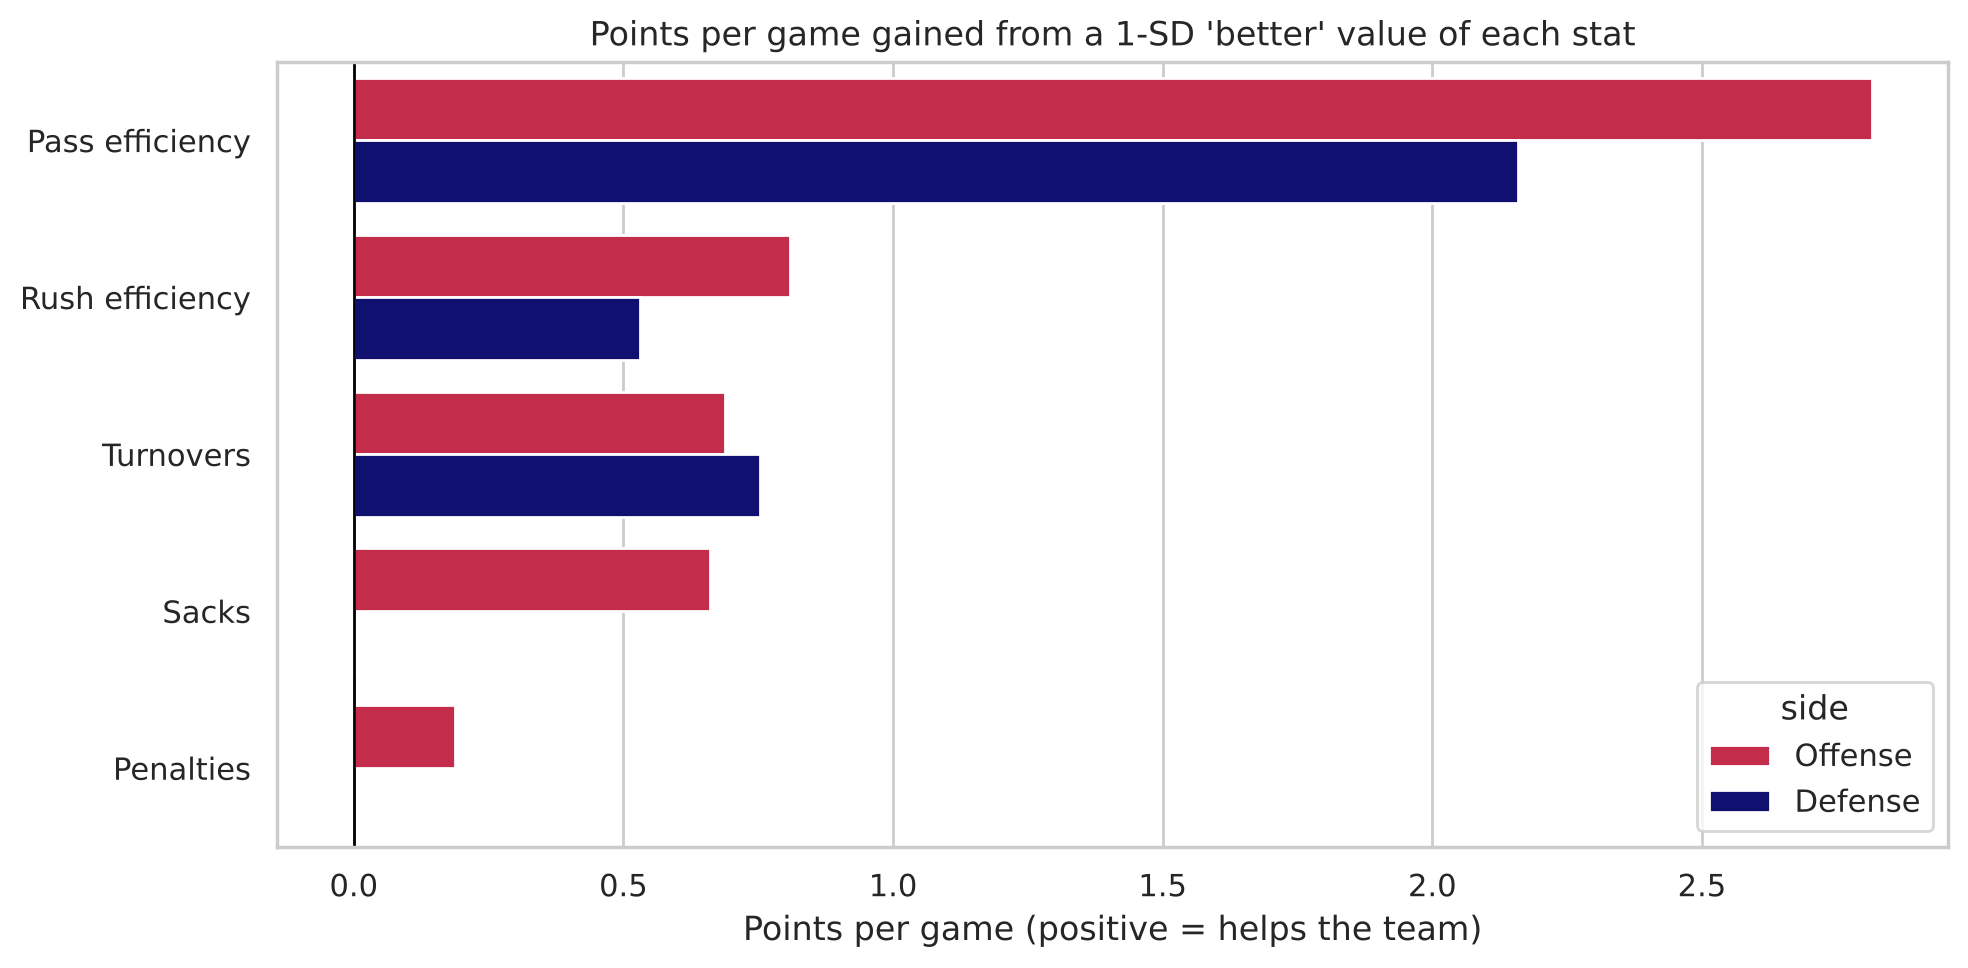

side,Defense,Offense
skill,,
Pass efficiency,2.159,2.815
Penalties,NaN,0.188
Rush efficiency,0.531,0.810
Sacks,-0.001,0.660
Turnovers,0.753,0.688


In [17]:
def standardized(formula, data):
    preds = [v.strip() for v in formula.split("~")[1].split("+")]
    z = data.copy()
    z[preds] = (z[preds] - z[preds].mean()) / z[preds].std()
    return smf.ols(formula, data=z).fit().params.drop("Intercept")

# +1 if a HIGHER value of the stat is better for the team, -1 if lower is better
better = {"off_ny_a": 1, "off_ypc": 1, "off_to_pg": -1, "off_sack_rate": -1, "off_pen_ypg": -1,
          "def_ny_a": -1, "def_ypc": -1, "def_to_pg": 1, "def_sack_rate": 1}

off_std = standardized("ppg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg", train)
def_std = -standardized("papg ~ def_ny_a + def_ypc + def_to_pg + def_sack_rate", train)  # fewer allowed = good
off_std = off_std * off_std.index.map(better)
def_std = def_std * def_std.index.map(better)

skill = {"off_ny_a": "Pass efficiency", "def_ny_a": "Pass efficiency",
         "off_ypc": "Rush efficiency", "def_ypc": "Rush efficiency",
         "off_to_pg": "Turnovers", "def_to_pg": "Turnovers",
         "off_sack_rate": "Sacks", "def_sack_rate": "Sacks", "off_pen_ypg": "Penalties"}

comp = pd.concat([
    pd.DataFrame({"skill": off_std.index.map(skill), "side": "Offense", "pts_per_sd": off_std.values}),
    pd.DataFrame({"skill": def_std.index.map(skill), "side": "Defense", "pts_per_sd": def_std.values}),
])

plt.figure(figsize=(10, 5))
sns.barplot(data=comp, y="skill", x="pts_per_sd", hue="side", palette={"Offense": "crimson", "Defense": "navy"})
plt.axvline(0, color="black", lw=1)
plt.title("Points per game gained from a 1-SD 'better' value of each stat")
plt.xlabel("Points per game (positive = helps the team)"); plt.ylabel("")
plt.tight_layout(); plt.show()

comp.pivot(index="skill", columns="side", values="pts_per_sd")

> 🔍 **Check your understanding:** Which skill matters most on both sides of the ball? Is rushing more or less important than you expected?

<details><summary><b>Click to reveal the answer</b></summary>

Passing efficiency is the biggest by far on both offense and defense, followed by turnovers. Rushing efficiency matters much less than many fans expect.

</details>

### Does the model work on seasons it has never seen?
We now score the models on the hidden 2024–2025 seasons. The **baseline** is guessing the league average for every team; a useful model must beat it.

* **R²**: share of the differences between teams the model explains (1 = perfect)
* **MAE** (mean absolute error): how far off the predictions are, on average, in points per game

In [18]:
def evaluate(model, data, y):
    pred = model.predict(data)
    return {"R² (test)": r2_score(data[y], pred),
            "MAE (test)": mean_absolute_error(data[y], pred),
            "Baseline MAE": mean_absolute_error(data[y], np.full(len(data), train[y].mean())),
            "R² (train)": model.rsquared}

pd.DataFrame({
    "Offense A (efficiency)": evaluate(off_A, test, "ppg"),
    "Offense B (+first downs)": evaluate(off_B, test, "ppg"),
    "Defense A": evaluate(def_A, test, "papg"),
}).T

,R² (test),MAE (test),Baseline MAE,R² (train)
Offense A (efficiency),0.766,1.633,3.455,0.698
Offense B (+first downs),0.835,1.446,3.455,0.770
Defense A,0.638,1.587,2.685,0.579


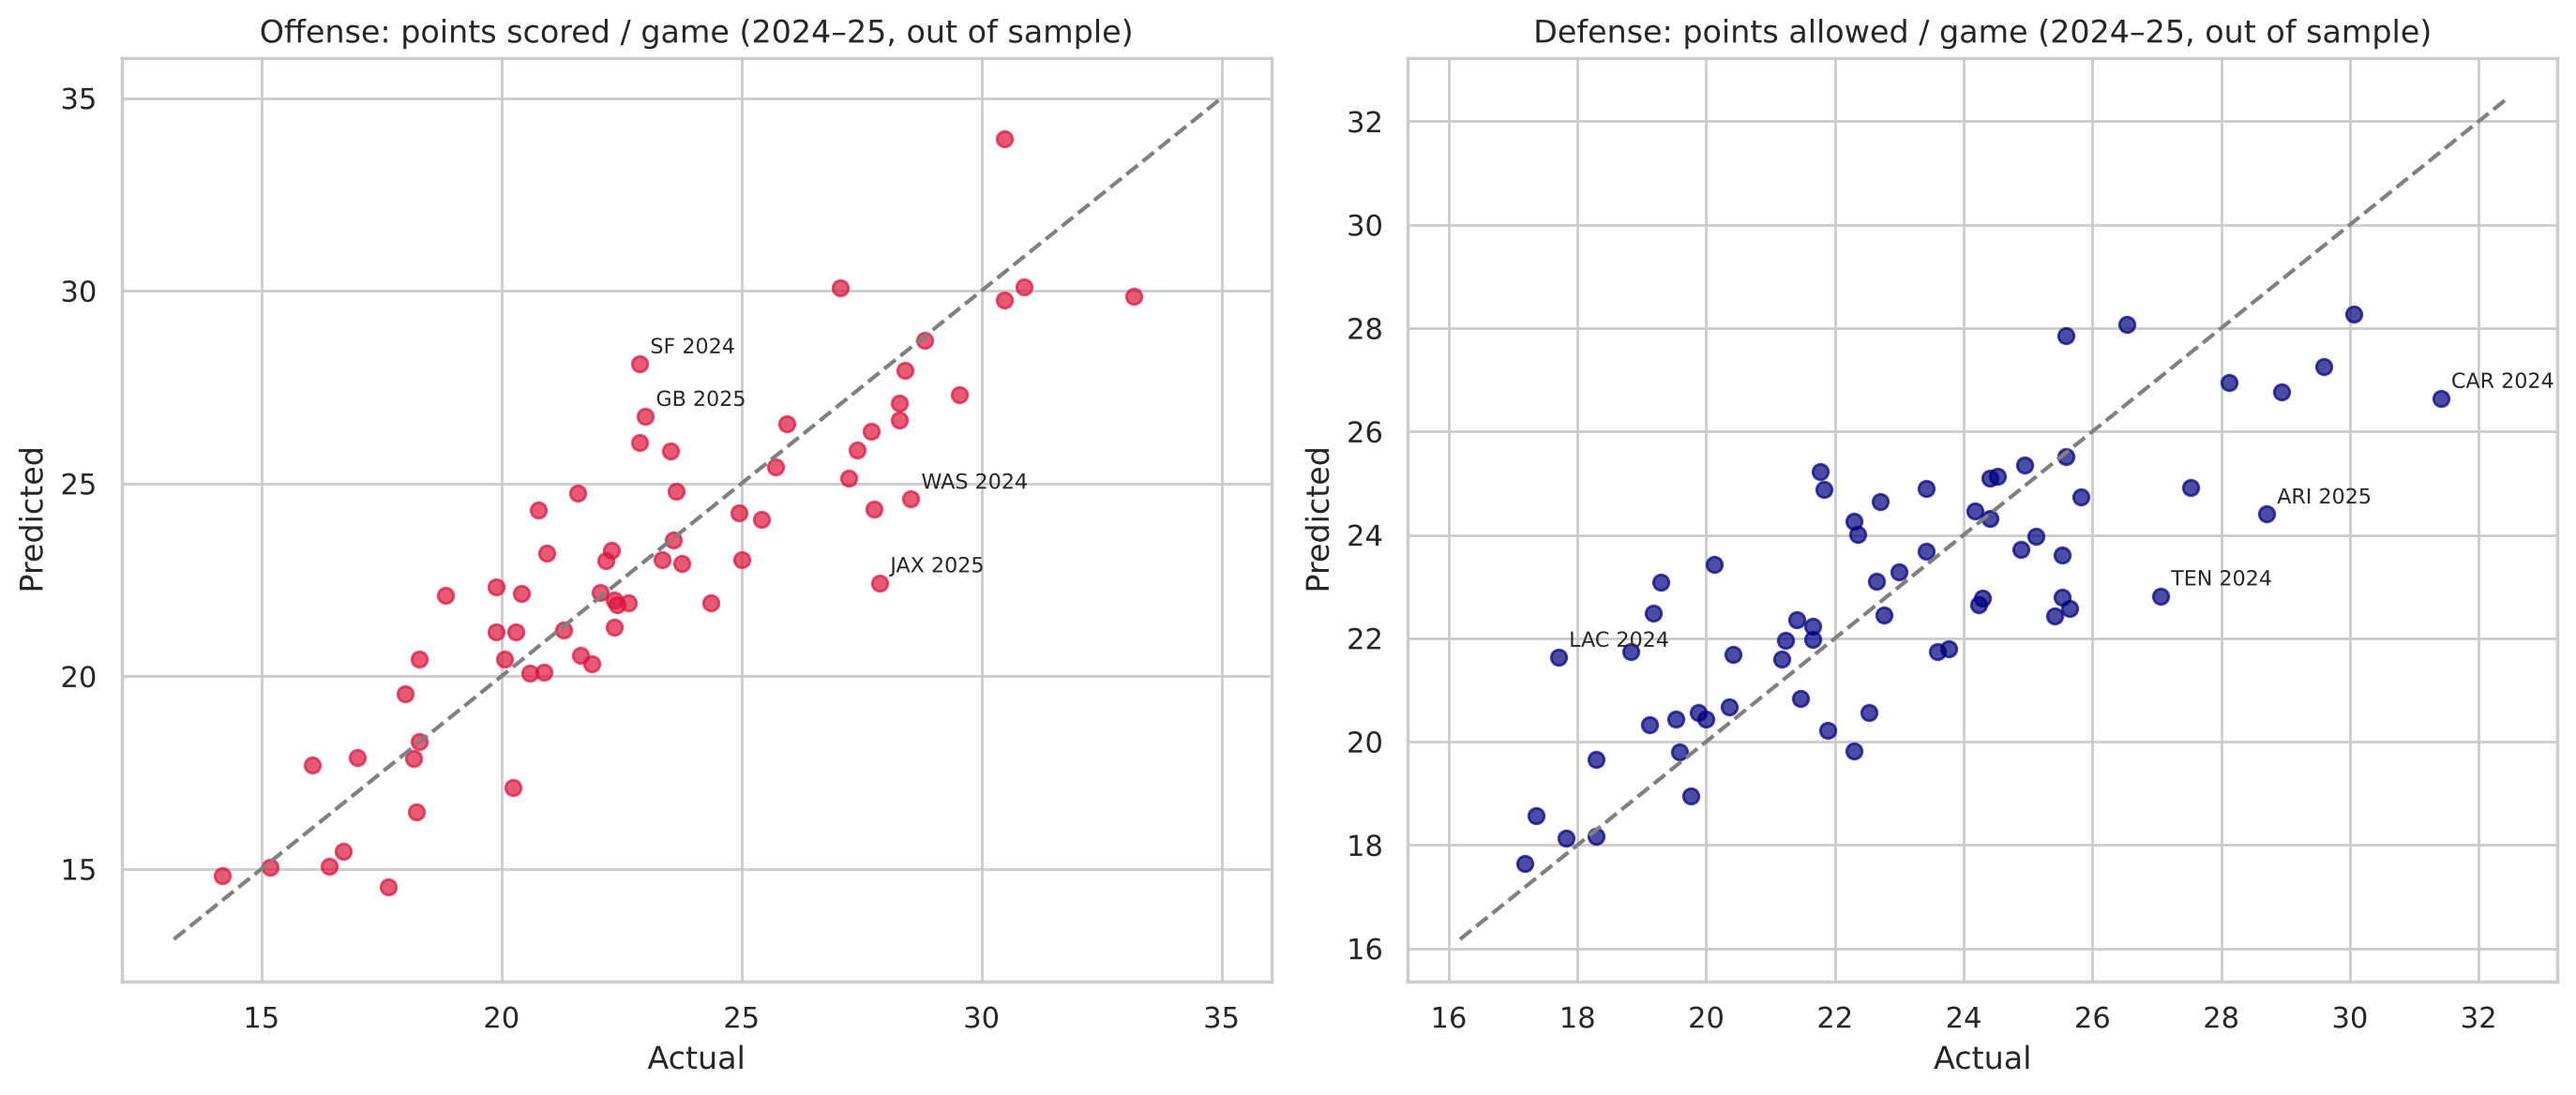

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, y, title, color in [
    (axes[0], off_A, "ppg",  "Offense: points scored / game", "crimson"),
    (axes[1], def_A, "papg", "Defense: points allowed / game", "navy")]:
    pred = model.predict(test)
    ax.scatter(test[y], pred, alpha=.7, color=color)
    lo, hi = min(test[y].min(), pred.min()) - 1, max(test[y].max(), pred.max()) + 1
    ax.plot([lo, hi], [lo, hi], "--", color="gray")
    for _, r in test.assign(pred=pred).assign(err=lambda d: (d[y] - d.pred).abs()).nlargest(4, "err").iterrows():
        ax.annotate(f"{r.team} {r.season}", (r[y], r.pred), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set(title=f"{title} (2024–25, out of sample)", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

> Teams far from the dashed line scored more (or less) than their stats suggest. Common reasons: red-zone efficiency, defensive or return touchdowns, field position, and luck in close games. None of those are in our model.

## Part 5 · From points to wins

### Offense + defense → point differential

In [20]:
combo = fit("diff_pg ~ off_ny_a + off_ypc + off_to_pg + off_sack_rate + off_pen_ypg"
            " + def_ny_a + def_ypc + def_to_pg + def_sack_rate")
display(coef_table(combo, {**OFF_UNITS, **DEF_UNITS}))
print(f"Train R²: {combo.rsquared:.3f}   Test R²: {r2_score(test.diff_pg, combo.predict(test)):.3f}")

,variable,unit,coef,ci_low,ci_high,p_value
off_ny_a,Net yards / pass att,+1 yd/att,3.933,3.457,4.410,0.000
off_ypc,Yards / carry,+1 yd/carry,1.635,0.994,2.275,0.000
off_to_pg,Giveaways / game,+1 giveaway/gm,-4.618,-5.385,-3.851,0.000
off_sack_rate,Sack rate (taken),+1 pct-pt,-0.303,-0.476,-0.130,0.001
off_pen_ypg,Penalty yards / game,+10 pen yds/gm,-0.586,-0.802,-0.371,0.000
def_ny_a,Net yds / pass att ALLOWED,+1 yd/att allowed,-3.459,-3.964,-2.954,0.000
def_ypc,Yards / carry ALLOWED,+1 yd/carry allowed,-1.768,-2.343,-1.192,0.000
def_to_pg,Takeaways / game,+1 takeaway/gm,4.650,3.889,5.411,0.000
def_sack_rate,Sack rate (made),+1 pct-pt,0.225,0.024,0.426,0.028


Train R²: 0.844   Test R²: 0.825


### Point differential → wins

Each +1 point/game of differential ≈ +0.028 win% ≈ +0.48 wins over a 17-game season.
So ~2.1 points/game of differential ≈ 1 extra win.  (R² = 0.824)


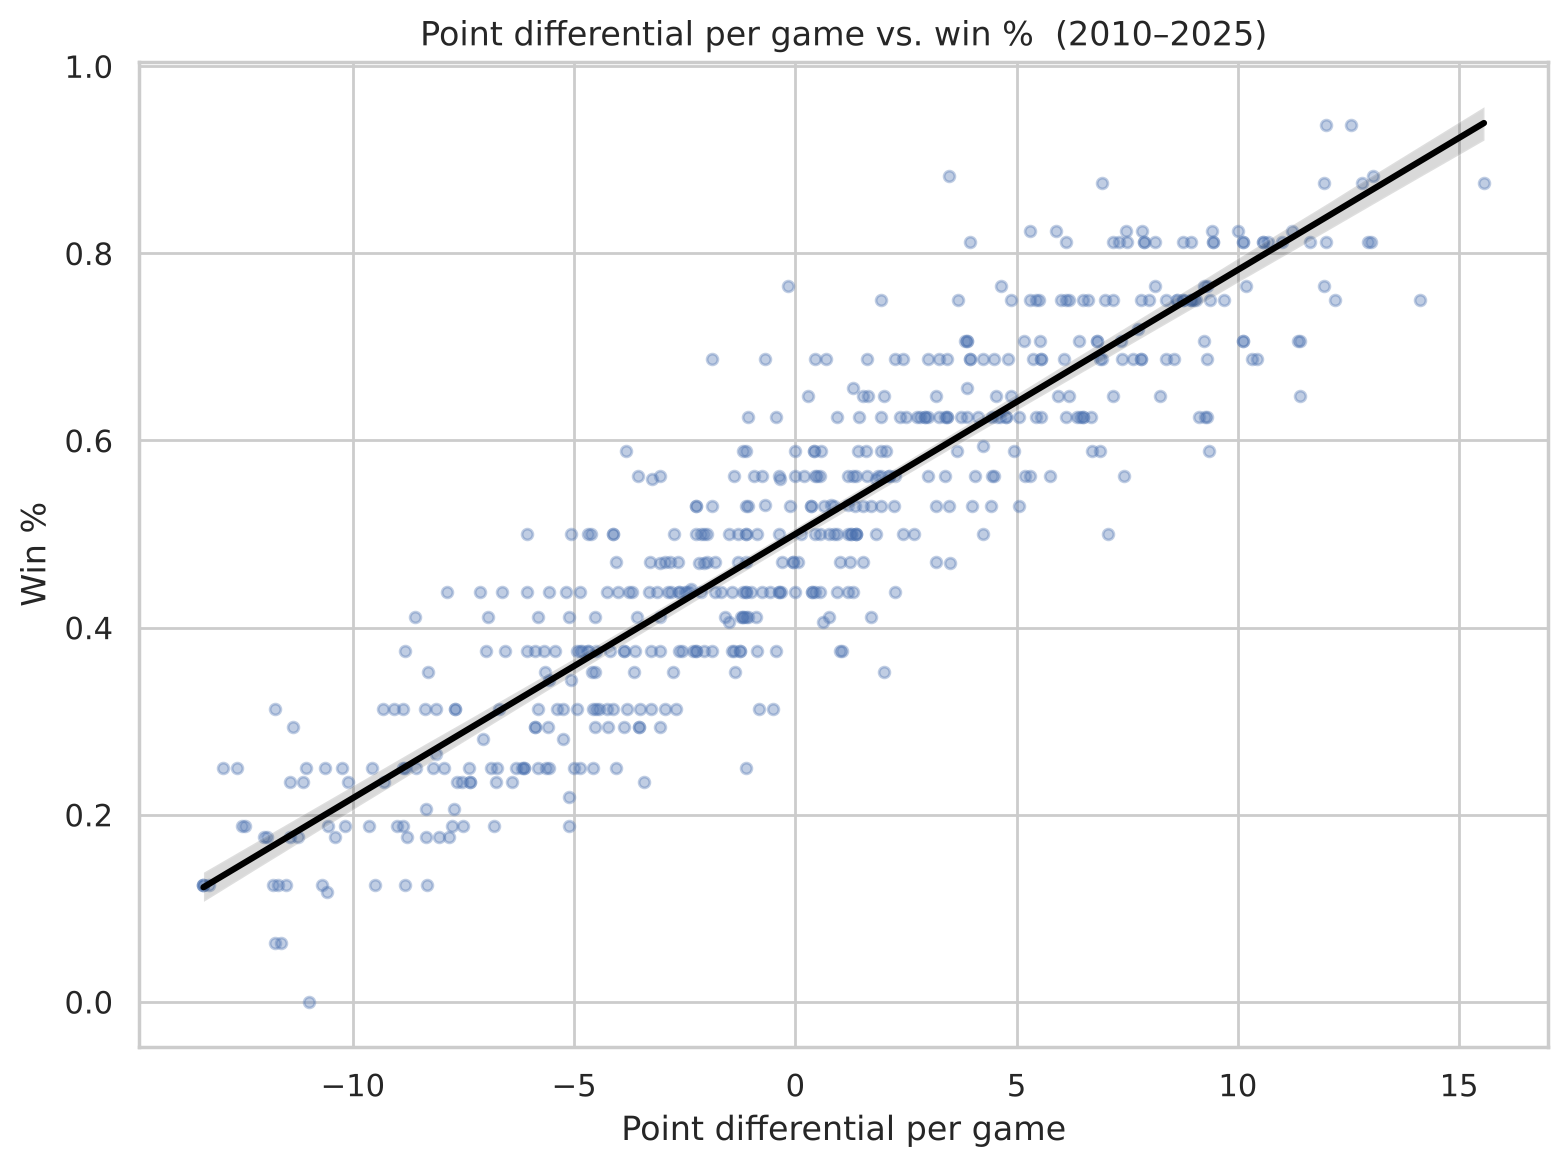

In [21]:
# How do points turn into wins?
wins = fit("win_pct ~ diff_pg")
b = wins.params["diff_pg"]
print(f"Each +1 point/game of differential ≈ +{b:.3f} win% "
      f"≈ +{b*17:.2f} wins over a 17-game season.")
print(f"So ~{1/(b*17):.1f} points/game of differential ≈ 1 extra win.  (R² = {wins.rsquared:.3f})")

plt.figure(figsize=(8, 6))
sns.regplot(data=full, x="diff_pg", y="win_pct", scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "black"})
plt.title("Point differential per game vs. win %  (2010–2025)")
plt.xlabel("Point differential per game"); plt.ylabel("Win %")
plt.tight_layout(); plt.show()

### What is a turnover worth in wins?

In [22]:
# Putting it together: what is one extra turnover per game worth in WINS?
# Turnover margin = takeaways − giveaways. A +1 margin can come from either side, so average the two effects.
per_margin = (combo.params["def_to_pg"] - combo.params["off_to_pg"]) / 2
print(f"+1 turnover margin per game ≈ {per_margin:.2f} points/game ≈ {per_margin*b*17:.1f} wins per season")
print(f"Even +0.25/game (about 4 extra over a season) ≈ {0.25*per_margin*b*17:.1f} wins")

+1 turnover margin per game ≈ 4.63 points/game ≈ 2.2 wins per season
Even +0.25/game (about 4 extra over a season) ≈ 0.6 wins


### What contributes most to winning?
Now we skip points entirely and regress **win %** directly on every offense and defense stat. Each bar is the number of **extra wins per season** from a one-standard-deviation better value.

Win % model   train R²: 0.725   test R² (2024–25): 0.716


Offense stats alone explain 49% of win % · defense stats alone explain 35%


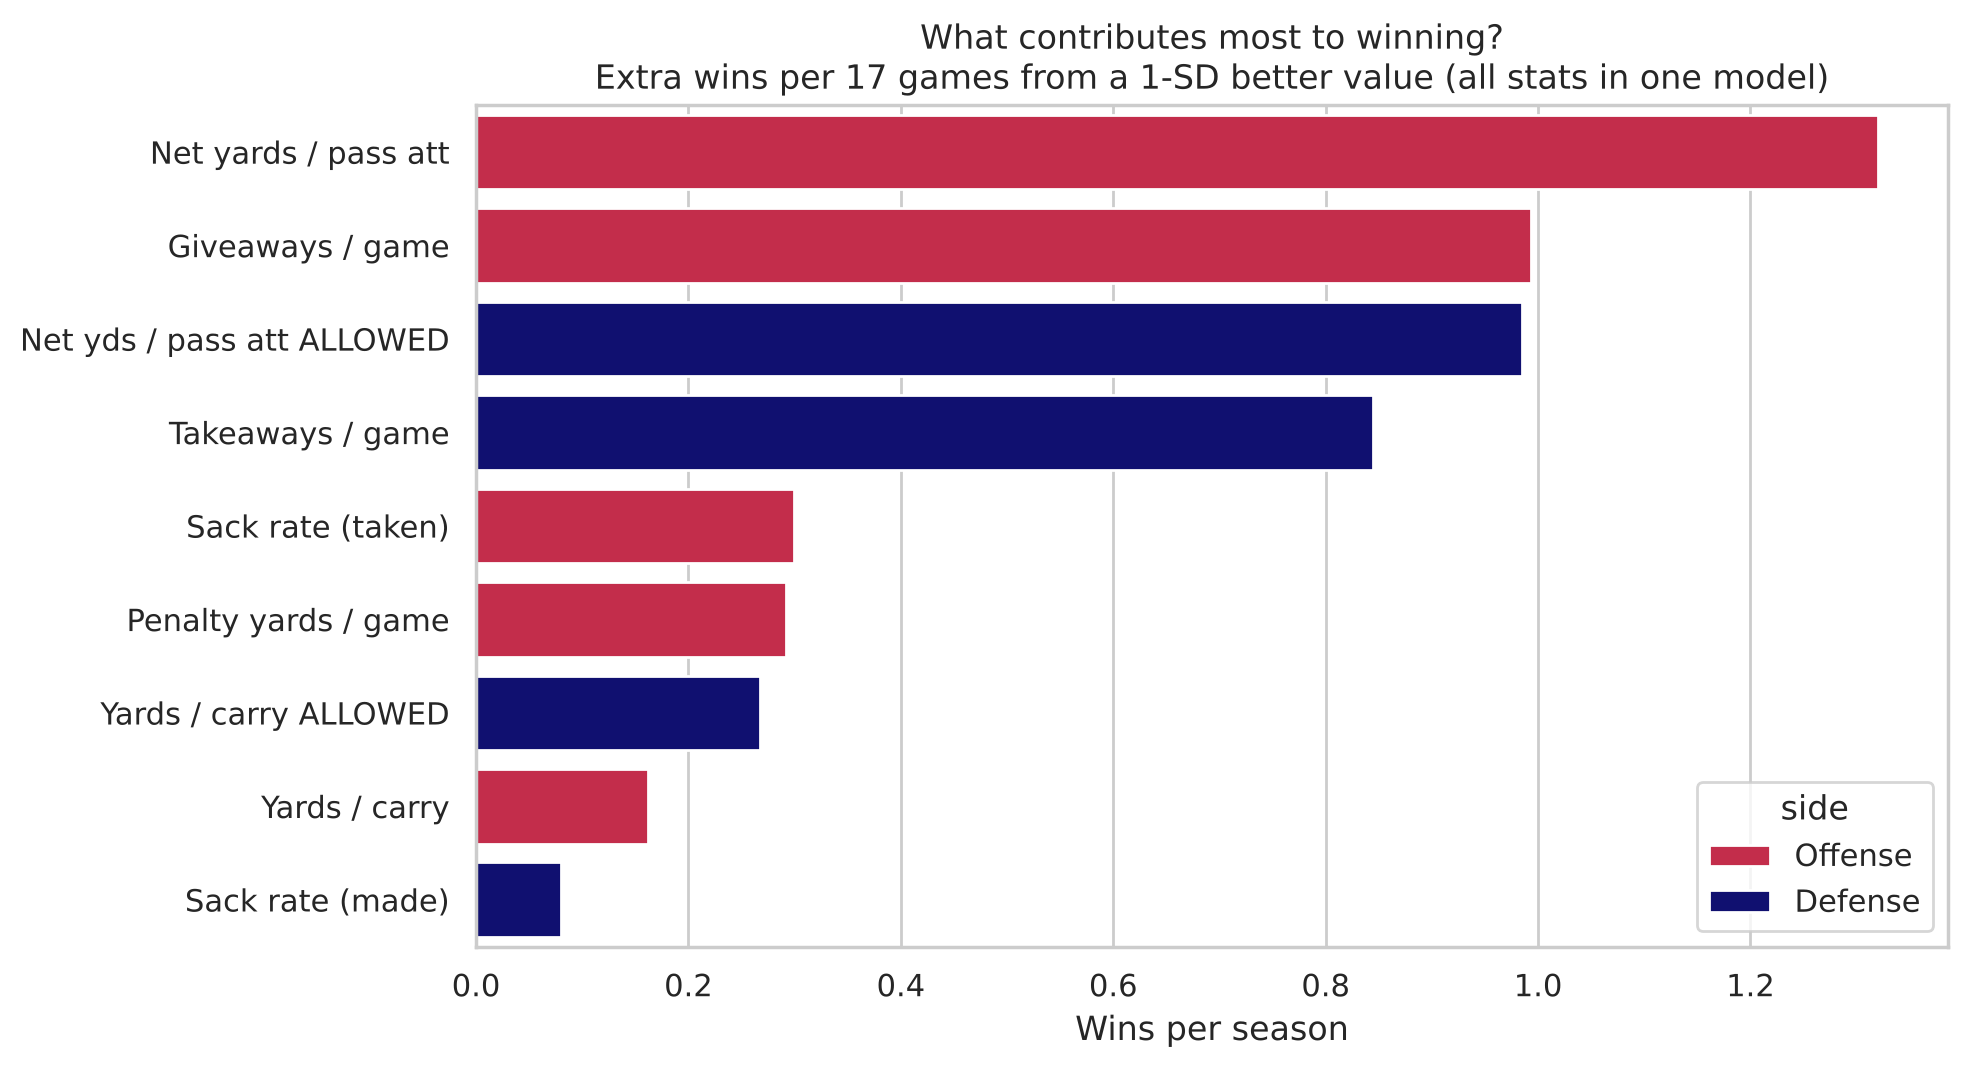

,stat,side,wins_per_sd,p_value
0,Net yards / pass att,Offense,1.320,0.000
1,Giveaways / game,Offense,0.993,0.000
2,Net yds / pass att ALLOWED,Defense,0.985,0.000
3,Takeaways / game,Defense,0.844,0.000
4,Sack rate (taken),Offense,0.299,0.000
5,Penalty yards / game,Offense,0.292,0.000
6,Yards / carry ALLOWED,Defense,0.267,0.008
7,Yards / carry,Offense,0.162,0.082
8,Sack rate (made),Defense,0.080,0.395


In [23]:
WIN_PREDS = ["off_ny_a", "off_ypc", "off_to_pg", "off_sack_rate", "off_pen_ypg",
             "def_ny_a", "def_ypc", "def_to_pg", "def_sack_rate"]

win_model = fit("win_pct ~ " + " + ".join(WIN_PREDS))
print(f"Win % model   train R²: {win_model.rsquared:.3f}   "
      f"test R² (2024–25): {r2_score(test.win_pct, win_model.predict(test)):.3f}")

# Offense alone vs. defense alone
off_only = fit("win_pct ~ " + " + ".join(p for p in WIN_PREDS if p.startswith("off")))
def_only = fit("win_pct ~ " + " + ".join(p for p in WIN_PREDS if p.startswith("def")))
print(f"Offense stats alone explain {off_only.rsquared:.0%} of win % · defense stats alone explain {def_only.rsquared:.0%}")

# coefficient × SD = effect of a 1-SD change; × better = sign so positive means "helps win"; × 17 = wins per season
sd = train[WIN_PREDS].std()
win_rank = pd.DataFrame({
    "stat":        [labels[v] for v in WIN_PREDS],
    "side":        ["Offense" if v.startswith("off") else "Defense" for v in WIN_PREDS],
    "wins_per_sd": [win_model.params[v] * sd[v] * better[v] * 17 for v in WIN_PREDS],
    "p_value":     [win_model.pvalues[v] for v in WIN_PREDS],
}).sort_values("wins_per_sd", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5.5))
sns.barplot(data=win_rank, y="stat", x="wins_per_sd", hue="side", dodge=False,
            palette={"Offense": "crimson", "Defense": "navy"})
plt.axvline(0, color="black", lw=1)
plt.title("What contributes most to winning?\nExtra wins per 17 games from a 1-SD better value (all stats in one model)")
plt.xlabel("Wins per season"); plt.ylabel("")
plt.tight_layout(); plt.show()

win_rank.round(3)

> 🔍 **Check your understanding:** Win % is a number between 0 and 1. What could go wrong if we used linear regression to predict the win % of an extremely good team?

<details><summary><b>Click to reveal the answer</b></summary>

A straight line has no ceiling, so it could predict more than 100% wins (or less than 0%). For season win % this rarely happens, but for a single game's yes/no outcome it's a real problem. Part 6 fixes it with logistic regression.

</details>

## Part 6 · Win probability: what are a team's chances *right now*?

TV broadcasts show numbers like *"Chiefs 73% to win"*. In this part you'll learn where that number comes from by **building it yourself**, in four steps:

1. **Count:** how often did teams in a similar spot actually win?
2. **Notice the problem:** most exact situations have never happened before.
3. **Fill the gaps with logistic regression**, a version of regression made for yes/no outcomes.
4. **Use it:** a play's *win-probability swing* is just the probability after the play minus the probability before it.

Each row of data is now **one play** (snap) from 2016 to 2025, and the outcome is **yes/no**: did the team with the ball go on to win? (`won` = 1 or 0)

### Load play-by-play data

In [24]:
pbp_cols = ["game_id", "season", "season_type", "week", "play_id", "home_team", "away_team", "posteam", "defteam",
            "qtr", "time", "down", "ydstogo", "yardline_100", "score_differential", "game_seconds_remaining",
            "posteam_timeouts_remaining", "defteam_timeouts_remaining", "result", "home_score", "away_score",
            "wp", "desc", "play_type", "interception", "fumble_lost", "sack", "pass_touchdown", "rush_touchdown",
            "fourth_down_converted", "fourth_down_failed", "field_goal_result", "complete_pass", "incomplete_pass",
            "air_yards", "third_down_converted", "third_down_failed", "rush_attempt", "qb_scramble",
            "qb_kneel", "qb_spike", "passer_player_name", "receiver_player_name"]

plays = nfl.load_pbp(seasons=list(range(2016, 2026))).select(pbp_cols).to_pandas()
plays = plays[plays.season_type == "REG"].copy()
ot_games = set(plays.loc[plays.qtr == 5, "game_id"])

# Keep regulation snaps that have a down, from games that didn't end in a tie
plays = plays[plays.posteam.notna() & plays.down.notna() & (plays.qtr <= 4) & (plays.result != 0)].copy()

# Outcome: did the team with the ball win?  (result = home score − away score at the end)
plays["won"] = np.where(plays.posteam == plays.home_team, plays.result > 0, plays.result < 0).astype(int)
plays["down"] = plays.down.astype(int)
plays["min_left"] = plays.game_seconds_remaining / 60

def add_features(df):
    """Extra inputs built from the raw columns. Each one is explained when we first use it."""
    df = df.copy()
    df["min_elapsed"]   = 60 - df.min_left
    df["lead_per_time"] = df.score_differential / np.sqrt(df.min_left + 1)
    if "yardline_100" in df:
        late = df.min_left <= 2
        df["late_red_zone"]  = ((df.yardline_100 <= 10) & late).astype(int)
        df["late_fg_chance"] = ((df.yardline_100 <= 35) & late & df.score_differential.between(-3, 0)).astype(int)
    return df

plays = add_features(plays)
wp_train = plays[plays.season <= 2024]   # fit models on 2016–2024
wp_test  = plays[plays.season == 2025]   # test them on 2025
print(f"Training plays (2016–2024): {len(wp_train):,}   Test plays (2025): {len(wp_test):,}")
plays[["season", "posteam", "defteam", "qtr", "time", "down", "ydstogo", "yardline_100", "score_differential", "won"]].head()

Training plays (2016–2024): 346,689   Test plays (2025): 38,480


,season,posteam,defteam,qtr,time,down,ydstogo,yardline_100,score_differential,won
2,2016,BAL,BUF,1.000,14:57,1,10.000,86.000,0.000,1
3,2016,BAL,BUF,1.000,14:32,2,4.000,80.000,0.000,1
4,2016,BAL,BUF,1.000,14:01,1,10.000,75.000,0.000,1
5,2016,BAL,BUF,1.000,13:35,2,10.000,75.000,0.000,1
6,2016,BAL,BUF,1.000,12:54,3,1.000,66.000,0.000,1


### Step 1: Count it
The simplest possible "win probability": group plays by **lead** and **time left**, and compute the share of those teams that went on to win.

In [25]:
lead_group = pd.cut(plays.score_differential, [-99, -8, -4, -1, 0, 3, 7, 99],
                    labels=["down 8+", "down 4–7", "down 1–3", "tied", "up 1–3", "up 4–7", "up 8+"])
time_group = pd.cut(plays.min_left, [-1, 5, 15, 30, 45, 60],
                    labels=["last 5 min", "rest of Q4", "Q3", "Q2", "Q1"])

count_table = (plays.groupby([lead_group, time_group], observed=True).won.mean().unstack()
                    [["Q1", "Q2", "Q3", "rest of Q4", "last 5 min"]].iloc[::-1])
count_table.index.name, count_table.columns.name = "Team with the ball is…", "Time left"
display(count_table.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("How often teams actually won from each situation (2016–2025)"))

Time left,Q1,Q2,Q3,rest of Q4,last 5 min
Team with the ball is…,,,,,
up 8+,83%,89%,93%,97%,100%
up 4–7,73%,75%,79%,85%,94%
up 1–3,64%,65%,67%,71%,82%
tied,54%,55%,55%,59%,69%
down 1–3,47%,47%,46%,46%,43%
down 4–7,34%,36%,33%,27%,23%
down 8+,22%,17%,11%,6%,2%


> 🔍 **Check your understanding:** Read the table: a team up 4–7 points wins about 73% of the time in Q1. What about in the last 5 minutes? Why does the same lead matter more late?

<details><summary><b>Click to reveal the answer</b></summary>

About 94%. Late in the game the trailing team has fewer possessions left to catch up, so the same lead is much safer.

</details>

> 🔍 **Check your understanding:** The **tied** row is above 50% in the last 5 minutes. Why would the team with the ball be favored in a tie game?

<details><summary><b>Click to reveal the answer</b></summary>

With little time left, the team that has the ball is likely to get the last real chance to score (even a field goal wins), while the other team may never get the ball back.

</details>

### Step 2: The problem with counting
Counting works for broad groups, but real situations are very specific. How many times in 10 seasons was a team **up 3, with about a minute left, facing 2nd & 7 at the opponent's 40**?

In [26]:
exact = plays[(plays.score_differential == 3) & plays.min_left.between(1, 1.5) &
              (plays.down == 2) & (plays.ydstogo == 7) & (plays.yardline_100 == 40)]
print(f"Plays from 2016–2025 matching that situation exactly: {len(exact)}")

Plays from 2016–2025 matching that situation exactly: 0


💡 **Key idea:** most exact situations have **never happened**, so we can't just count. We need a **model** that learns how lead, time and field position each push the odds up or down, and then **fills in** situations it has never seen. That's what regression does.

### Step 3: Why not ordinary linear regression?
Let's try the regression we already know and predict `won` (0 or 1) from the lead with a straight line.

Linear model: P(win) = 0.542 + 0.0263 × lead
  lead of -35 points → predicted chance of winning = -37.7%
  lead of -21 points → predicted chance of winning =  -1.0%
  lead of  +0 points → predicted chance of winning =  54.2%
  lead of +21 points → predicted chance of winning = 109.3%
  lead of +35 points → predicted chance of winning = 146.1%


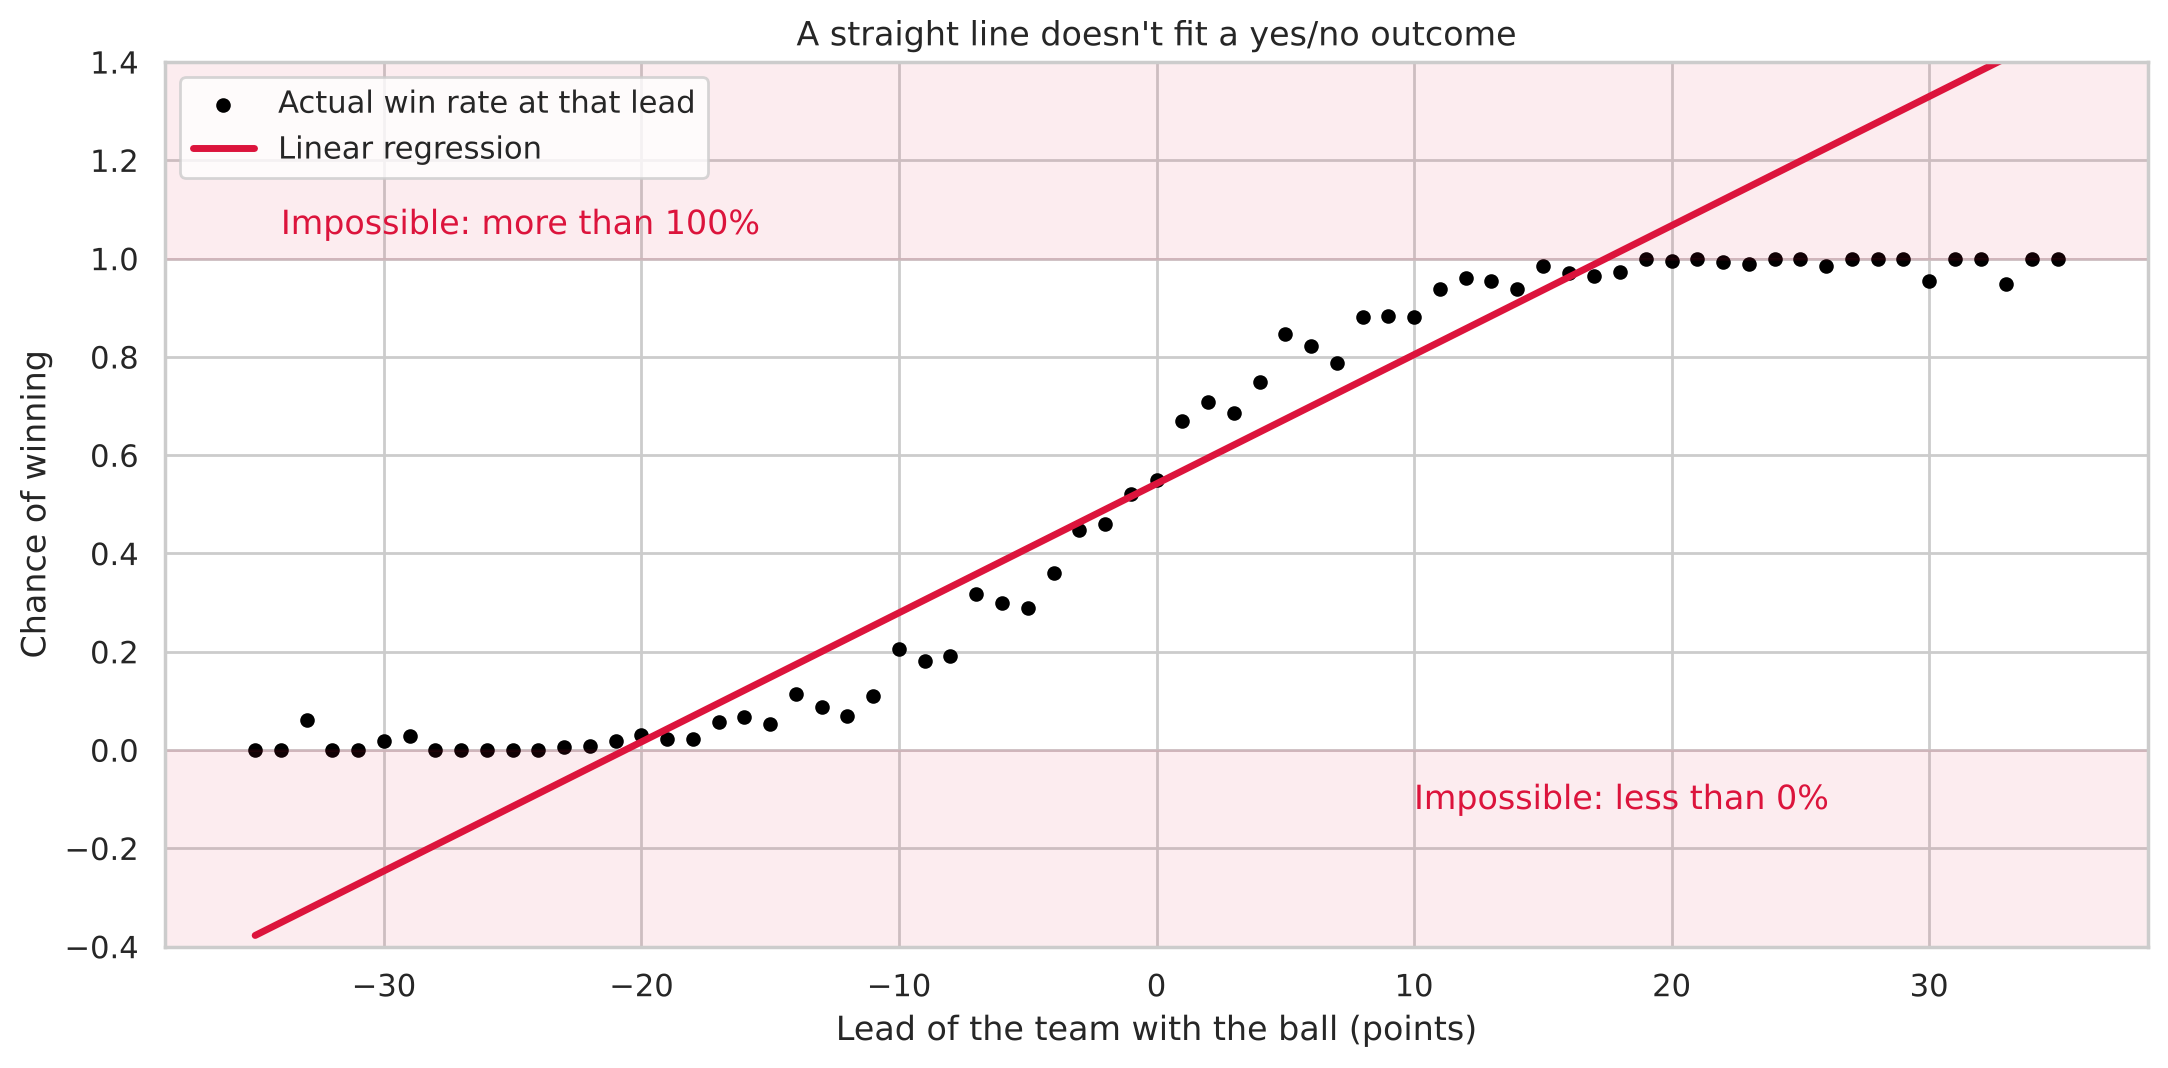

In [27]:
lpm = smf.ols("won ~ score_differential", data=wp_train).fit()
print(f"Linear model: P(win) = {lpm.params['Intercept']:.3f} + {lpm.params['score_differential']:.4f} × lead")
for lead in [-35, -21, 0, 21, 35]:
    print(f"  lead of {lead:+3d} points → predicted chance of winning = {lpm.params['Intercept'] + lpm.params['score_differential'] * lead:6.1%}")

by_lead = wp_train[wp_train.score_differential.between(-35, 35)].groupby("score_differential").won.mean()
xs = np.arange(-35, 36)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(by_lead.index, by_lead.values, color="black", s=18, label="Actual win rate at that lead")
ax.plot(xs, lpm.params["Intercept"] + lpm.params["score_differential"] * xs, color="crimson", lw=2.5, label="Linear regression")
ax.axhspan(1, 1.6, color="crimson", alpha=.08); ax.axhspan(-0.6, 0, color="crimson", alpha=.08)
ax.text(-34, 1.05, "Impossible: more than 100%", color="crimson"); ax.text(10, -0.12, "Impossible: less than 0%", color="crimson")
ax.set(xlabel="Lead of the team with the ball (points)", ylabel="Chance of winning", ylim=(-0.4, 1.4),
       title="A straight line doesn't fit a yes/no outcome")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

💡 **Key idea:** probabilities must stay between 0% and 100%, and real win chances **level off**: going from up 21 to up 28 barely matters, because you were already almost sure to win. A straight line can't bend, so it breaks.

### Step 4: Logistic regression bends the line
Logistic regression does two things:
1. It computes a straight-line **score** $z$ from the inputs, exactly like linear regression: $z = b_0 + b_1 x_1 + b_2 x_2 + \dots$
2. It squeezes that score into a probability with the **logistic function**:

$$P(\text{win}) = \frac{1}{1 + e^{-z}}$$

| score $z$ | −4 | −2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| $P(\text{win})$ | 2% | 12% | 50% | 88% | 98% |

Big positive scores become probabilities near 100%, big negative ones near 0%, and a score of 0 means 50/50. The computer picks the coefficients that make the real outcomes as likely as possible (this is called **maximum likelihood**, the logistic version of least squares).

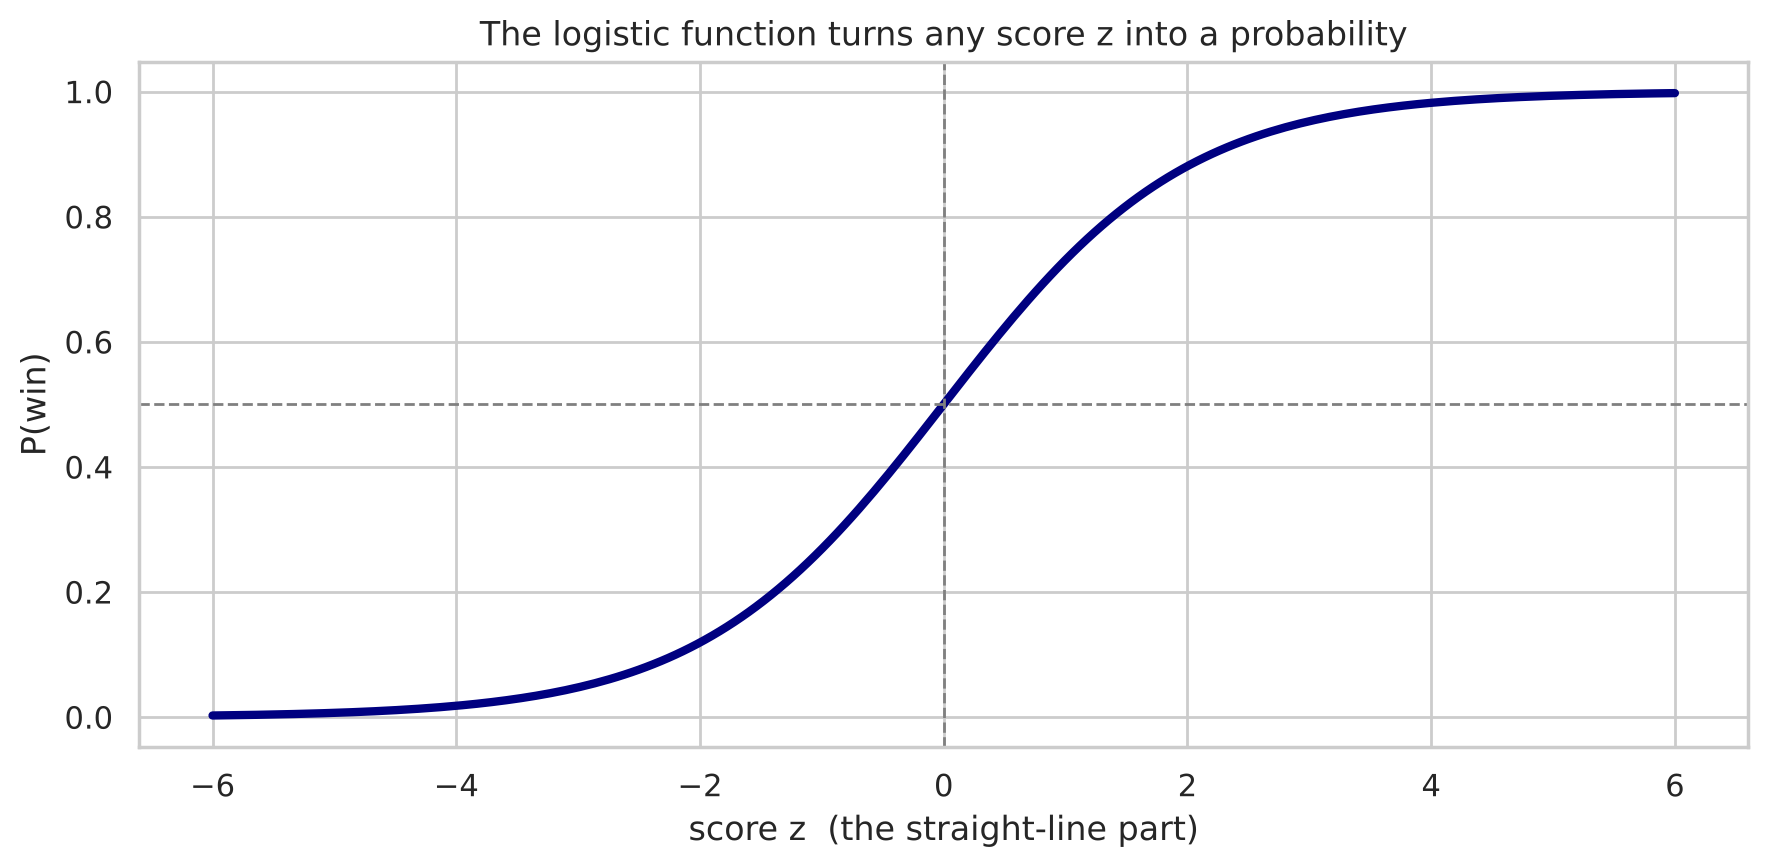

In [28]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(9, 4.5))
plt.plot(z, 1 / (1 + np.exp(-z)), color="navy", lw=3)
plt.axhline(0.5, color="gray", ls="--", lw=1); plt.axvline(0, color="gray", ls="--", lw=1)
plt.title("The logistic function turns any score z into a probability")
plt.xlabel("score z  (the straight-line part)"); plt.ylabel("P(win)")
plt.tight_layout(); plt.show()

### Logistic regression with just the lead

score z = 0.277 + 0.183 × lead        P(win) = 1 / (1 + e^(−z))



lead,model P(win),actual win rate
-14,9%,11%
-7,27%,32%
-3,43%,45%
0,57%,55%
3,70%,69%
7,83%,79%
14,94%,94%


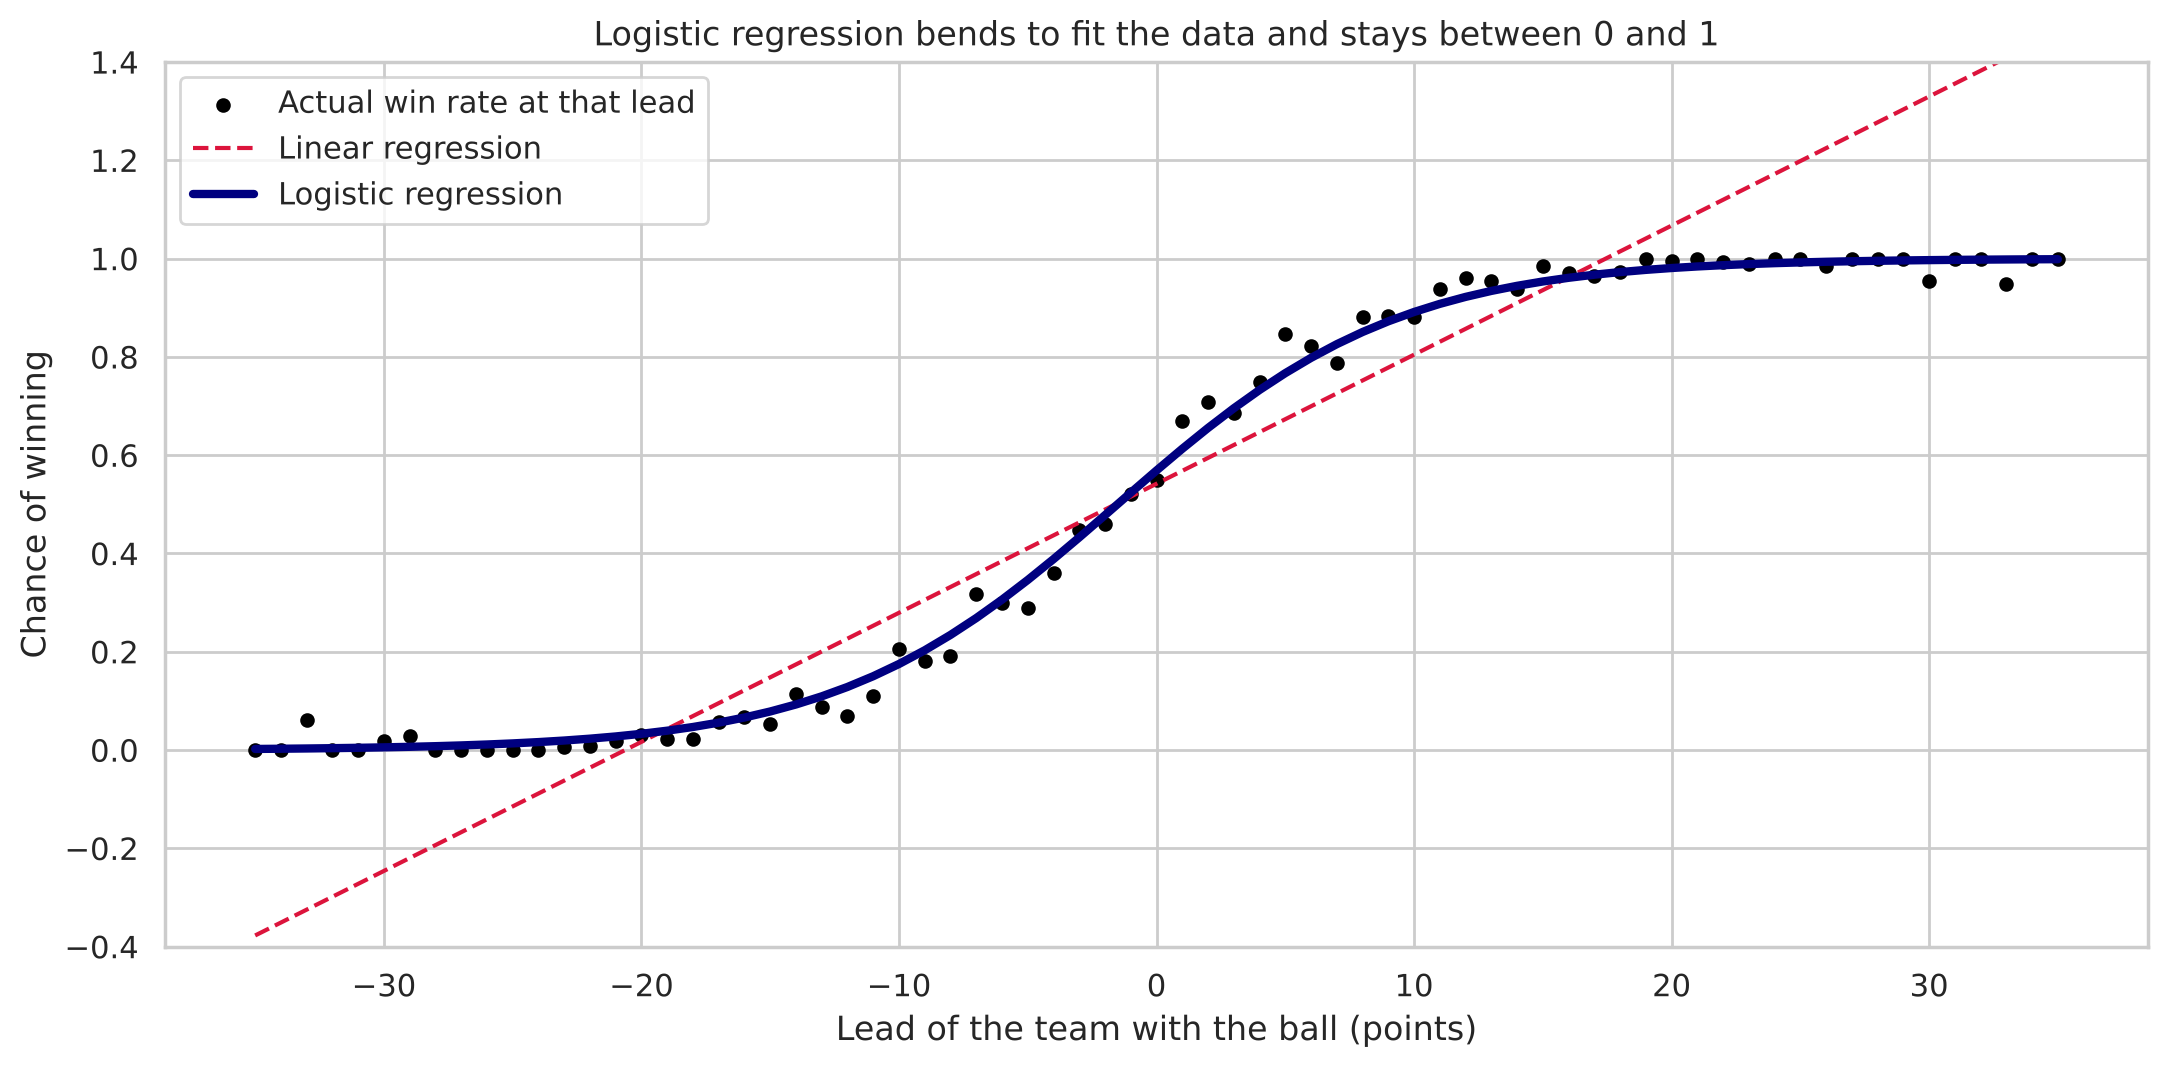

In [29]:
logit_lead = smf.logit("won ~ score_differential", data=wp_train).fit(disp=0)
b0, b1 = logit_lead.params["Intercept"], logit_lead.params["score_differential"]
print(f"score z = {b0:.3f} + {b1:.3f} × lead        P(win) = 1 / (1 + e^(−z))\n")

leads = [-14, -7, -3, 0, 3, 7, 14]
compare = pd.DataFrame({"lead": leads,
                        "model P(win)": logit_lead.predict(pd.DataFrame({"score_differential": leads})).values,
                        "actual win rate": by_lead.reindex(leads).values})
display(compare.style.format({"model P(win)": "{:.0%}", "actual win rate": "{:.0%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(by_lead.index, by_lead.values, color="black", s=18, label="Actual win rate at that lead")
ax.plot(xs, lpm.params["Intercept"] + lpm.params["score_differential"] * xs, color="crimson", lw=1.5, ls="--", label="Linear regression")
ax.plot(xs, logit_lead.predict(pd.DataFrame({"score_differential": xs})), color="navy", lw=3, label="Logistic regression")
ax.set(xlabel="Lead of the team with the ball (points)", ylabel="Chance of winning", ylim=(-0.4, 1.4),
       title="Logistic regression bends to fit the data and stays between 0 and 1")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Use the printed equation to compute the chance of winning when up 7 by hand. (z = b₀ + b₁ × 7, then P = 1/(1+e^(−z)).)

<details><summary><b>Click to reveal the answer</b></summary>

z ≈ 0.28 + 0.18 × 7 ≈ 1.56, and P ≈ 1 / (1 + e^(−1.56)) ≈ 83%, matching the table.

</details>

<details><summary><b>Optional deeper dive: reading logistic coefficients as odds</b></summary>

Statisticians often report $e^{b}$, the **odds ratio**. Odds = chance of winning ÷ chance of losing (75% is odds of 3 to 1). Here $e^{0.183} \approx 1.20$, so each extra point of lead **multiplies the odds** of winning by about 1.20. In this notebook we mostly read the model through probabilities instead, which is easier to picture.

</details>

### Step 5: Teaching the model about time
The counting table showed that **the same lead matters more as time runs out**. Can regression learn that? It depends on **how we feed time into the model**. We'll try three ways and check each one on a team **up 7**:

| Model | Formula | Idea |
|---|---|---|
| **A. Separate** | `won ~ lead + min_left` | time gets its own effect, but the lead's effect never changes |
| **B. Interaction** | `won ~ lead + lead:min_elapsed` | `lead:min_elapsed` means **lead × minutes played**, so a lead counts for more as the game goes on |
| **C. Square-root interaction** | `won ~ lead + lead_per_time` | `lead_per_time` = lead ÷ √(minutes left + 1), which grows **fastest at the very end** |

How `lead_per_time` behaves for a 7-point lead:

| Minutes left | 60 | 15 | 1 |
|---|---|---|---|
| 7 ÷ √(minutes left + 1) | 0.9 | 1.8 | 4.9 |

💡 **Key idea:** a regression adds up its inputs **separately**. If you want one input's effect to depend on another (here: the lead's effect depends on time), you have to **multiply them together** into a new input. This is called an **interaction**, and it's one of the most useful tools in regression.

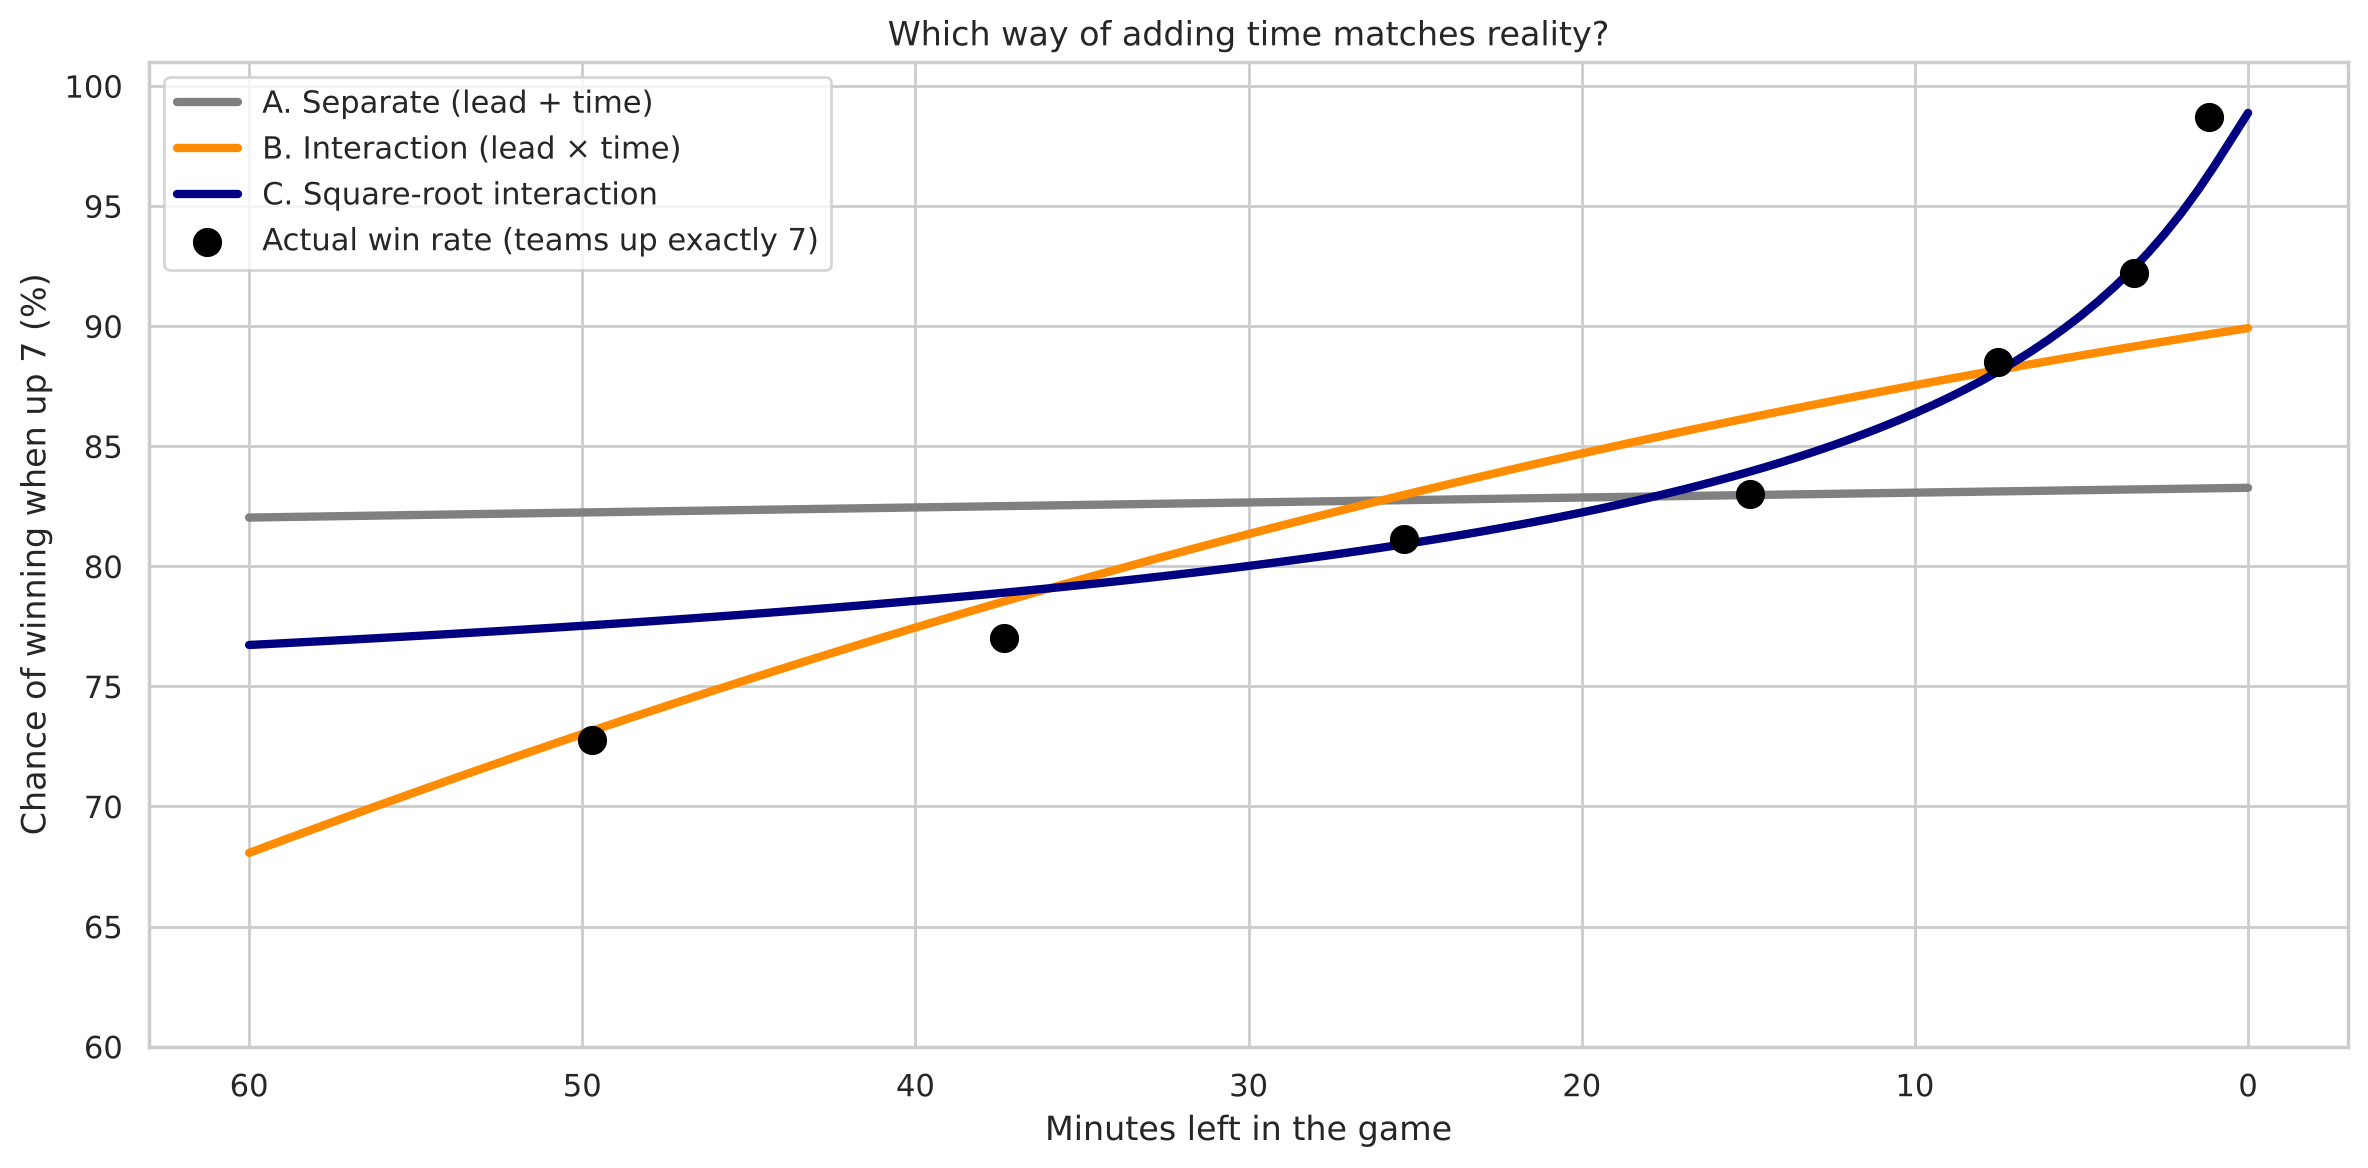

,Brier score on 2025 (lower = better)
A. Separate (lead + time),0.174
B. Interaction (lead × time),0.173
C. Square-root interaction,0.172


In [30]:
time_models = {
    "A. Separate (lead + time)":         smf.logit("won ~ score_differential + min_left", data=wp_train).fit(disp=0),
    "B. Interaction (lead × time)":      smf.logit("won ~ score_differential + score_differential:min_elapsed", data=wp_train).fit(disp=0),
    "C. Square-root interaction":        smf.logit("won ~ score_differential + lead_per_time", data=wp_train).fit(disp=0),
}

# Predicted chance of winning when up 7, at every minute of the game
mins = np.arange(60, -0.5, -0.5)
up7 = add_features(pd.DataFrame({"score_differential": 7, "min_left": mins}))

# What actually happened to teams up exactly 7
real = plays[plays.score_differential == 7]
bins = pd.cut(real.min_left, [-1, 2, 5, 10, 20, 30, 45, 60])
actual = real.groupby(bins, observed=True).agg(min_left=("min_left", "mean"), won=("won", "mean"))

fig, ax = plt.subplots(figsize=(12, 6))
for (name, m), color in zip(time_models.items(), ["gray", "darkorange", "navy"]):
    ax.plot(mins, m.predict(up7) * 100, lw=3, color=color, label=name)
ax.scatter(actual.min_left, actual.won * 100, s=90, color="black", zorder=5, label="Actual win rate (teams up exactly 7)")
ax.invert_xaxis()
ax.set(xlabel="Minutes left in the game", ylabel="Chance of winning when up 7 (%)", ylim=(60, 101),
       title="Which way of adding time matches reality?")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

pd.DataFrame({name: {"Brier score on 2025 (lower = better)": np.mean((m.predict(wp_test) - wp_test.won) ** 2)}
              for name, m in time_models.items()}).T.round(4)

> 🔍 **Check your understanding:** Model A's line is almost flat. Why can't it learn that a lead is safer late in the game?

<details><summary><b>Click to reveal the answer</b></summary>

In Model A, the lead and the time are added separately, so a 7-point lead adds the same amount to the score z at any point in the game. Only by multiplying lead and time together (Models B and C) can the lead's effect change as the clock runs.

</details>

### Step 6: Add the rest of the game situation
Now we add field position, down, distance and timeouts to the square-root model.

| Input | Meaning |
|---|---|
| `score_differential` | lead of the team with the ball |
| `lead_per_time` | lead ÷ √(minutes left + 1) |
| `yardline_100` | yards from the opponent's end zone (smaller = closer to scoring) |
| `C(down)` | which down; `C(...)` treats it as a category, compared with 1st down |
| `ydstogo` | yards needed for a first down |
| `posteam_timeouts_remaining`, `defteam_timeouts_remaining` | timeouts left for each team |

The easiest way to understand the coefficients is a **what-if table**: start from one situation, change **one thing at a time**, and see how the chance of winning moves.

In [31]:
WP_INPUTS = ("score_differential + lead_per_time + yardline_100 + C(down) + ydstogo"
             " + posteam_timeouts_remaining + defteam_timeouts_remaining")
wp_basic = smf.logit("won ~ " + WP_INPUTS, data=wp_train).fit(disp=0)

base = dict(score_differential=0, min_left=8, yardline_100=75, down=1, ydstogo=10,
            posteam_timeouts_remaining=3, defteam_timeouts_remaining=3)
what_ifs = {
    "Start: tied, 8:00 left, 1st & 10 at own 25": {},
    "…but up 3":                                  {"score_differential": 3},
    "…but up 7":                                  {"score_differential": 7},
    "…but ball at the opponent's 25":             {"yardline_100": 25},
    "…but 3rd & 10 instead of 1st & 10":          {"down": 3},
    "…but the defense has 0 timeouts":            {"defteam_timeouts_remaining": 0},
}
rows = pd.DataFrame([{**base, **change} for change in what_ifs.values()], index=list(what_ifs))
p = wp_basic.predict(add_features(rows)).values
table = pd.DataFrame({"chance of winning": p, "change vs. start": p - p[0]}, index=rows.index)
display(table.style.format({"chance of winning": "{:.0%}", "change vs. start": "{:+.0%}"}))

,chance of winning,change vs. start
"Start: tied, 8:00 left, 1st & 10 at own 25",53%,+0%
…but up 3,70%,+17%
…but up 7,86%,+33%
…but ball at the opponent's 25,64%,+11%
…but 3rd & 10 instead of 1st & 10,48%,-5%
…but the defense has 0 timeouts,61%,+8%


### Step 7: Find where the model fails, then fix it
A good analyst checks the model in tricky situations. Two tests, both in the **last 2 minutes**:

* **Late red zone:** the ball is inside the opponent's 10-yard line
* **Late field-goal chance:** the ball is inside the opponent's 35 (field-goal range) and the team is tied or down by 3 or less, so a field goal ties or wins

How often did those teams really win, and what did the model predict?

In [32]:
def situation_check(model, data, column, label):
    s = data[data[column] == 1]
    print(f"{label:32s} actual win rate {s.won.mean():.0%}   model predicted {model.predict(s).mean():.0%}   ({len(s):,} plays)")

for column, label in [("late_red_zone", "Late red zone"), ("late_fg_chance", "Late field-goal chance")]:
    situation_check(wp_basic, wp_train, column, label + " (2016–2024)")
    situation_check(wp_basic, wp_test,  column, label + " (2025)")

Late red zone (2016–2024)        actual win rate 48%   model predicted 36%   (1,584 plays)
Late red zone (2025)             actual win rate 56%   model predicted 39%   (138 plays)
Late field-goal chance (2016–2024) actual win rate 71%   model predicted 50%   (1,325 plays)
Late field-goal chance (2025)    actual win rate 76%   model predicted 48%   (179 plays)


The model is far too pessimistic in both. Why? In our model **each yard counts the same at any time**. But being at the opponent's 5, or in easy field-goal range in a close game, with a minute left is special: a score is likely and the other team has no time to answer.

**The fix is two new inputs**, each 1 in that situation and 0 otherwise:
* `late_red_zone` = inside the 10 with 2 minutes or less left
* `late_fg_chance` = inside the 35, 2 minutes or less left, tied or down by 3 or less

Both are **interactions** (field position × time, and the second one × score), built as yes/no variables.

In [33]:
wp_model = smf.logit("won ~ " + WP_INPUTS + " + late_red_zone + late_fg_chance", data=wp_train).fit(disp=0)

for column, label in [("late_red_zone", "Late red zone"), ("late_fg_chance", "Late field-goal chance")]:
    situation_check(wp_model, wp_train, column, label + " (2016–2024)")
    situation_check(wp_model, wp_test,  column, label + " (2025)")
print(f"\nNew coefficients: late_red_zone {wp_model.params['late_red_zone']:+.2f}, "
      f"late_fg_chance {wp_model.params['late_fg_chance']:+.2f}  (big boosts to the score z in exactly those situations)")

Late red zone (2016–2024)        actual win rate 48%   model predicted 48%   (1,584 plays)
Late red zone (2025)             actual win rate 56%   model predicted 54%   (138 plays)
Late field-goal chance (2016–2024) actual win rate 71%   model predicted 71%   (1,325 plays)
Late field-goal chance (2025)    actual win rate 76%   model predicted 69%   (179 plays)

New coefficients: late_red_zone +1.23, late_fg_chance +0.90  (big boosts to the score z in exactly those situations)


> 🔍 **Check your understanding:** We judged the fix on the 2025 season as well as the training seasons. Why does that matter?

<details><summary><b>Click to reveal the answer</b></summary>

If we only checked the training data, the new variable could just be memorizing quirks of those seasons. Improving on 2025, which the model never saw, shows the fix is real.

</details>

### Step 8: ✏️ Calculate a win probability by hand
This is exactly what the computer does: multiply each coefficient by the situation's value, add them up to get the score $z$, then apply the logistic function. Change the situation and rerun.

In [34]:
# ✏️ Describe a situation (from the point of view of the team with the ball)
situation = dict(
    score_differential = -4,    # down by 4
    min_left           = 2.0,   # 2:00 left in the game
    yardline_100       = 35,    # ball at the opponent's 35
    down               = 1,
    ydstogo            = 10,
    posteam_timeouts_remaining = 2,
    defteam_timeouts_remaining = 3,
)

s = add_features(pd.DataFrame([situation])).iloc[0]
def term_value(name):
    if name == "Intercept":        return 1.0
    if name.startswith("C(down)"): return float(int(name[-2]) == s.down)   # 1 if that's the down, else 0
    return float(s[name])

work = pd.DataFrame({"coefficient": wp_model.params})
work["value"] = [term_value(n) for n in work.index]
work["coef × value"] = work.coefficient * work.value
display(work.round(4))

z = work["coef × value"].sum()
print(f"score z = sum of the last column = {z:.3f}")
print(f"P(win)  = 1 / (1 + e^(−z)) = 1 / (1 + e^({-z:.3f})) = {1 / (1 + np.exp(-z)):.1%}")
print(f"Check with the model:          {wp_model.predict(add_features(pd.DataFrame([situation])))[0]:.1%}")

,coefficient,value,coef × value
Intercept,1.128,1.000,1.128
C(down)[T.2],-0.089,0.000,-0.000
C(down)[T.3],-0.211,0.000,-0.000
C(down)[T.4],-0.415,0.000,-0.000
score_differential,0.052,-4.000,-0.209
lead_per_time,0.595,-2.309,-1.375
yardline_100,-0.009,35.000,-0.320
ydstogo,-0.010,10.000,-0.099
posteam_timeouts_remaining,0.024,2.000,0.048
defteam_timeouts_remaining,-0.094,3.000,-0.283


score z = sum of the last column = -1.110
P(win)  = 1 / (1 + e^(−z)) = 1 / (1 + e^(1.110)) = 24.8%
Check with the model:          24.8%


A function version for quick experiments. ✏️ Try your own situations.

In [35]:
def win_prob(lead, minutes_left, yardline_100=75, down=1, ydstogo=10, timeouts_off=3, timeouts_def=3):
    """Chance the team with the ball wins, from our logistic regression model."""
    s = pd.DataFrame([dict(score_differential=lead, min_left=minutes_left, yardline_100=yardline_100, down=down,
                           ydstogo=ydstogo, posteam_timeouts_remaining=timeouts_off,
                           defteam_timeouts_remaining=timeouts_def)])
    return float(wp_model.predict(add_features(s))[0])

print(f"Tied, opening drive, 1st & 10 at own 25:     {win_prob(0, 60):.0%}")
print(f"Up 7, 1st & 10 at own 25, 10 minutes left:   {win_prob(7, 10):.0%}")
print(f"Up 7, same spot, 2 minutes left:             {win_prob(7, 2):.0%}")
print(f"Down 4, 1st & goal at the 5, 1:00 left:      {win_prob(-4, 1, yardline_100=5, ydstogo=5):.0%}")

Tied, opening drive, 1st & 10 at own 25:     53%
Up 7, 1st & 10 at own 25, 10 minutes left:   85%
Up 7, same spot, 2 minutes left:             95%
Down 4, 1st & goal at the 5, 1:00 left:      54%


### Step 9: The whole picture
Our model's chance of winning for every lead and time left (1st & 10 at your own 25, all timeouts). Compare it with the counting table from Step 1: same pattern, but now **every** situation has an answer.

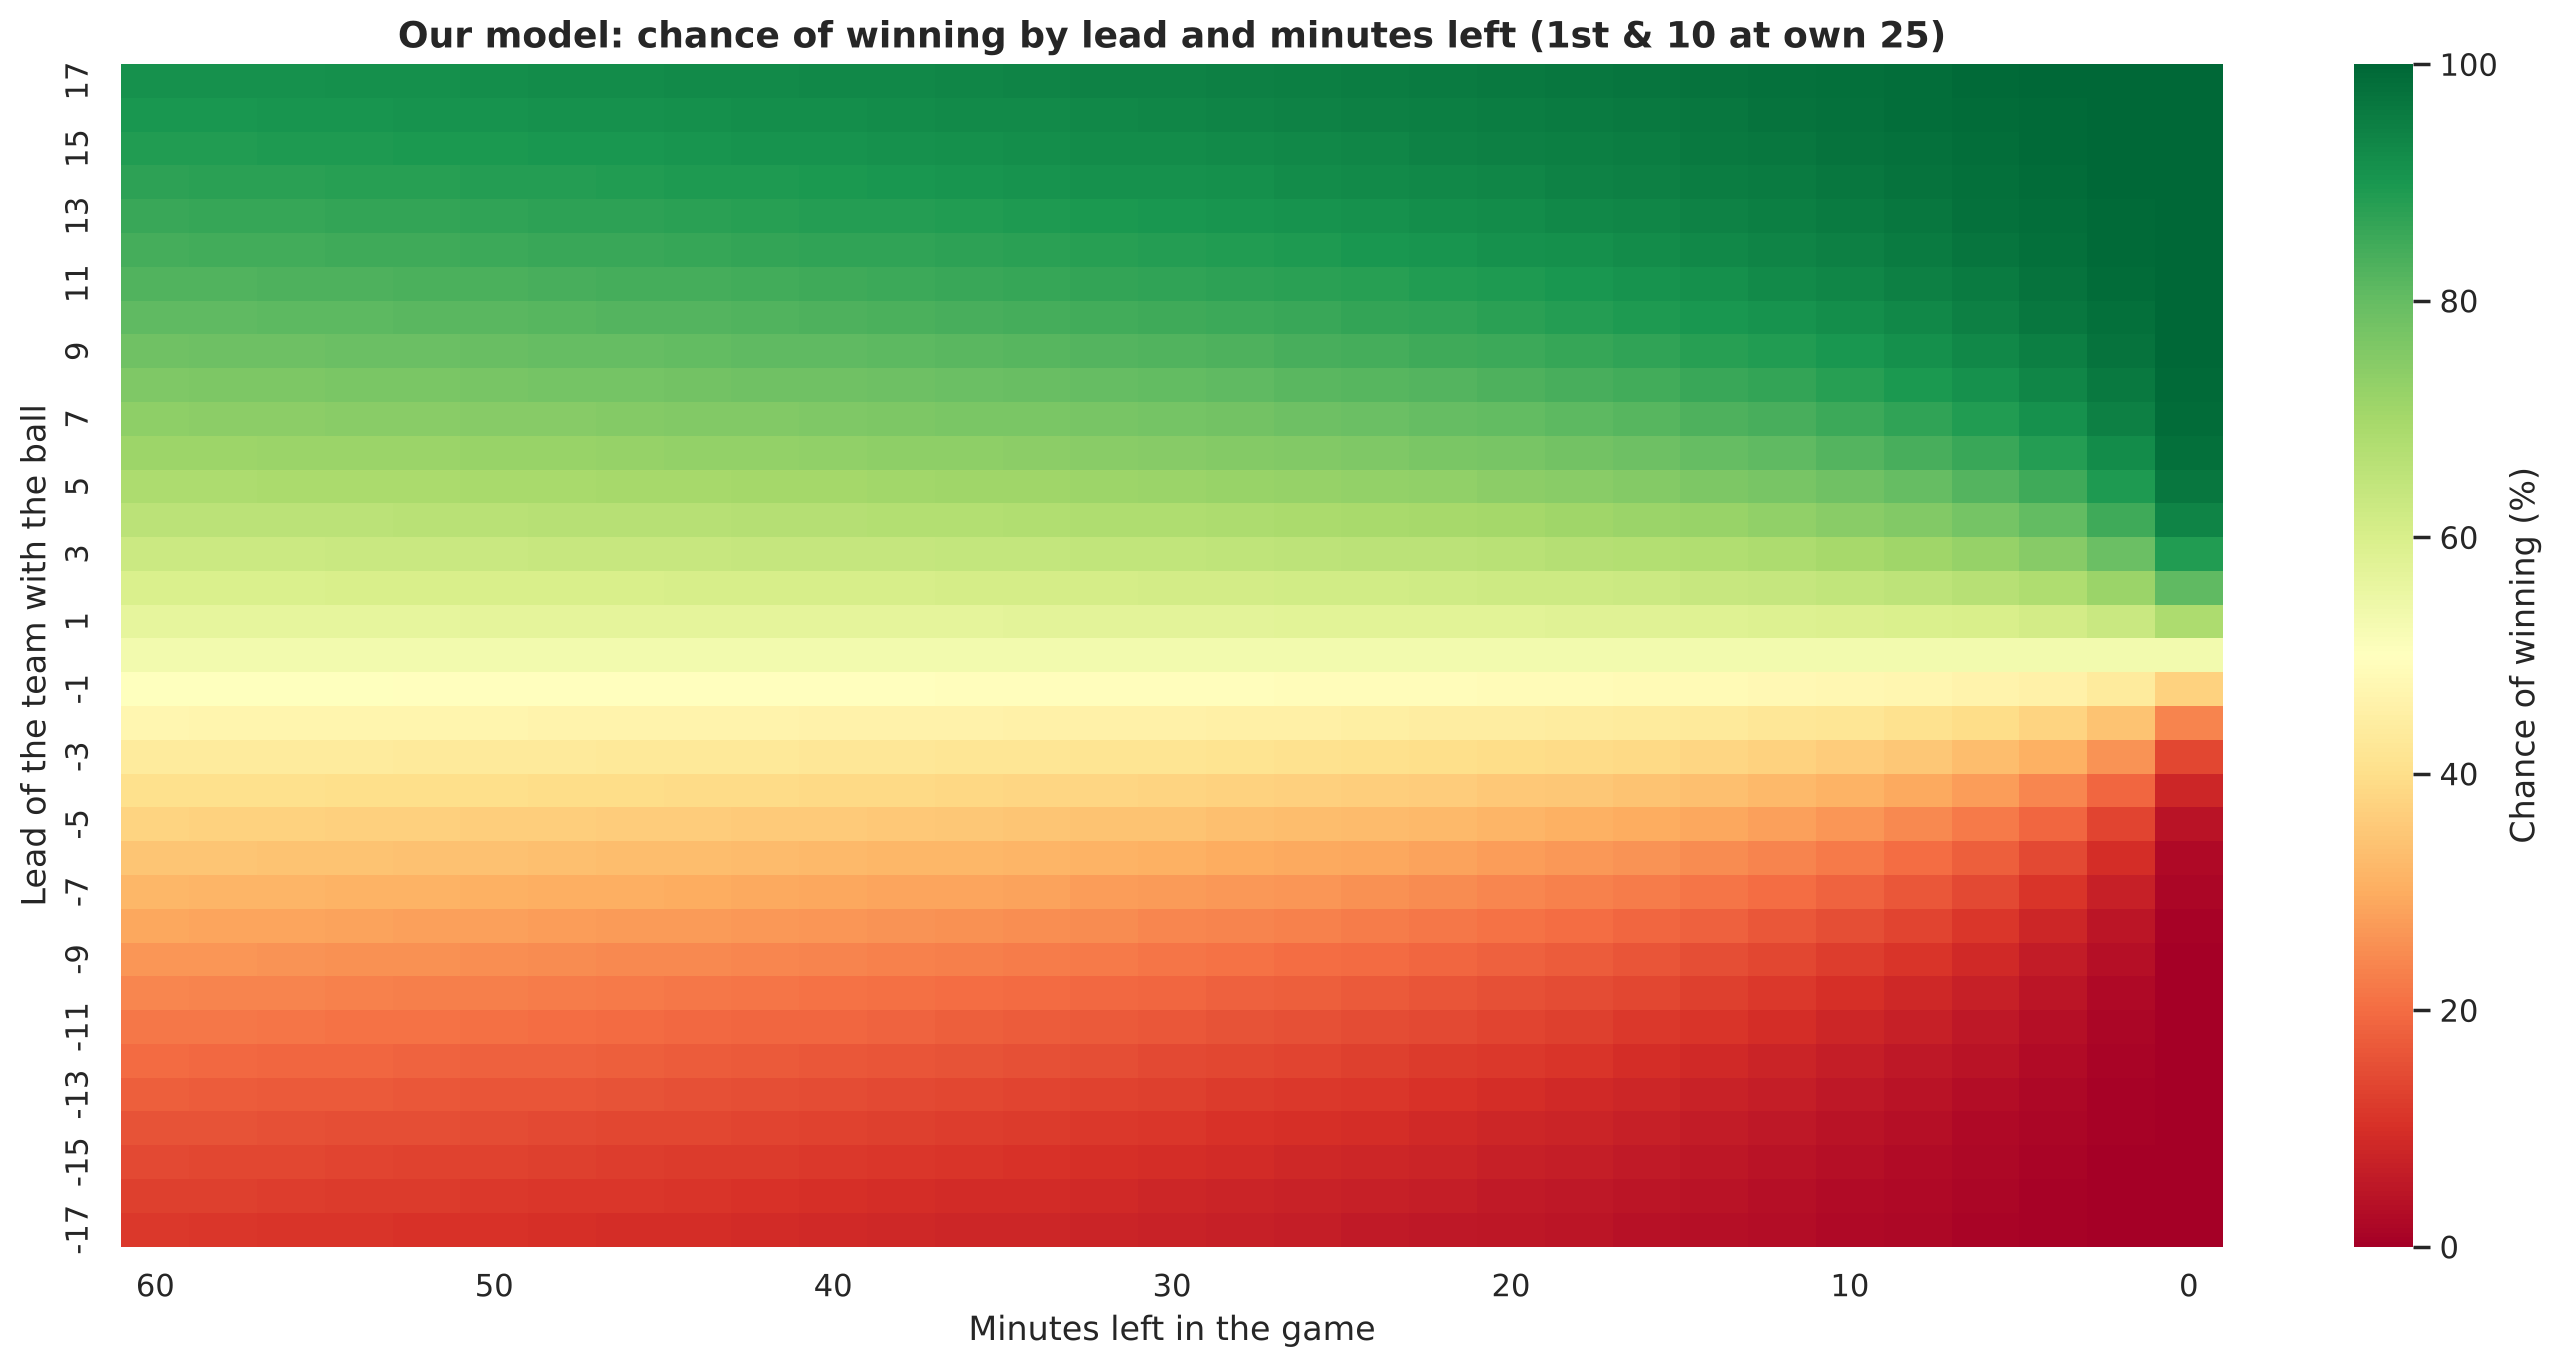

In [36]:
leads = np.arange(-17, 18)
mins_grid = np.arange(60, -1, -2)
grid = pd.DataFrame([(l, m) for l in leads for m in mins_grid], columns=["score_differential", "min_left"])
grid = grid.assign(yardline_100=75, down=1, ydstogo=10, posteam_timeouts_remaining=3, defteam_timeouts_remaining=3)
grid["wp"] = wp_model.predict(add_features(grid))
heat = grid.pivot(index="score_differential", columns="min_left", values="wp").sort_index(ascending=False)[mins_grid]

plt.figure(figsize=(14, 7))
sns.heatmap(heat * 100, cmap="RdYlGn", vmin=0, vmax=100, cbar_kws={"label": "Chance of winning (%)"},
            xticklabels=5, yticklabels=2)
plt.title("Our model: chance of winning by lead and minutes left (1st & 10 at own 25)", fontsize=13, weight="bold")
plt.xlabel("Minutes left in the game"); plt.ylabel("Lead of the team with the ball")
plt.tight_layout(); plt.show()

### Step 10: How good is our model?
We test every version on the 2025 season, which none of them saw.

* **Brier score**: the average of (predicted probability − actual outcome)². Lower is better. Always guessing 50% scores 0.25.
* **Calibration**: when the model says 70%, do those teams really win about 70% of the time? If so, the dots sit on the diagonal.

As a **yardstick only**, the last row shows nflverse's professional win-probability model (a machine-learning model with more inputs). We don't use it anywhere else.

,"Brier score, 2025 (lower = better)"
Linear regression (lead only),0.180
Logistic: lead only,0.174
Logistic: lead + time (Model C),0.172
Logistic: full situation,0.171
Logistic: full + late-game fixes,0.171
Yardstick: nflverse professional,0.169


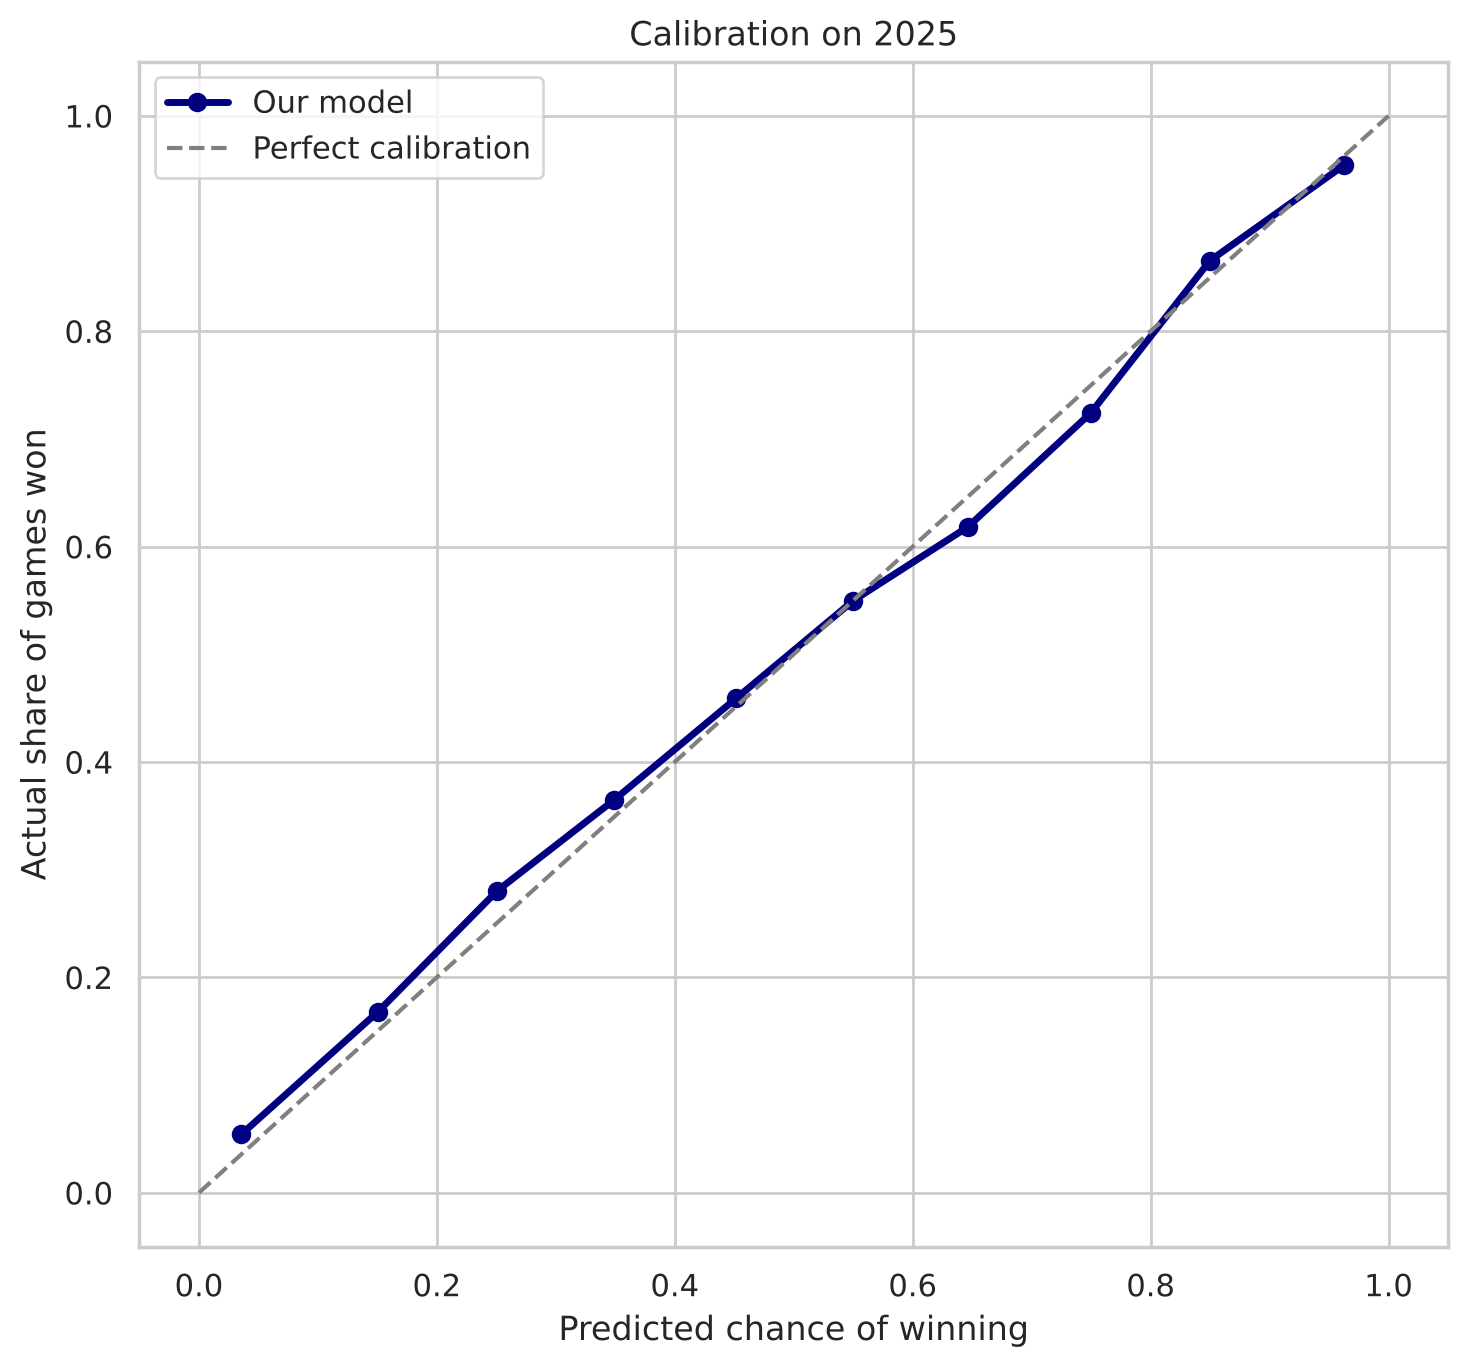

In [37]:
test_preds = {
    "Linear regression (lead only)":       lpm.predict(wp_test),
    "Logistic: lead only":                 logit_lead.predict(wp_test),
    "Logistic: lead + time (Model C)":     time_models["C. Square-root interaction"].predict(wp_test),
    "Logistic: full situation":            wp_basic.predict(wp_test),
    "Logistic: full + late-game fixes":    wp_model.predict(wp_test),
    "Yardstick: nflverse professional":    wp_test.wp,
}
display(pd.Series({n: np.mean((p - wp_test.won) ** 2) for n, p in test_preds.items()},
                  name="Brier score, 2025 (lower = better)").round(4).to_frame())

fig, ax = plt.subplots(figsize=(7.5, 7))
p = test_preds["Logistic: full + late-game fixes"]
b = pd.cut(p, np.linspace(0, 1, 11))
ax.plot(p.groupby(b, observed=True).mean(), wp_test.won.groupby(b, observed=True).mean(), "o-", color="navy", lw=2.5,
        label="Our model")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set(xlabel="Predicted chance of winning", ylabel="Actual share of games won", title="Calibration on 2025")
ax.legend(); plt.tight_layout(); plt.show()

> 🔍 **Check your understanding:** Adding time and then the game situation each lowered the Brier score, but the late-game fixes barely changed it. Were they worth it?

<details><summary><b>Click to reveal the answer</b></summary>

Yes. Those plays are rare (well under 1% of snaps), so fixing them hardly moves the season-wide average. But they are exactly the moments that decide games, and the model went from badly wrong to close. Without the fixes, Part 7's list of biggest plays would be full of routine last-second field goals. An overall score can hide big errors in small but important situations, so check the situations you care about, too.

</details>

### Step 11: From win probability to the win-probability **swing** (WPA)
💡 **Key idea:** once we have a win probability before every snap, measuring a play is just subtraction:

$$\text{WPA (win probability added)} = \text{WP after the play} - \text{WP before the play}$$

"WP after the play" is the win probability at the **next snap**. One wrinkle: the next snap might belong to the **other team**. Then we flip it, because the two teams' chances add up to 100%:

Example with round numbers:

| | Team with the ball | Their chance of winning | Bears' chance |
|---|---|---|---|
| Before the play | Bears | 66% | **66%** |
| Bears throw an interception | | | |
| Next snap | Eagles | 60% | 100% − 60% = **40%** |
| **Swing for the Bears** | | | 40% − 66% = **−26%** |

After the last snap of a game, "after" is simply 1 (won) or 0 (lost), or 0.5 if the game went to overtime (the score was tied when regulation ended). Because extra points and kickoffs happen between snaps, a touchdown's swing includes its extra point.

In [38]:
g25 = wp_test.sort_values(["game_id", "play_id"]).copy()
g25["wp_before"] = wp_model.predict(g25)
nxt = g25.groupby("game_id")
g25["next_wp"], g25["next_team"] = nxt.wp_before.shift(-1), nxt.posteam.shift(-1)
g25["wp_after"] = np.where(g25.next_team == g25.posteam, g25.next_wp, 1 - g25.next_wp)   # flip on change of possession
last = g25.next_wp.isna()                                                                # last snap of regulation
g25.loc[last, "wp_after"] = np.where(g25.loc[last, "game_id"].isin(ot_games), 0.5, g25.loc[last, "won"])
g25["wpa"] = g25.wp_after - g25.wp_before

# Worked example: the biggest swing of 2025 in the first three quarters
ex = g25[(g25.qtr <= 3) & ~last].loc[lambda d: d.wpa.abs().idxmax()]
lead = "tied" if ex.score_differential == 0 else (f"up {ex.score_differential:.0f}" if ex.score_differential > 0 else f"down {-ex.score_differential:.0f}")
print(f"Week {ex.week}, {ex.posteam} vs {ex.defteam}, Q{ex.qtr:.0f} {ex.time}: {ex.posteam} {lead}, "
      f"{ex.down}-and-{ex.ydstogo:.0f}, {ex.yardline_100:.0f} yards from the end zone")
print(f"Play: {ex.desc[:150]}")
print(f"\nWP before = {ex.wp_before:.1%}")
print(f"WP after  = {ex.wp_after:.1%}   ({ex.posteam}'s view at the next snap)")
print(f"WPA       = {ex.wp_after:.1%} − {ex.wp_before:.1%} = {ex.wpa:+.1%}")

# Sanity check: a team's swings over a season should add up to roughly its wins
g25["home_wpa"] = np.where(g25.posteam == g25.home_team, g25.wpa, -g25.wpa)
team_wpa = pd.concat([g25.groupby("home_team").home_wpa.sum(), -g25.groupby("away_team").home_wpa.sum()]).groupby(level=0).sum()
print(f"\nCheck: correlation between each team's total 2025 WPA and its 2025 wins = "
      f"{team_wpa.corr(full[full.season == 2025].set_index('team').win):.3f}  (should be close to 1)")

Week 5, KC vs JAX, Q3 02:36: KC tied, 2-and-3, 3 yards from the end zone
Play: (2:36) (Shotgun) 15-P.Mahomes pass short middle intended for 9-J.Smith-Schuster INTERCEPTED by 0-D.Lloyd at JAX 1. 0-D.Lloyd for 99 yards, TOUCHDOWN.

WP before = 68.4%
WP after  = 22.1%   (KC's view at the next snap)
WPA       = 22.1% − 68.4% = -46.2%

Check: correlation between each team's total 2025 WPA and its 2025 wins = 0.986  (should be close to 1)


> 🔍 **Check your understanding:** Why should a team's WPA over a whole season add up to (roughly) its number of wins?

<details><summary><b>Click to reveal the answer</b></summary>

Within a game, the swings chain together: each play's 'after' is the next play's 'before'. So a team's swings in one game add up to its final result (1 or 0) minus its starting chance (about 50%). Over a season, that's wins minus about half the games, so WPA tracks wins.

</details>

## Part 7 · The most important plays of 2025

Every swing in this part comes from **the model you just built**: win probability after each play minus before it. (Our model covers regulation only, so overtime plays aren't included.)

### Label every play

In [39]:
p25 = g25[(g25.qb_kneel == 0) & (g25.qb_spike == 0)].copy()   # kneel-downs and spikes aren't real plays

# Order matters: an intercepted 3rd-down pass counts as an interception.
rules = [
    ("Interception thrown",           p25.interception == 1),
    ("Fumble lost",                   p25.fumble_lost == 1),
    ("Sack taken",                    p25.sack == 1),
    ("Passing TD",                    p25.pass_touchdown == 1),
    ("Rushing TD",                    p25.rush_touchdown == 1),
    ("4th-down conversion",           p25.fourth_down_converted == 1),
    ("4th-down failed",               p25.fourth_down_failed == 1),
    ("Field goal made",               p25.field_goal_result == "made"),
    ("Field goal missed/blocked",     p25.play_type == "field_goal"),
    ("Punt",                          p25.play_type == "punt"),
    ("Deep completion (20+ air yds)", (p25.complete_pass == 1) & (p25.air_yards >= 20)),
    ("3rd-down conversion",           p25.third_down_converted == 1),
    ("3rd-down failed",               p25.third_down_failed == 1),
    ("Other completion",              p25.complete_pass == 1),
    ("Incompletion",                  p25.incomplete_pass == 1),
    ("Run / scramble",                (p25.rush_attempt == 1) | (p25.qb_scramble == 1)),
]
p25["category"] = np.select([c for _, c in rules], [n for n, _ in rules], default="Other (penalty, etc.)")
p25["qtr"] = p25.qtr.astype(int)
p25["score_differential"] = p25.score_differential.astype(int)
print(f"{len(p25):,} plays from 2025")
p25.category.value_counts()

37,966 plays from 2025


category
Run / scramble                   11545
Other completion                  7215
Incompletion                      3846
3rd-down failed                   3398
Other (penalty, etc.)             2397
3rd-down conversion               2232
Punt                              1908
Sack taken                        1203
Field goal made                    921
Passing TD                         800
Deep completion (20+ air yds)      532
Rushing TD                         502
4th-down conversion                394
Interception thrown                377
4th-down failed                    311
Fumble lost                        229
Field goal missed/blocked          156
Name: count, dtype: int64

### The 15 biggest plays of the season

In [40]:
top = p25.assign(abs_wpa=p25.wpa.abs()).nlargest(15, "abs_wpa")

rows = ""
for _, r in top.iterrows():
    helped = r.posteam if r.wpa > 0 else r.defteam            # team whose win chances went UP
    col = COLOR.get(helped, "#555")
    lead = f"up {r.score_differential}" if r.score_differential > 0 else ("tied" if r.score_differential == 0 else f"down {-r.score_differential}")
    rows += f"""
    <tr>
      <td>{int(r.week)}</td>
      <td style="white-space:nowrap">{logo_html(r.posteam, 26)} <span style="color:#888">vs</span> {logo_html(r.defteam, 26)}</td>
      <td>Q{r.qtr} {r.time}<br><span style="color:#888;font-size:11px">{r.posteam} {lead}</span></td>
      <td><b>{r.category}</b></td>
      <td style="font-size:12px">{r.wp_before:.0%} → {r.wp_after:.0%}</td>
      <td style="min-width:150px">
        <div style="display:flex;align-items:center;gap:6px">{logo_html(helped, 22)}
          <div style="background:{col};height:14px;width:{abs(r.wpa) * 120:.0f}px;border-radius:3px"></div>
          <b>{abs(r.wpa) * 100:.0f}%</b></div></td>
      <td style="font-size:11px;text-align:left;max-width:420px">{r.desc[:160]}</td>
    </tr>"""

display(HTML(f"""
<h3 style="font-family:sans-serif">The 15 biggest plays of 2025 (our model)</h3>
<table style="border-collapse:collapse;font-family:sans-serif;font-size:13px;text-align:center">
  <tr style="background:#1f2937;color:white">
    <th>Wk</th><th>Offense vs Defense</th><th>Situation</th><th>Play</th><th>Offense WP<br>before → after</th>
    <th>Swing (team helped)</th><th>Description</th>
  </tr>
  {rows}
</table>"""))

Wk,Offense vs Defense,Situation,Play,Offense WPbefore → after,Swing (team helped),Description
3,vs,Q4 00:03LA down 1,Field goal missed/blocked,71% → 0%,71%,"(:03) 16-J.Karty 44 yard field goal is BLOCKED (90-J.Davis), Center-47-A.Ward, Holder-42-E.Evans, RECOVERED by PHI-90-J.Davis at PHI 39. 90-J.Davis for 61 yards"
2,vs,Q4 00:09TB down 5,Rushing TD,30% → 100%,70%,"(:09) 1-R.White right guard for 2 yards, TOUCHDOWN."
5,vs,Q4 01:07LA down 3,Fumble lost,86% → 22%,64%,"(1:07) 23-K.Williams up the middle to SF 2 for 1 yard (95-A.Collins). FUMBLES (95-A.Collins), RECOVERED by SF-95-A.Collins at SF 1."
2,vs,Q4 00:33NYG down 4,Passing TD,14% → 77%,63%,"(:33) (Shotgun) 3-R.Wilson pass deep right to 1-M.Nabers for 48 yards, TOUCHDOWN."
18,vs,Q4 00:02BAL down 2,Field goal missed/blocked,58% → 0%,58%,"(:02) 33-T.Loop 44 yard field goal is No Good, Wide Right, Center-46-N.Moore, Holder-11-J.Stout."
11,vs,Q4 01:15CAR down 5,Passing TD,15% → 72%,57%,"(1:15) (Shotgun) 9-B.Young pass short left to 4-T.McMillan for 12 yards, TOUCHDOWN."
2,vs,Q4 02:50NYG down 4,Passing TD,22% → 72%,49%,"(2:50) (Shotgun) 3-R.Wilson pass deep right to 17-W.Robinson for 32 yards, TOUCHDOWN."
14,vs,Q4 05:35CIN up 3,Interception thrown,81% → 31%,49%,"(5:35) 9-J.Burrow pass short right intended for 1-J.Chase INTERCEPTED by 47-C.Benford at BUF 37. 47-C.Benford for 63 yards, TOUCHDOWN."
1,vs,Q4 00:03BUF down 2,Field goal made,52% → 100%,48%,"(:03) 15-M.Prater 32 yard field goal is GOOD, Center-69-R.Ferguson, Holder-40-B.Robbins."
3,vs,Q4 00:04SF down 2,Field goal made,53% → 100%,47%,"(:04) 18-E.Pineiro 35 yard field goal is GOOD, Center-46-J.Weeks, Holder-7-T.Morstead."


The "before → after" column is the whole calculation: the swing is just the difference. A big drop for the offense (an interception, a fumble) is a big gain for the **defense**.

### Which kinds of plays matter most?

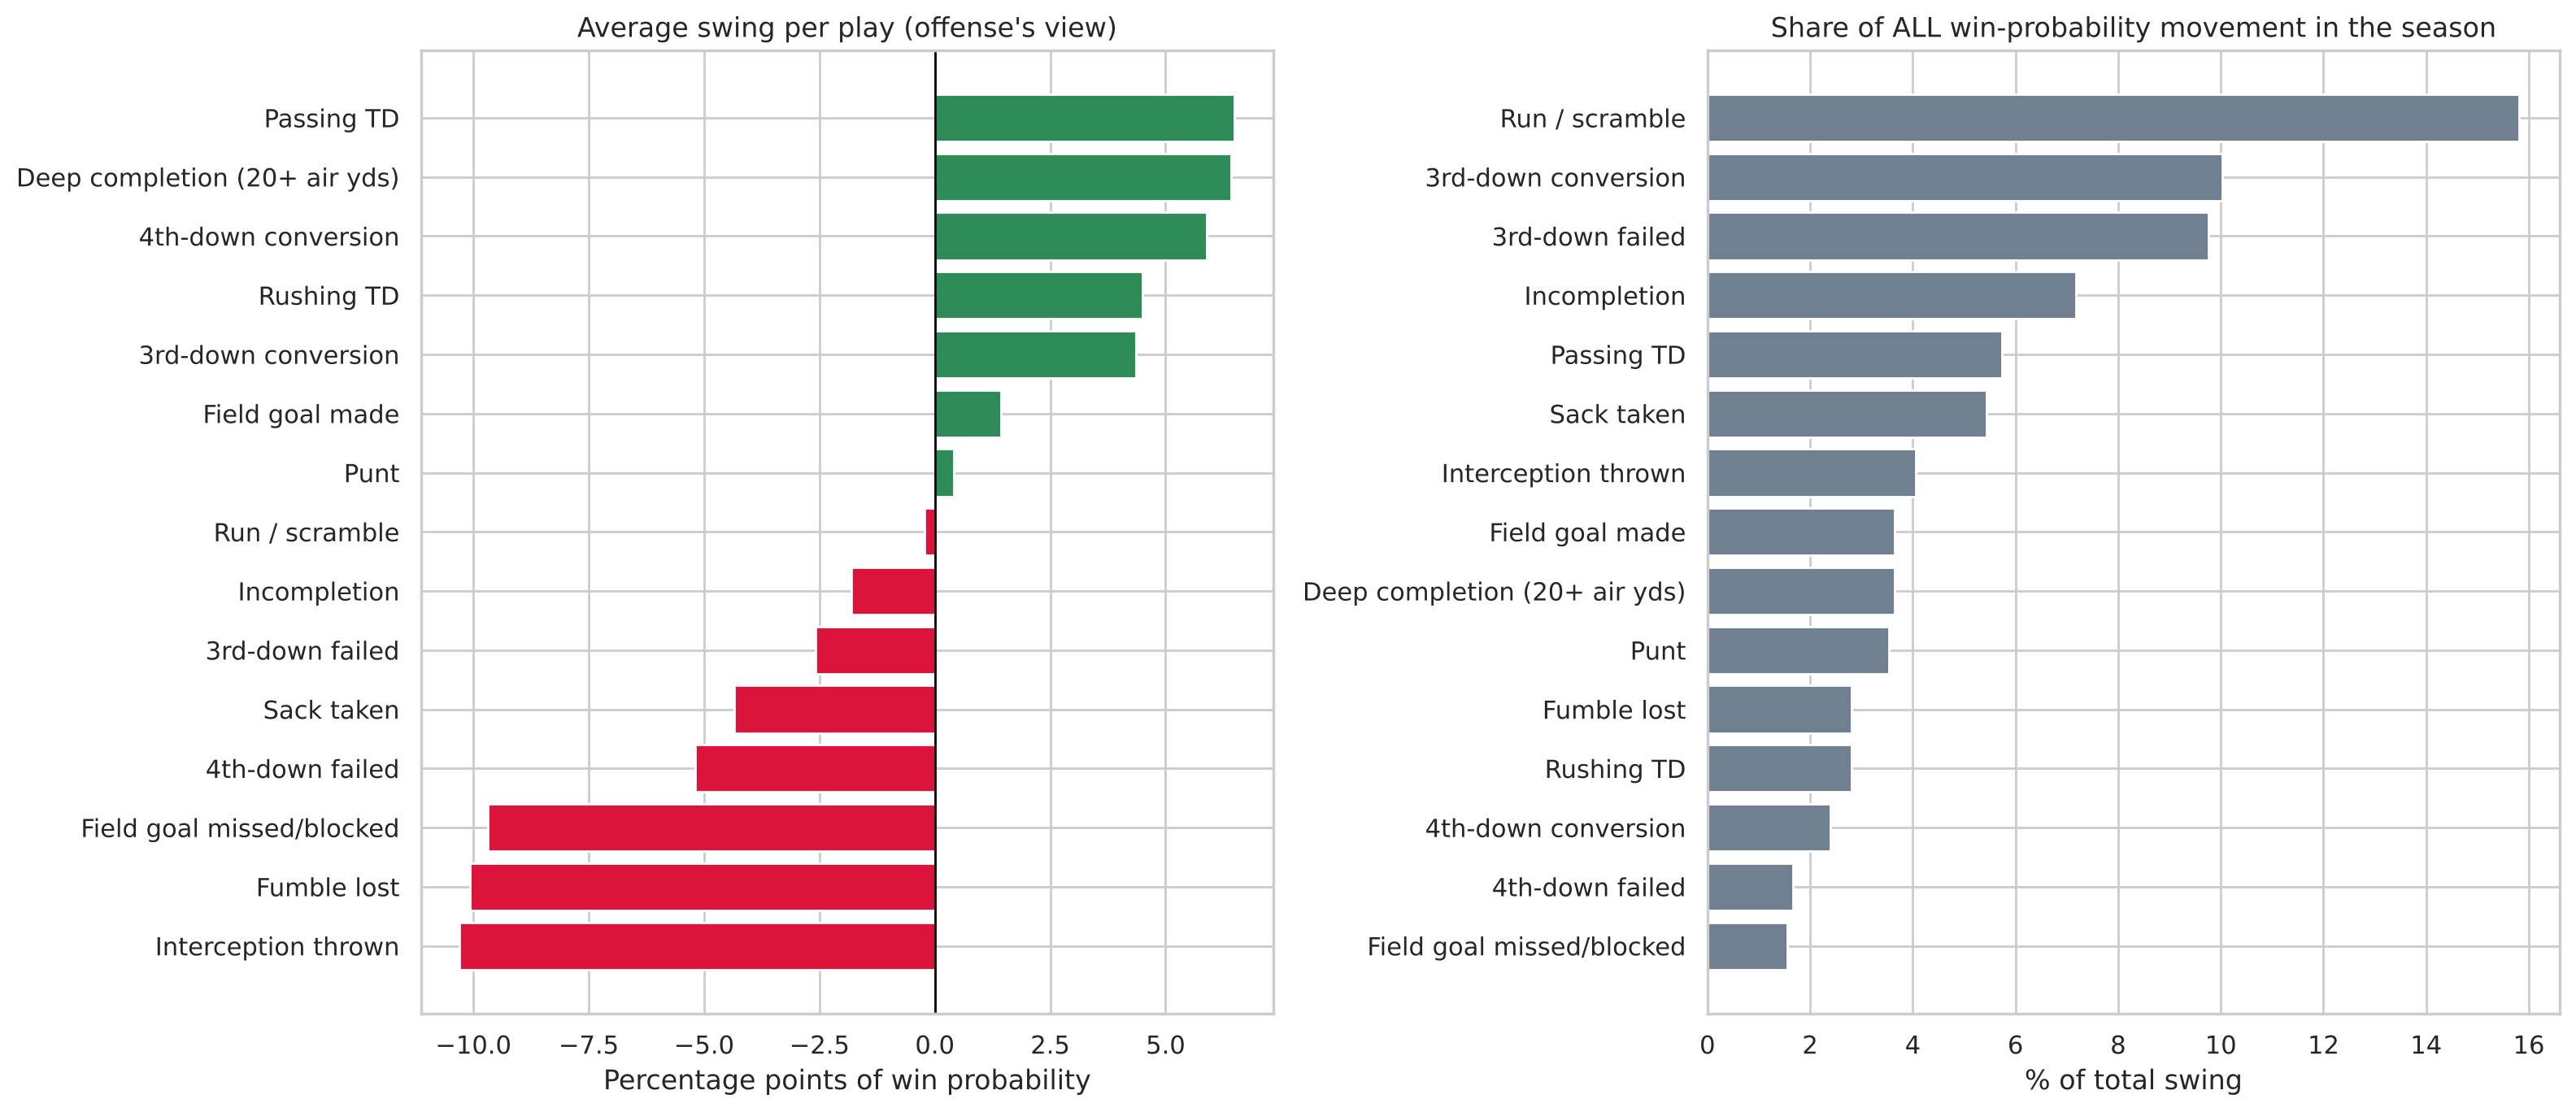

,plays,avg_wpa,total_abs_wpa,share_of_swing
category,,,,
Interception thrown,377,-0.103,39.372,0.041
Fumble lost,229,-0.101,27.317,0.028
Field goal missed/blocked,156,-0.097,15.119,0.016
Passing TD,800,0.065,55.686,0.057
Deep completion (20+ air yds),532,0.064,35.375,0.036
4th-down conversion,394,0.059,23.260,0.024
4th-down failed,311,-0.052,16.205,0.017
Rushing TD,502,0.045,27.222,0.028
3rd-down conversion,2232,0.044,97.419,0.100


In [41]:
by_cat = (p25.groupby("category")
             .agg(plays=("wpa", "size"),
                  avg_wpa=("wpa", "mean"),
                  total_abs_wpa=("wpa", lambda x: x.abs().sum()))
             .assign(share_of_swing=lambda d: d.total_abs_wpa / d.total_abs_wpa.sum()))
by_cat = by_cat[~by_cat.index.str.startswith("Other")].sort_values("avg_wpa")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = ["crimson" if v < 0 else "seagreen" for v in by_cat.avg_wpa]
axes[0].barh(by_cat.index, by_cat.avg_wpa * 100, color=colors)
axes[0].axvline(0, color="black", lw=1)
axes[0].set(title="Average swing per play (offense's view)", xlabel="Percentage points of win probability")

share = by_cat.sort_values("share_of_swing")
axes[1].barh(share.index, share.share_of_swing * 100, color="slategray")
axes[1].set(title="Share of ALL win-probability movement in the season", xlabel="% of total swing")
plt.tight_layout(); plt.show()

by_cat.sort_values("avg_wpa", key=abs, ascending=False).round(4)

> **Two ways to say "most important":**
> * **Left (per play):** turnovers, touchdowns and missed kicks swing games the most **each time** they happen.
> * **Right (in total):** ordinary runs and completions happen so often that together they move win probability the most.

### When do plays matter most? Late and close

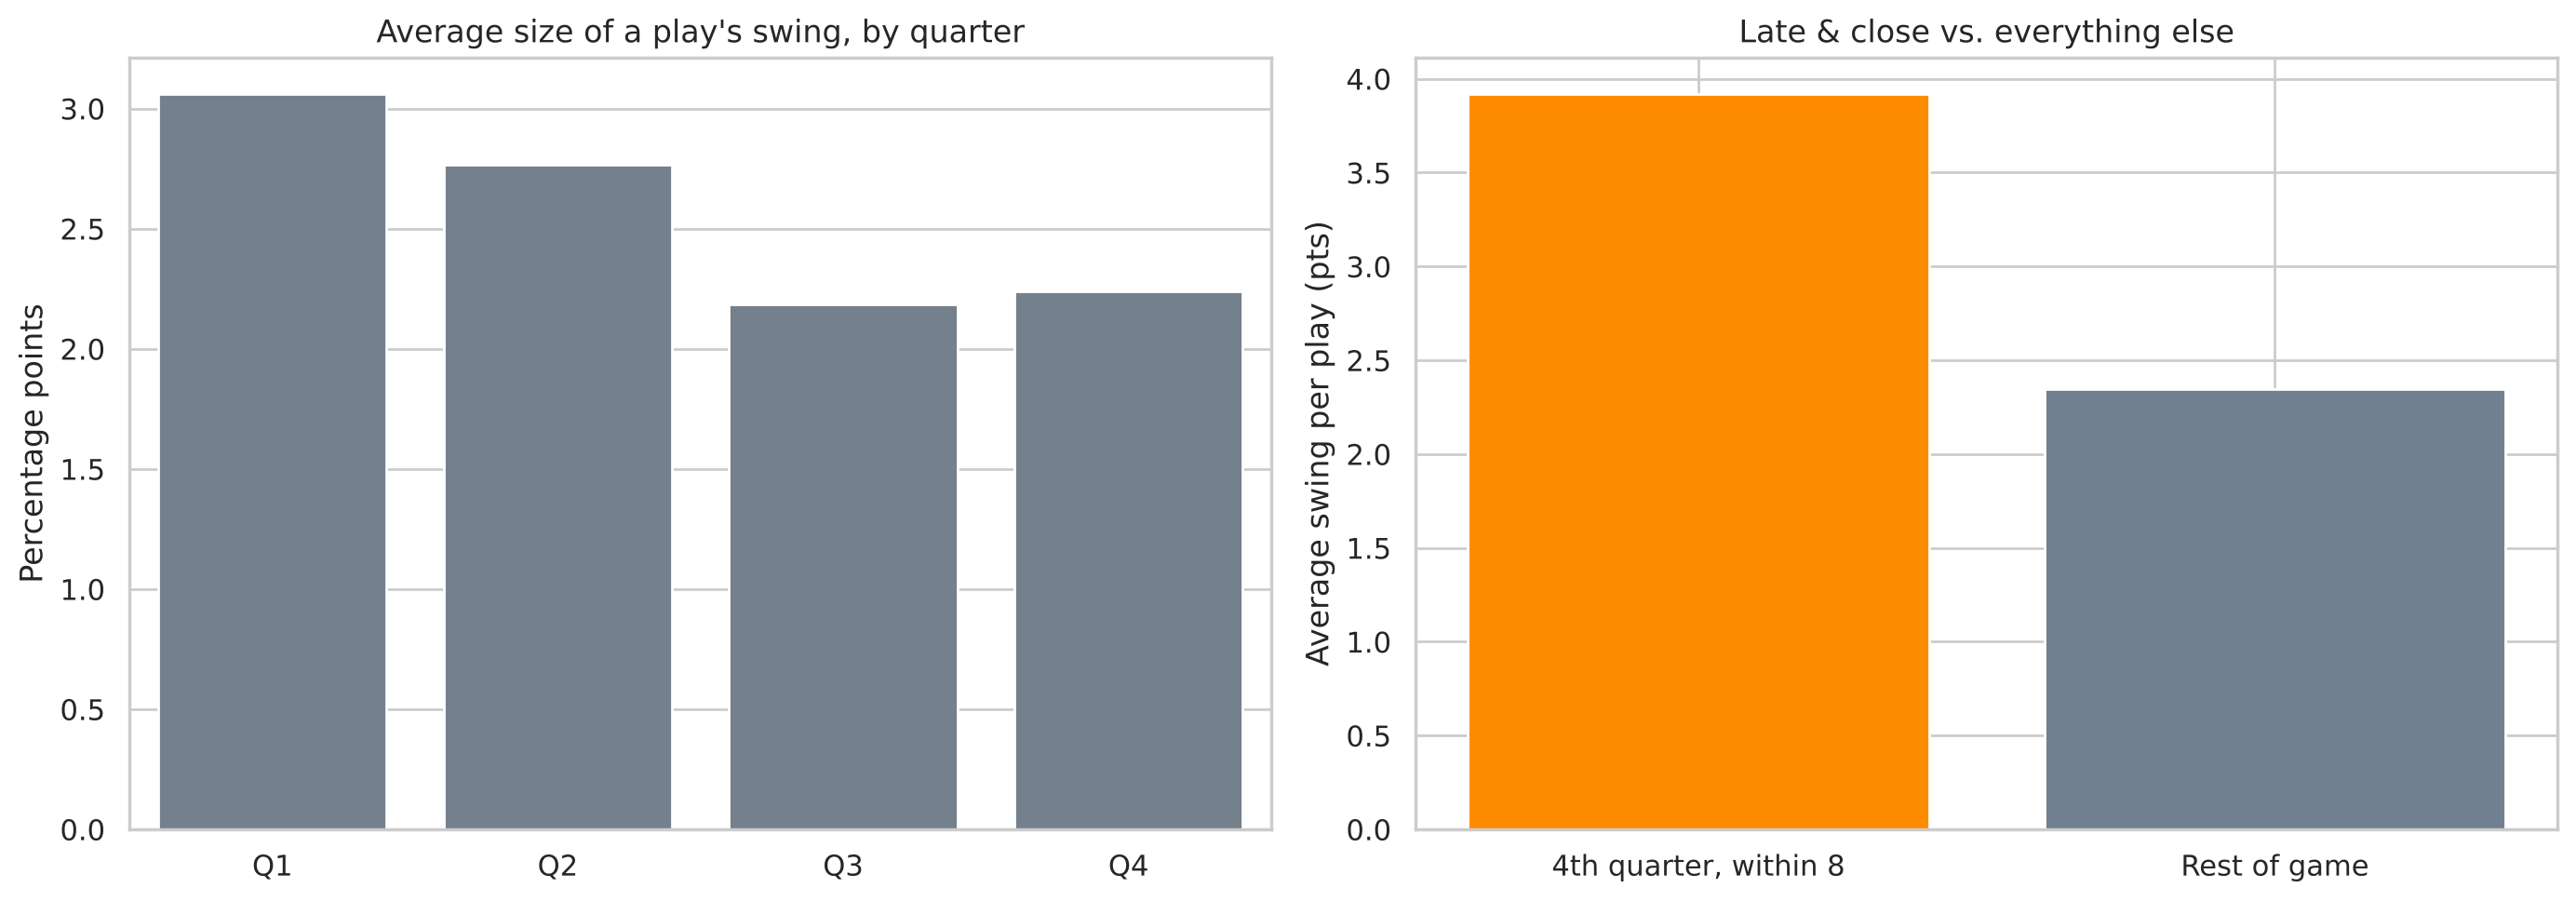

A play in a close 4th quarter swings win probability 1.7× as much as a typical play.


In [42]:
p25["situation"] = np.where((p25.qtr == 4) & (p25.score_differential.abs() <= 8), "4th quarter, within 8", "Rest of game")
p25["quarter"] = "Q" + p25.qtr.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=p25, x="quarter", y=p25.wpa.abs() * 100, order=["Q1", "Q2", "Q3", "Q4"],
            errorbar=None, color="slategray", ax=axes[0])
axes[0].set(title="Average size of a play's swing, by quarter", xlabel="", ylabel="Percentage points")

lev = p25.groupby("situation").agg(plays=("wpa", "size"), avg_abs_wpa=("wpa", lambda x: x.abs().mean() * 100))
axes[1].bar(lev.index, lev.avg_abs_wpa, color=["darkorange", "slategray"])
axes[1].set(title="Late & close vs. everything else", ylabel="Average swing per play (pts)")
plt.tight_layout(); plt.show()

ratio = lev.loc["4th quarter, within 8", "avg_abs_wpa"] / lev.loc["Rest of game", "avg_abs_wpa"]
print(f"A play in a close 4th quarter swings win probability {ratio:.1f}× as much as a typical play.")

### Win-probability chart for the game with the biggest play

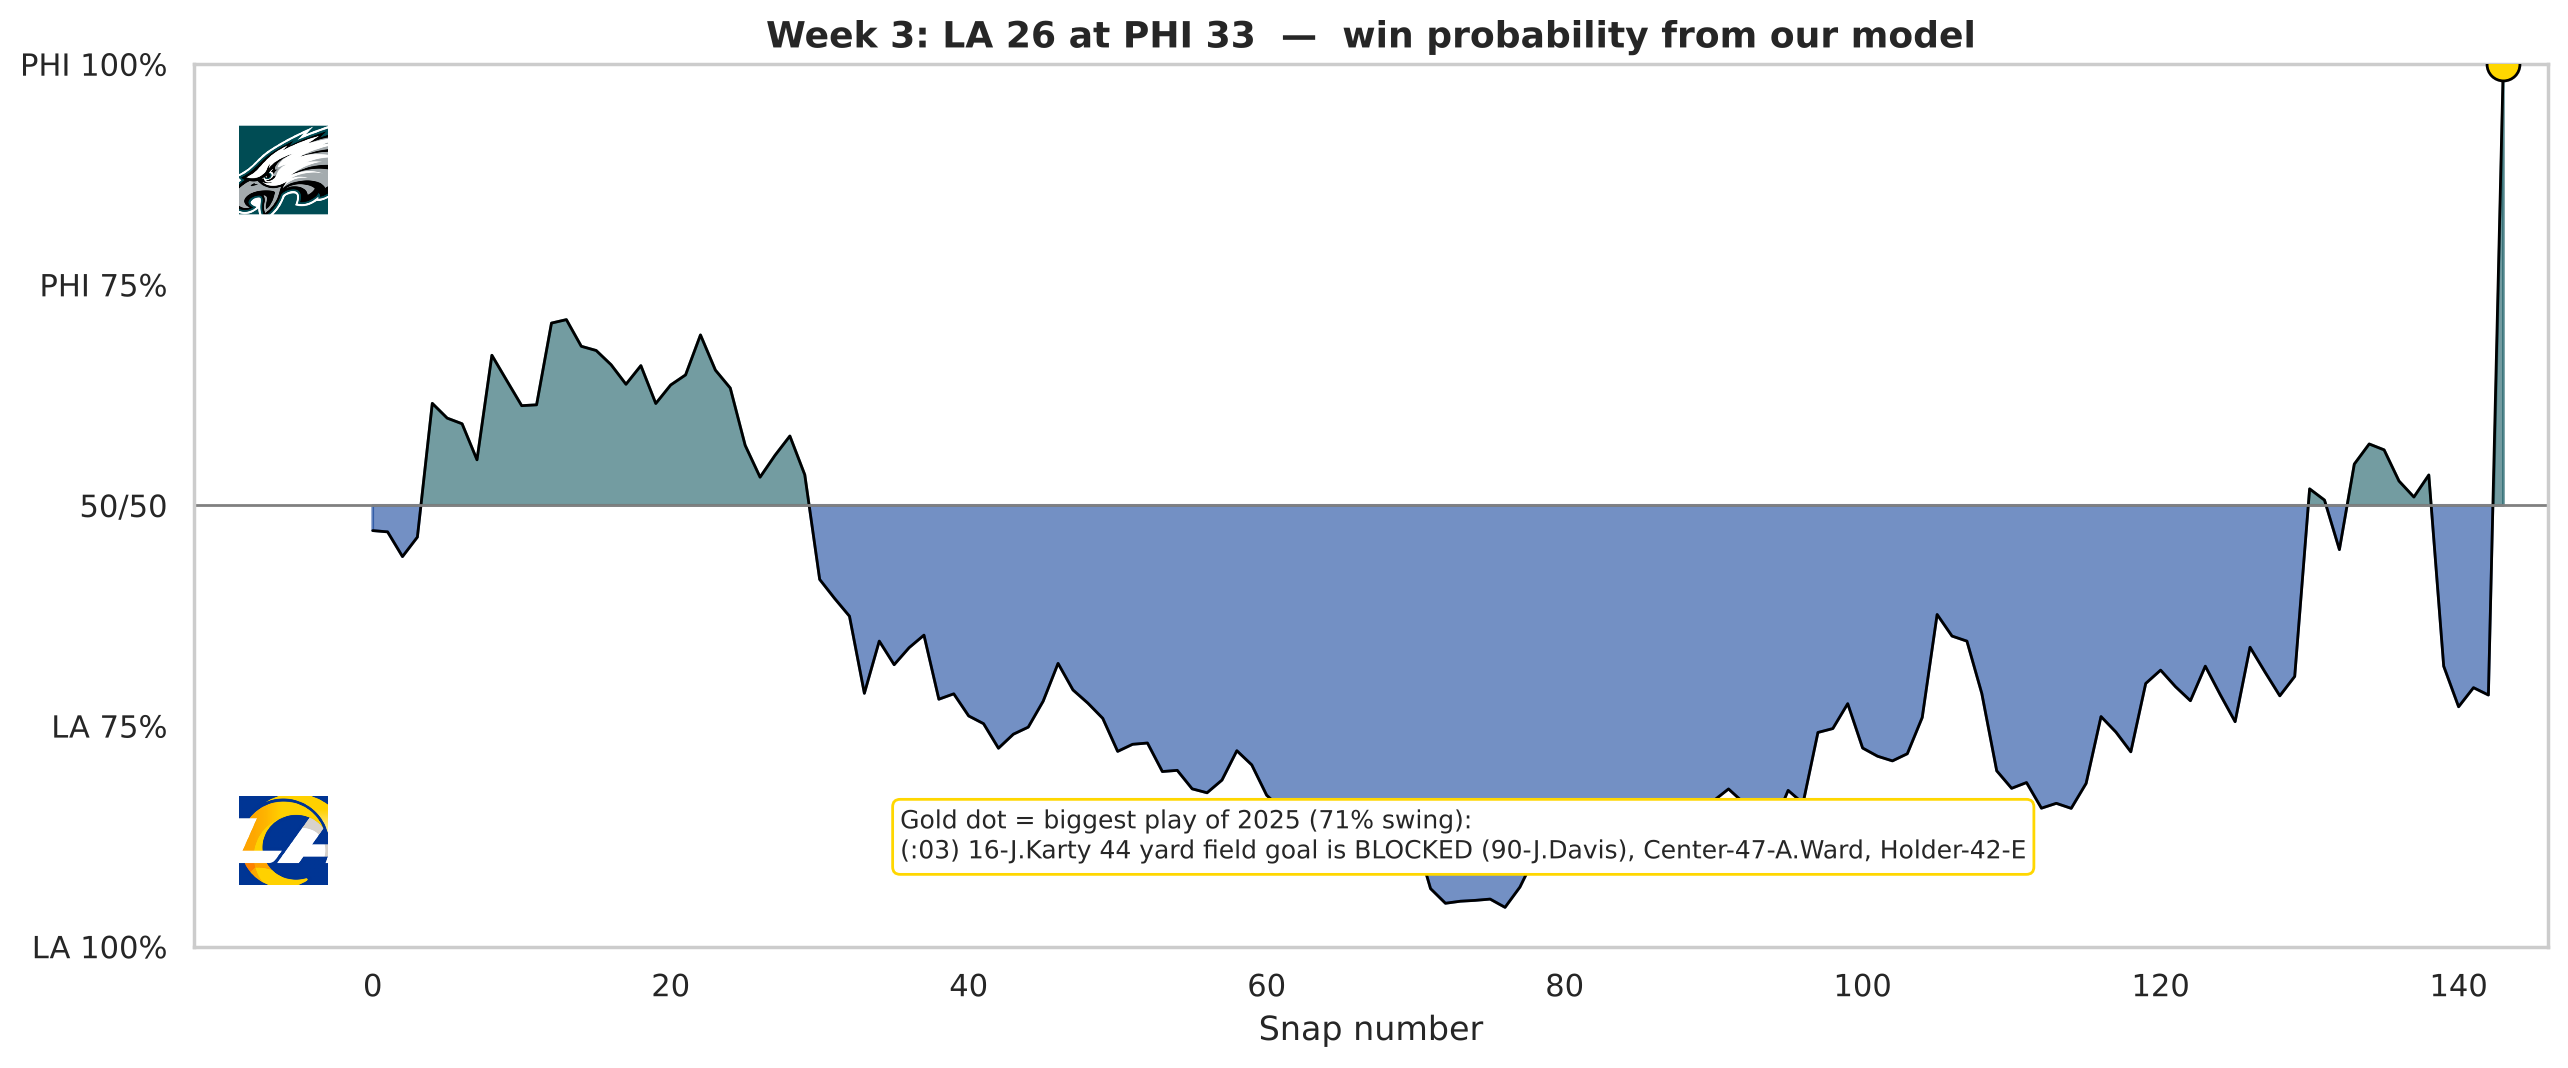

In [43]:
big = p25.loc[p25.wpa.abs().idxmax()]
game = g25[g25.game_id == big.game_id].reset_index(drop=True)
home, away = game.home_team.iloc[0], game.away_team.iloc[0]

# Home team's chance before every snap, plus the final result
home_wp = np.where(game.posteam == home, game.wp_before, 1 - game.wp_before)
final = 0.5 if big.game_id in ot_games else float(game.home_score.iloc[0] > game.away_score.iloc[0])
y = np.append(home_wp, final) * 100
x = np.arange(len(y))

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(x, 50, y, where=y >= 50, interpolate=True, color=COLOR[home], alpha=.55)
ax.fill_between(x, 50, y, where=y < 50,  interpolate=True, color=COLOR[away], alpha=.55)
ax.plot(x, y, color="black", lw=1)
ax.axhline(50, color="gray", lw=1)

i = game.index[game.play_id == big.play_id][0] + 1      # the point right after the big play
ax.scatter(i, y[i], s=140, color="gold", edgecolor="black", zorder=5)
ax.text(0.30, 0.10, f"Gold dot = biggest play of 2025 ({abs(big.wpa) * 100:.0f}% swing):\n{big.desc[:90]}",
        transform=ax.transAxes, fontsize=9, bbox={"boxstyle": "round", "fc": "white", "ec": "gold"})

ax.set_xlim(-12, len(y) + 2); ax.set_ylim(0, 100)
add_logo(ax, home, -6, 88, zoom=0.32)       # home team owns the top half
add_logo(ax, away, -6, 12, zoom=0.32)       # away team owns the bottom half
ax.set_yticks([0, 25, 50, 75, 100]); ax.set_yticklabels([f"{away} 100%", f"{away} 75%", "50/50", f"{home} 75%", f"{home} 100%"])
ax.set_title(f"Week {int(big.week)}: {away} {int(game.away_score.iloc[0])} at {home} {int(game.home_score.iloc[0])}  —  win probability from our model",
             fontsize=13, weight="bold")
ax.set_xlabel("Snap number"); ax.grid(False)
plt.tight_layout(); plt.show()

### Clutch quarterbacks: who added the most win probability?
Each quarterback gets the swing of every dropback (completions, incompletions, sacks, interceptions). Receivers and blockers share the credit, so think of this as "the passing game, with the QB's name on it".

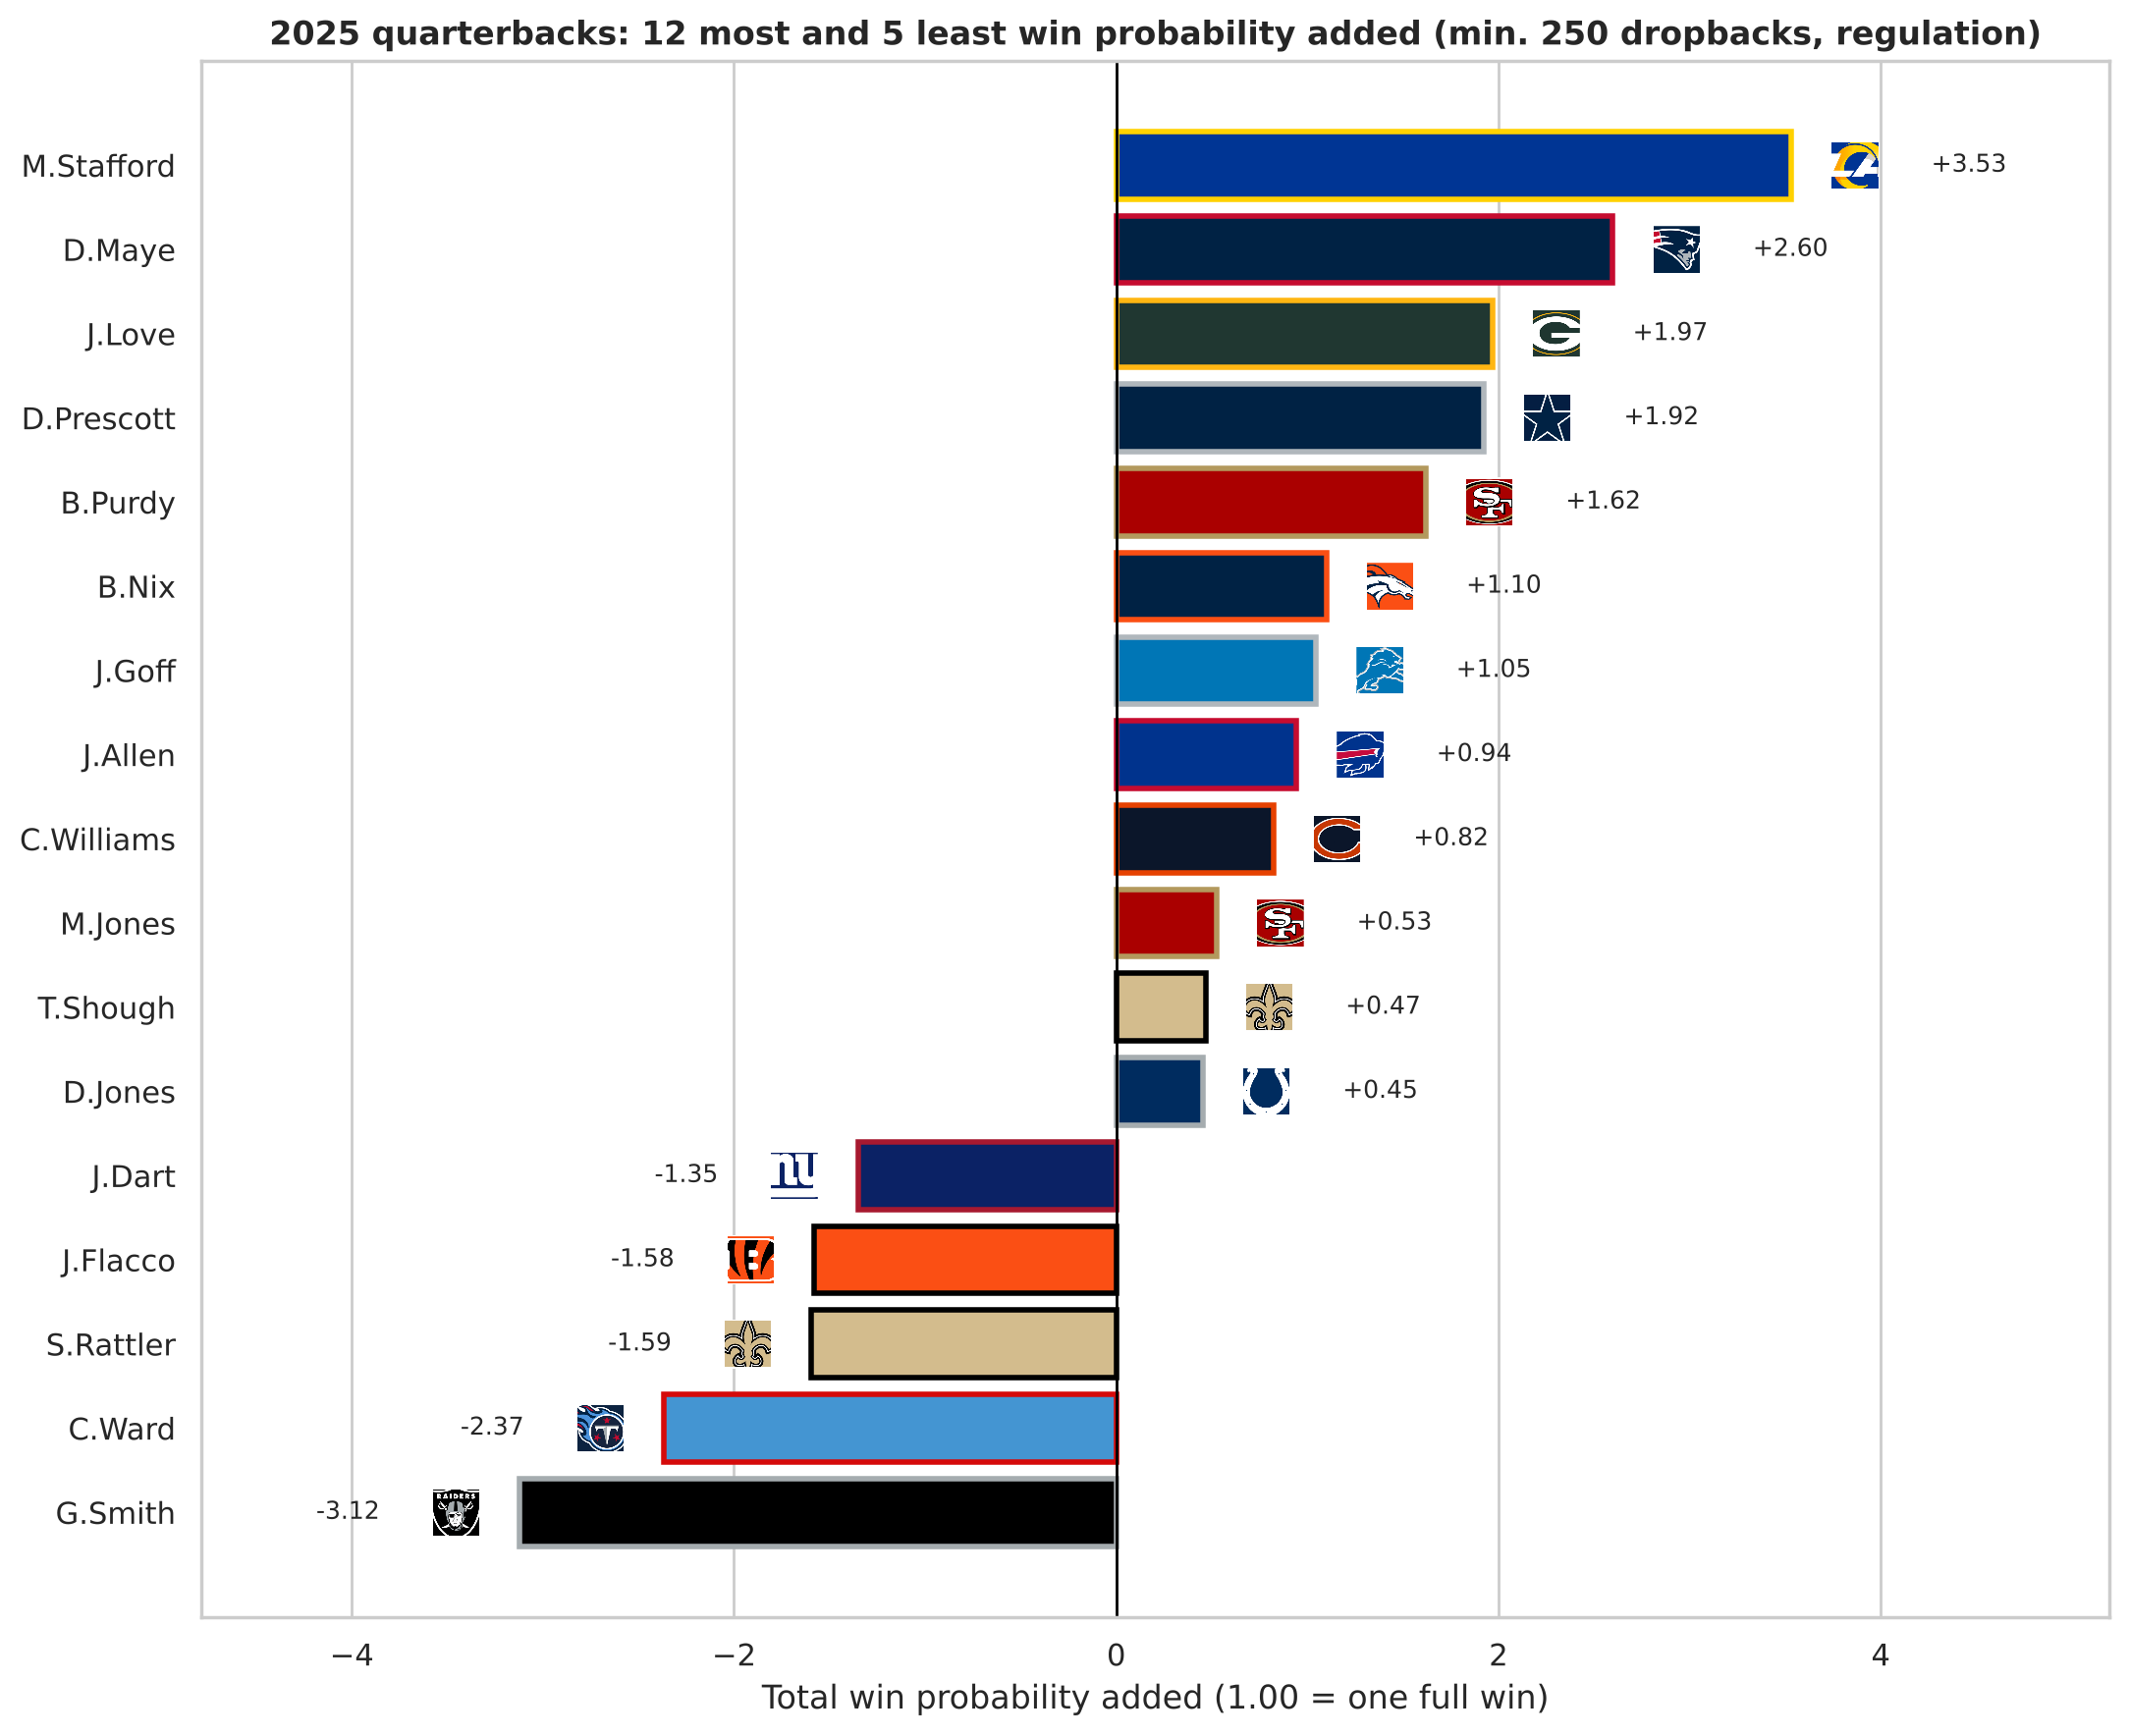

,team,dropbacks,total_wpa
passer_player_name,,,
M.Stafford,LA,606,3.530
D.Maye,NE,539,2.600
J.Love,GB,415,1.970
D.Prescott,DAL,581,1.920
B.Purdy,SF,295,1.620
B.Nix,DEN,629,1.100
J.Goff,DET,614,1.050
J.Allen,BUF,499,0.940
C.Williams,CHI,588,0.820


In [44]:
qb = p25[p25.passer_player_name.notna()]
qb_tbl = (qb.groupby("passer_player_name")
            .agg(team=("posteam", lambda t: t.mode()[0]), dropbacks=("wpa", "size"), total_wpa=("wpa", "sum"))
            .query("dropbacks >= 250")
            .sort_values("total_wpa"))

show = pd.concat([qb_tbl.head(5), qb_tbl.tail(12)]).drop_duplicates()   # 12 best + 5 worst
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(show.index, show.total_wpa, color=[COLOR.get(t, "gray") for t in show.team],
        edgecolor=[COLOR2.get(t, "white") for t in show.team], linewidth=2)
ax.axvline(0, color="black", lw=1)
xpad = (show.total_wpa.max() - show.total_wpa.min()) * 0.05
for k, (name, r) in enumerate(show.iterrows()):
    side = 1 if r.total_wpa >= 0 else -1
    add_logo(ax, r.team, r.total_wpa + side * xpad, k, zoom=0.17)
    ax.text(r.total_wpa + side * xpad * 2.2, k, f"{r.total_wpa:+.2f}", va="center",
            ha="left" if side > 0 else "right", fontsize=9)
ax.set_xlim(show.total_wpa.min() - xpad * 5, show.total_wpa.max() + xpad * 5)
ax.set_xlabel("Total win probability added (1.00 = one full win)")
ax.set_title("2025 quarterbacks: 12 most and 5 least win probability added (min. 250 dropbacks, regulation)",
             fontsize=12, weight="bold")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

qb_tbl.sort_values("total_wpa", ascending=False).head(12).round(2)

> 🔍 **Check your understanding:** Two QBs could have the same passing yards but very different WPA. How?

<details><summary><b>Click to reveal the answer</b></summary>

WPA weights each play by the situation. Yards in a 30-point blowout barely change win probability, while a 3rd-down conversion late in a tie game changes it a lot.

</details>

## Part 8 · The 2026 season so far

We plug each team's 2026 stats into the offense and defense models from Part 4. **Actual minus expected** shows which teams are scoring (or allowing) more or less than their stats suggest.

⚠️ After 8–9 games these numbers are noisy. Teams far from expected often **regress toward the middle** later in the season.

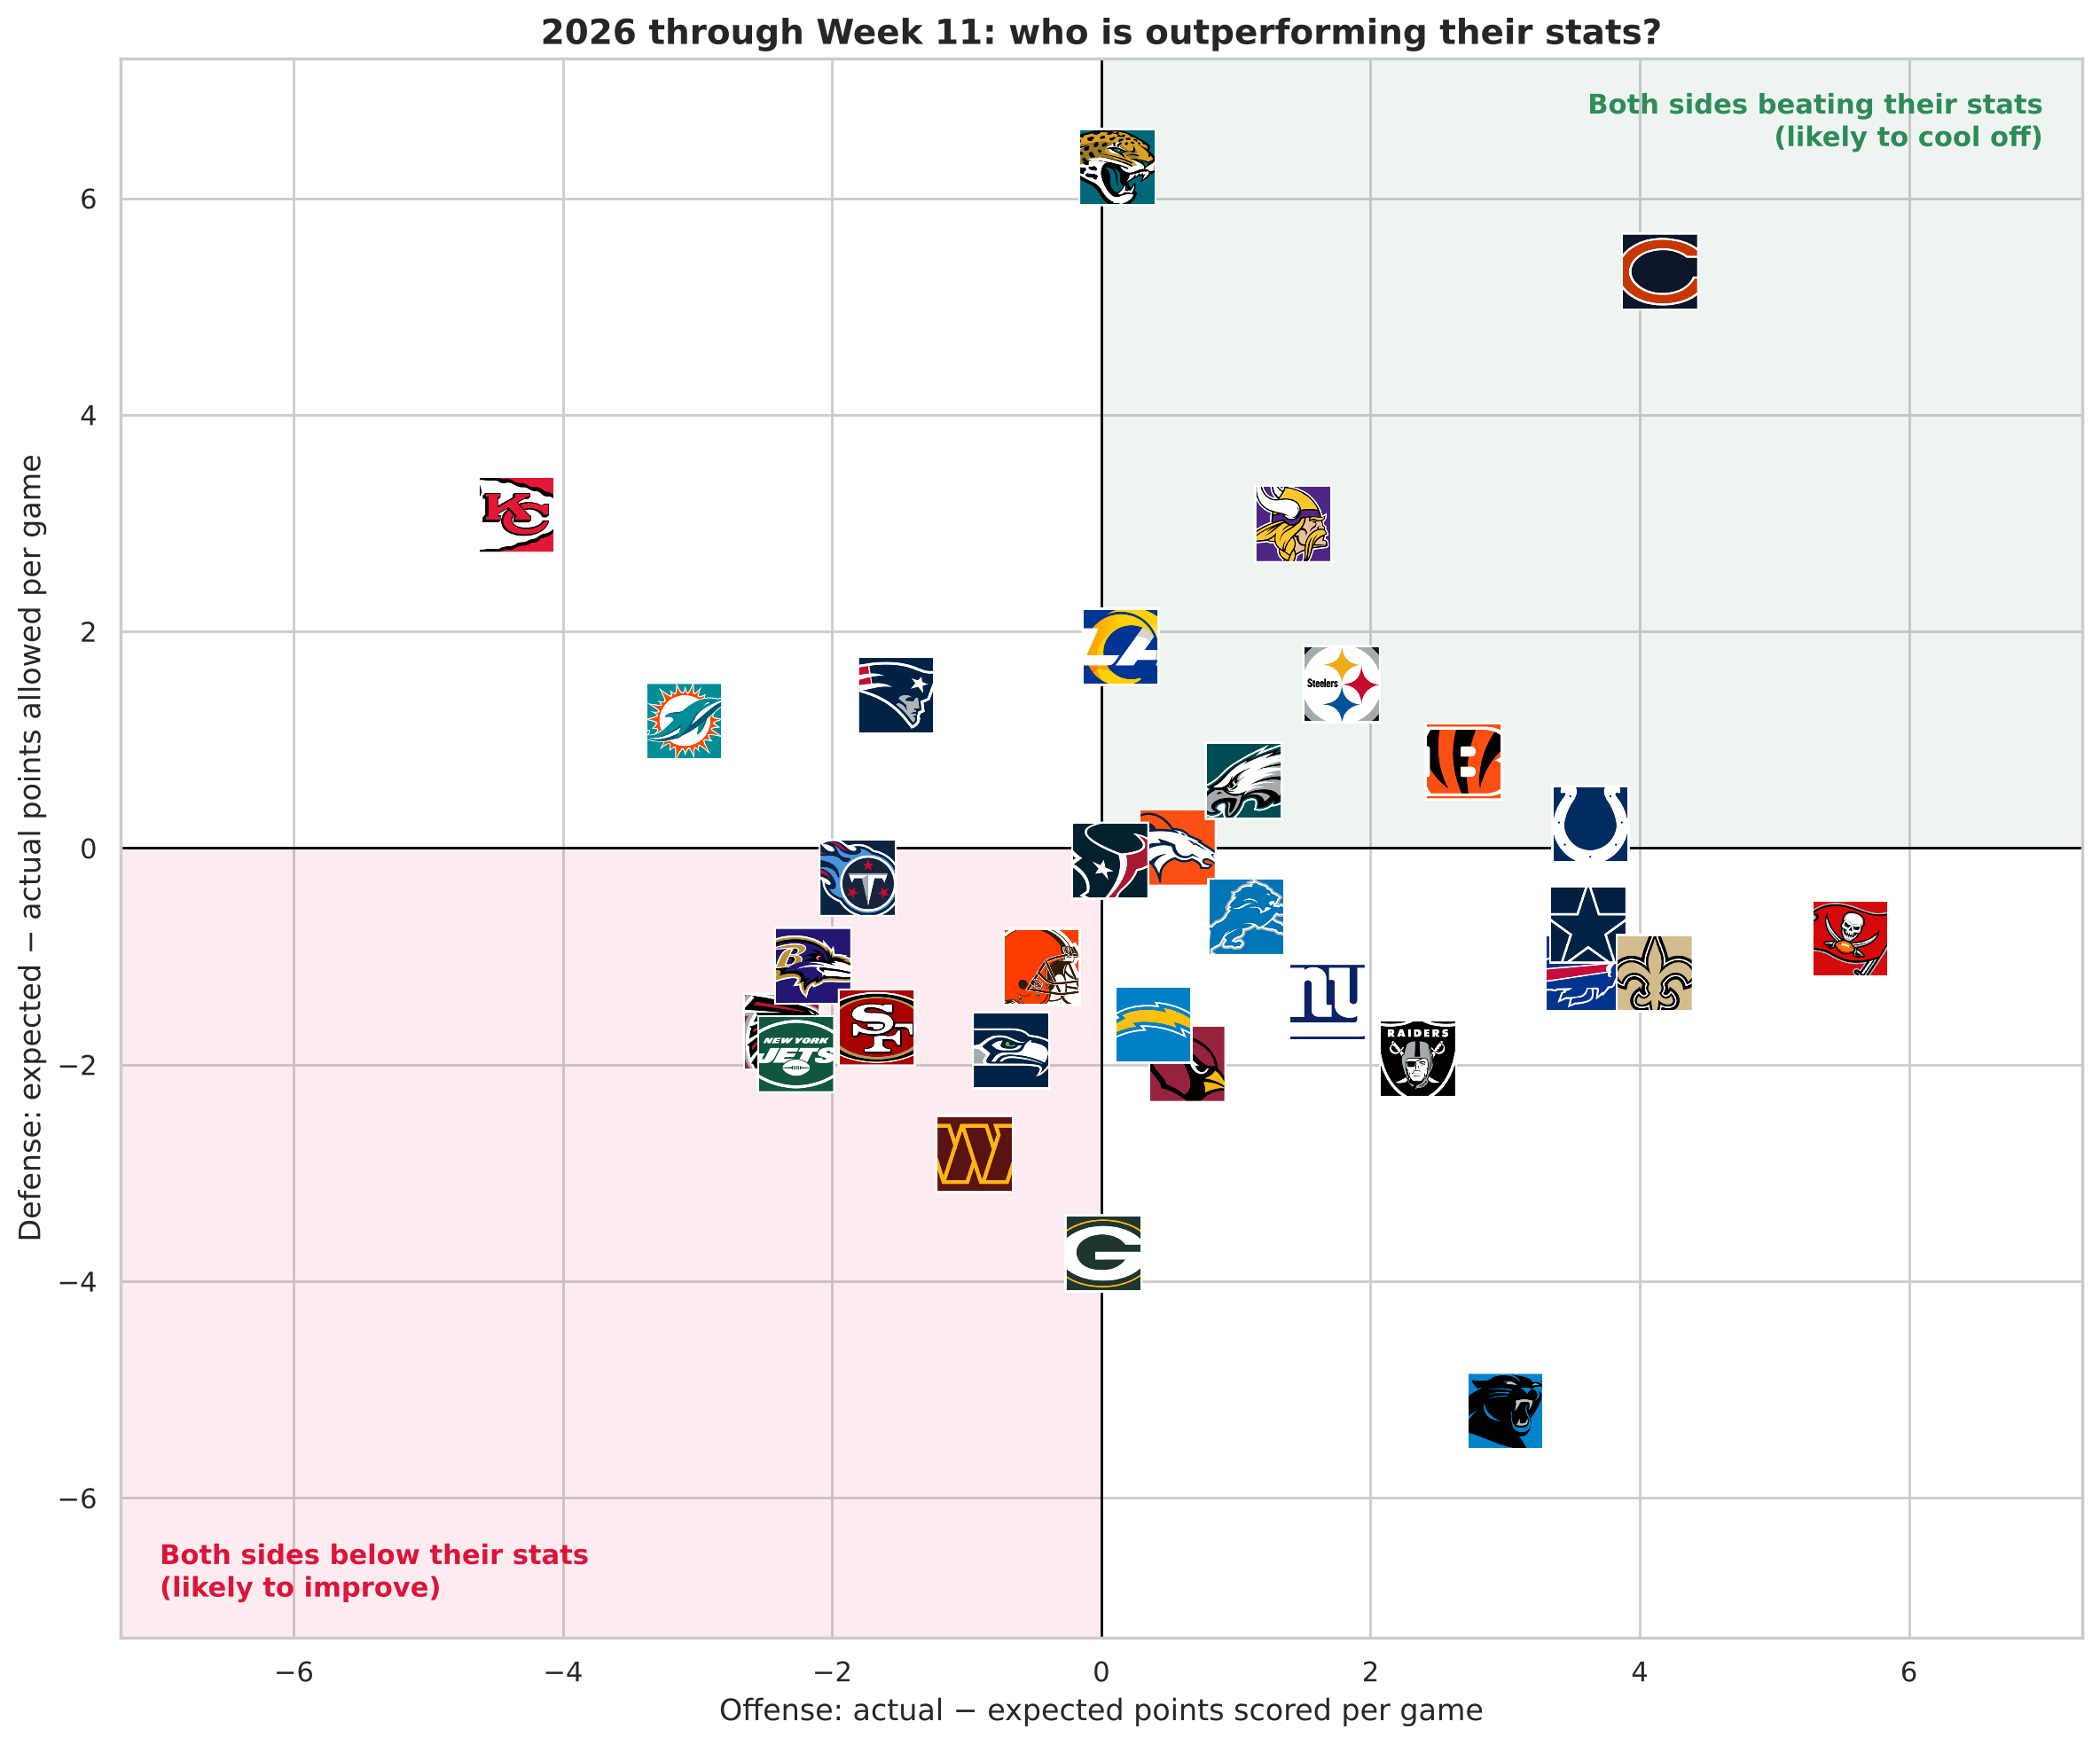

In [45]:
cur = current.copy()
cur["exp_ppg"]  = off_A.predict(cur)
cur["exp_papg"] = def_A.predict(cur)
cur["off_over"] = cur.ppg  - cur.exp_ppg     # + = scoring MORE than stats suggest
cur["def_over"] = cur.exp_papg - cur.papg    # + = allowing FEWER than stats suggest
cur["total_over"] = cur.off_over + cur.def_over
LATEST_WEEK = int(sched.loc[sched.season == CURRENT_SEASON, "week"].max())

fig, ax = plt.subplots(figsize=(12, 10))
lim = max(cur.off_over.abs().max(), cur.def_over.abs().max()) + 1
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.fill_between([0, lim], 0, lim, color="seagreen", alpha=.08)
ax.fill_between([-lim, 0], -lim, 0, color="crimson", alpha=.08)
ax.axhline(0, color="black", lw=1); ax.axvline(0, color="black", lw=1)
for _, r in cur.iterrows():
    add_logo(ax, r.team, r.off_over, r.def_over, zoom=0.30)
kw = dict(transform=ax.transAxes, fontsize=11, weight="bold")
ax.text(.98, .98, "Both sides beating their stats\n(likely to cool off)", ha="right", va="top", color="seagreen", **kw)
ax.text(.02, .02, "Both sides below their stats\n(likely to improve)", ha="left", va="bottom", color="crimson", **kw)
ax.set(xlabel="Offense: actual − expected points scored per game",
       ylabel="Defense: expected − actual points allowed per game")
ax.set_title(f"{CURRENT_SEASON} through Week {LATEST_WEEK}: who is outperforming their stats?", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

In [46]:
board = cur.sort_values("total_over", ascending=False).reset_index(drop=True)
board.insert(0, "logo", board.team)
board["record"] = [record(CURRENT_SEASON, t) for t in board.team]
cols = {"logo": "", "team": "Team", "record": "Record", "ppg": "PPG", "exp_ppg": "Exp PPG", "off_over": "Off +/-",
        "papg": "Opp PPG", "exp_papg": "Exp Opp PPG", "def_over": "Def +/-", "total_over": "Total +/-"}
board = board[list(cols)].rename(columns=cols)

v = board["Total +/-"].abs().max()
styled = (board.style
          .format({"": lambda t: logo_html(t, 30)}, escape=None)
          .format(precision=1, subset=list(board.columns[3:]))
          .background_gradient(cmap="RdYlGn", subset=["Off +/-", "Def +/-", "Total +/-"], vmin=-v, vmax=v)
          .set_properties(**{"text-align": "center", "font-family": "sans-serif"})
          .set_table_styles([{"selector": "th", "props": "background:#1f2937;color:white;padding:6px"}])
          .hide(axis="index"))
display(styled)

,Team,Record,PPG,Exp PPG,Off +/-,Opp PPG,Exp Opp PPG,Def +/-,Total +/-
,CHI,7-2,26.8,22.6,4.2,20.4,25.8,5.3,9.5
,JAX,7-2,29.9,29.8,0.1,16.0,22.3,6.3,6.4
,TB,3-6,22.4,16.9,5.6,19.8,18.9,-0.8,4.7
,MIN,7-2,19.6,18.1,1.4,14.0,17.0,3.0,4.4
,IND,3-8,19.2,15.5,3.6,27.0,27.2,0.2,3.9
,CIN,7-2,30.9,28.2,2.7,21.4,22.2,0.8,3.5
,PIT,6-3,22.0,20.2,1.8,20.2,21.7,1.5,3.3
,NO,3-6,22.4,18.3,4.1,26.2,25.1,-1.2,3.0
,DAL,4-6,28.6,25.0,3.6,28.2,27.5,-0.7,2.9
,BUF,8-1,31.9,28.3,3.6,22.1,21.0,-1.2,2.4


## Part 9 · Limitations and exercises

### What these models can't tell us
* **Explaining vs. forecasting.** The season models use stats from the same season as the points, so they explain *how* teams scored, not what will happen next year. (Exercise 4 tests that.)
* **Correlation isn't causation.** Teams that are winning big run the ball late to burn clock, so winning *causes* some of the rushing.
* **Rows aren't fully independent.** The same franchise appears every season, and plays from the same game are linked.
* **Points include non-offense scores.** Defensive and return touchdowns count in `ppg` even though our offense stats don't cause them.
* **Era effects.** Passing has become more efficient over time.
* **Our win-probability model is simple on purpose.** It covers regulation only (no overtime), ignores which team is better, and treats most inputs as having the same effect all game. It's accurate on average, but individual swings can be off.

### Checking the linear model's assumptions
Linear regression assumes the **residuals** (actual − predicted) are random noise: no pattern versus the fitted values, and roughly bell-shaped.

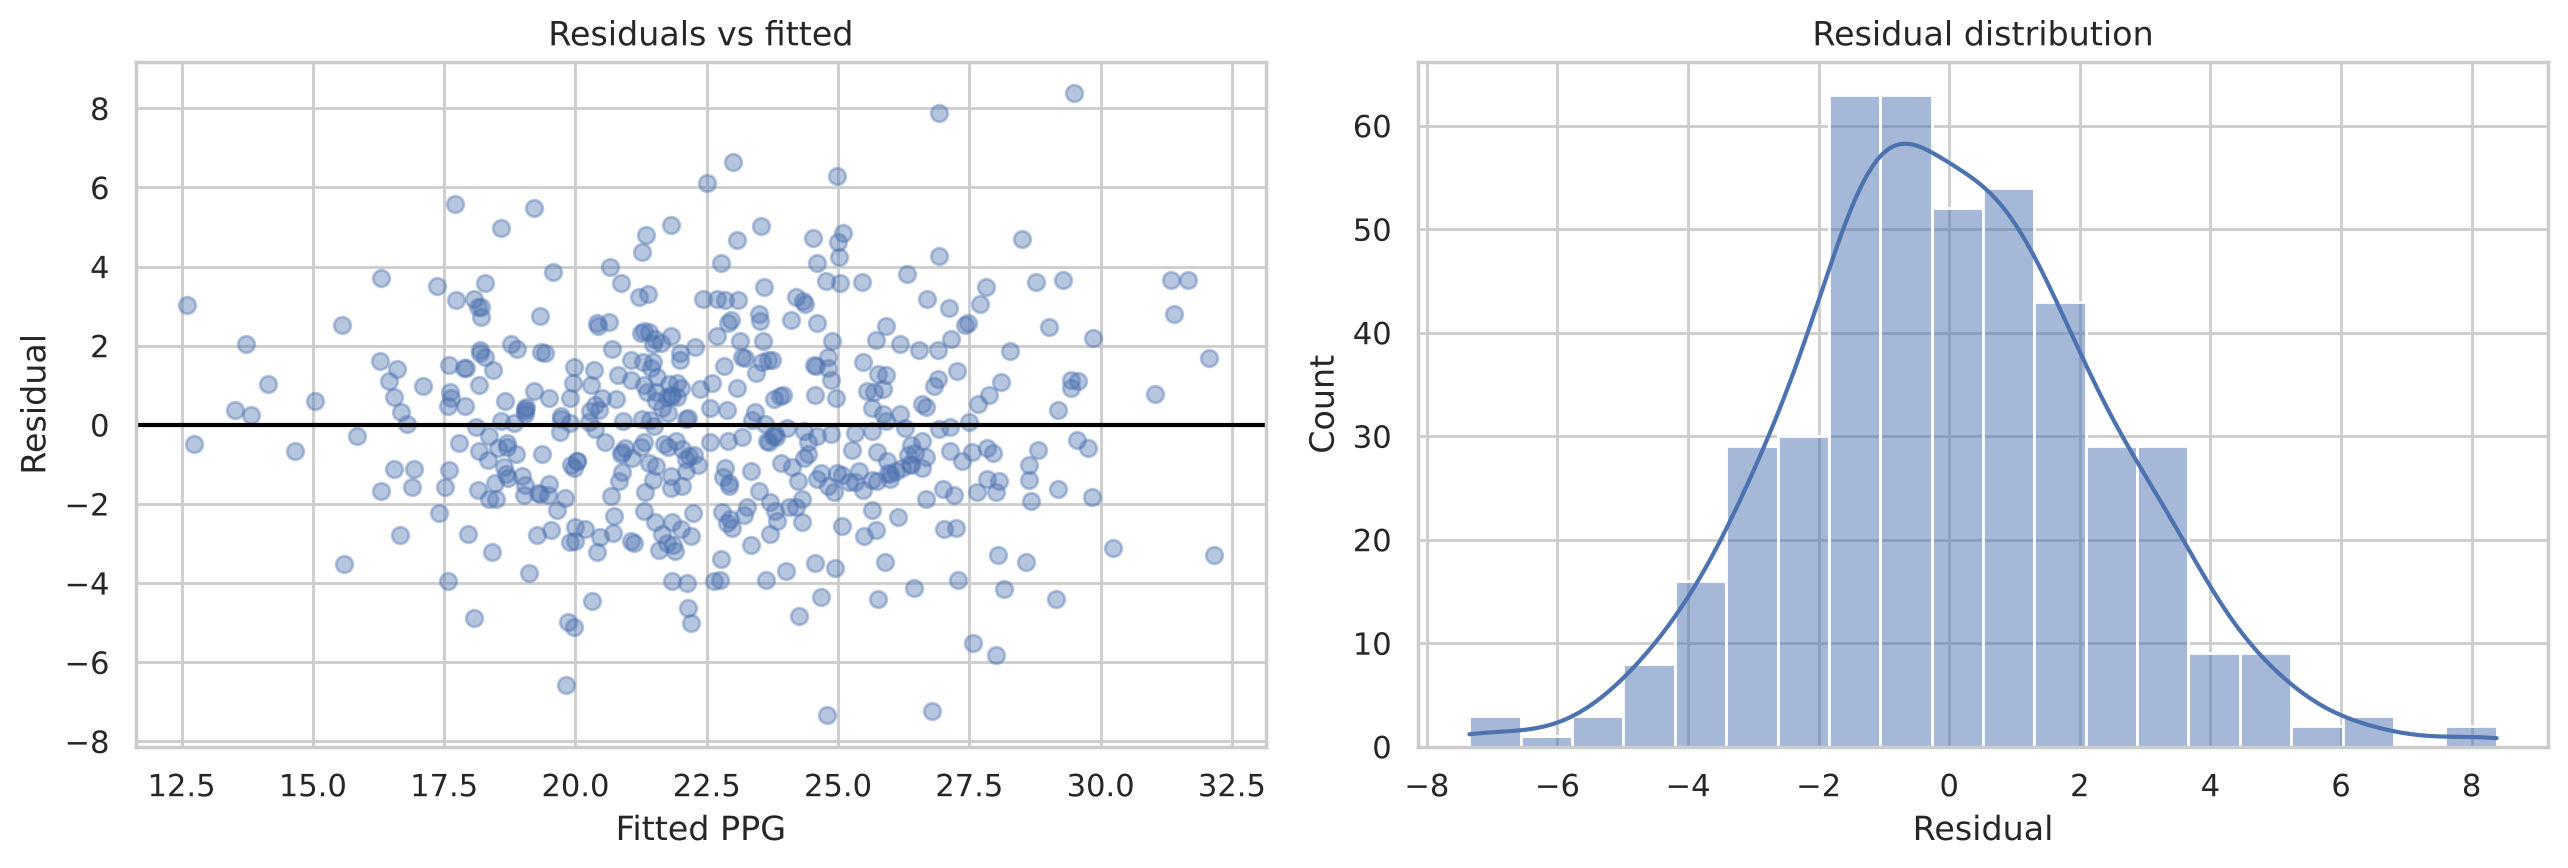

In [47]:
# Quick residual diagnostics for the offense model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(off_A.fittedvalues, off_A.resid, alpha=.4)
axes[0].axhline(0, color="black"); axes[0].set(title="Residuals vs fitted", xlabel="Fitted PPG", ylabel="Residual")
sns.histplot(off_A.resid, kde=True, ax=axes[1]); axes[1].set(title="Residual distribution", xlabel="Residual")
plt.tight_layout(); plt.show()

### ✏️ Exercises

**Linear regression**
1. **Add a variable.** Pick a stat from `games.columns` (for example `passing_air_yards` or `passing_yards_after_catch`), build its season rate, add it to the offense model, and check whether the **test MAE** improves.
2. **Symmetry test.** Is a takeaway worth the same as a giveaway avoided? Run `combo.t_test("def_to_pg + off_to_pg = 0")` and interpret the p-value.
3. **Era adjustment.** Add `C(season)` to the offense model. How does the passing coefficient change? What does that say about league-wide trends?
4. **True prediction.** Use each team's stats from season *t* to predict its points per game in season *t + 1* (hint: `groupby("team").shift(1)`). How much does R² drop?

**Logistic regression**

5. **Remove the interaction.** Refit `wp_model` without `lead_per_time`. How much worse is the 2025 Brier score, and what happens to the what-if table in Part 6, Step 6?
6. **Home field.** Create `home = (posteam == home_team).astype(int)`, add it to the model, and use a what-if to show how much playing at home is worth in win probability.
7. **Your own situation.** Use `win_prob()` to find how big a lead a team needs with 5 minutes left to have a 90% chance of winning.

**Plays and players**

8. **Clutch receivers.** Repeat the clutch-QB chart using `p25` and `receiver_player_name` (targets instead of dropbacks). Who are the most clutch pass catchers?
9. **Pick a 2026 team** that is far from expected in Part 8. Argue whether the gap is skill (red zone, kicker, scheme) or luck.